# GPU‑парк OpenAI и Anthropic: сколько и как делится между обучением и инференсом

Ноутбук отвечает на вопрос **«Сколько GPU у OpenAI и Anthropic и как они делят их между обучением и инференсом?»** и собирает все материалы для CTO: отчёт с источником у каждого числа, данные и макет слайда, пакет для дизайнера и подробный документ с приложениями.

## Что делает ноутбук

| Блок | Что получается |
|---|---|
| 1 | реестр источников с URL, датами доступа и статусами проверки |
| 2 | загрузка CSV Epoch AI (SHA‑256), воспроизведение моделей Epoch на чистом NumPy, Монте‑Карло‑оценка парка на дату слайда, перекрёстная проверка «по вводам», чувствительность |
| 3 | единая таблица пересчёта ГВт ↔ чипы ↔ H100e, оценка числа физических ускорителей, две контрольные точки |
| 4 | сплит расходов «обучение и исследования / инференс» 2024–2026 на одном базисе, сценарии 2026 |
| 5 | `slide_data.json`, `slide_spec.md`, `slide.html` (макет слайда), `report_cto.html` (отчёт для CTO), `slide_brief/` (пакет для дизайнера) |
| 6 | `draft_v2.md` — подробный документ с приложениями, `changelog_v2.md`, автоматическая проверка «нет числа без ссылки» |
| 7 | сводка: ответ в трёх строках, список файлов, критерии приёмки |

## Как запустить

* Зависимости: Python ≥ 3.9, `numpy`, `pandas`, `matplotlib`, Jupyter (`pip install -r requirements.txt`). Ничего другого не требуется.
* Все входные данные (реестр источников, ключевые числа, исходный документ, таблица парка Microsoft из данных Epoch, копии CSV Epoch) **встроены в ноутбук**; при наличии сети свежие CSV Epoch скачиваются и сверяются с встроенной копией по SHA‑256.
* Выход — папка `gpu_fleet_review_out/` рядом с ноутбуком: `data/`, `results/`, `draft_original.md`, `draft_v2.md`, `calc_nowcast.py`, `calc_chips.py`, `calc_split.py` (каждый скрипт запускается и отдельно: `python calc_nowcast.py`).
* Дата слайда зафиксирована: `NOWCAST_DATE = 2026‑09‑27` (можно переопределить переменной окружения). Все Монте‑Карло детерминированы (`SEED`).
* Исходники ячеек — в `notebook_src/cells/`; пересборка ноутбука: `python3 notebook_src/build.py`.

## Статусы фактов

`[V]` — проверено по первоисточнику 27.09.2026 · `[V2]` — подтверждено надёжной вторичной прессой · `[N]` — не проверено · `[E]` — оценка или модель · `[X]` — противоречит источникам.

In [1]:
# ---------------------------------------------------------------- параметры
import os, io, re, json, math, hashlib, textwrap, datetime as dt, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Markdown, HTML, display

NOWCAST_DATE = dt.date.fromisoformat(os.environ.get('NOWCAST_DATE', '2026-09-27'))  # дата слайда (зафиксирована; переопределяется переменной окружения)
ACCESSED     = '2026-09-27'          # дата проверки источников (реестр собран и проверен в этот день)
SEED         = 20260927              # фиксированный seed всех Монте-Карло
N_MC         = 200_000               # прогонов Монте-Карло
ONLINE       = os.environ.get('ONLINE', '1') == '1'   # пытаться ли скачивать CSV Epoch
OUT          = Path('gpu_fleet_review_out')           # выходная папка (фиксирована: на неё ссылаются %%writefile)
for sub in ['data/epoch', 'results']:
    (OUT / sub).mkdir(parents=True, exist_ok=True)

DATE_TAG = NOWCAST_DATE.isoformat()
pd.set_option('display.max_colwidth', 120)
pd.set_option('display.width', 200)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'font.size': 10})
print(f'NOWCAST_DATE = {NOWCAST_DATE}   ACCESSED = {ACCESSED}   SEED = {SEED}   N_MC = {N_MC:,}   ONLINE = {ONLINE}')
print(f'Выход: {OUT.resolve()}')

NOWCAST_DATE = 2026-09-27   ACCESSED = 2026-09-27   SEED = 20260927   N_MC = 200,000   ONLINE = True
Выход: /Users/artem.vasilyev/proj/uneml_viktor_openai/gpu_fleet_review_out


In [2]:
# ---------------------------------------------------------------- хелперы (общие для всех блоков)
Z90 = 1.6448536269514722   # 95-й процентиль N(0,1): 90 % интервал = [p05, p95]

def lognorm_ci(lo, hi, n, rng):
    """Лог-нормальное с 5-м = lo и 95-м = hi процентилем (аналог squigglepy `to(lo, hi)`, которым пользуется Epoch)."""
    mu = (math.log(lo) + math.log(hi)) / 2
    sigma = (math.log(hi) - math.log(lo)) / (2 * Z90)
    return np.exp(rng.normal(mu, sigma, n))

def lognorm_med_ci(med, lo, hi, n, rng):
    """Лог-нормальное по медиане и 90 % ДИ (sigma — из отношения p95/p05; медиана фиксируется точно)."""
    sigma = (math.log(hi) - math.log(lo)) / (2 * Z90)
    return np.exp(rng.normal(math.log(med), sigma, n))

def norm_ci(lo, hi, n, rng, lclip=None, rclip=None):
    """Нормальное с 90 % интервалом [lo, hi], с обрезкой (аналог squigglepy `norm(lo, hi, lclip, rclip)`)."""
    x = rng.normal((lo + hi) / 2, (hi - lo) / (2 * Z90), n)
    if lclip is not None: x = np.maximum(x, lclip)
    if rclip is not None: x = np.minimum(x, rclip)
    return x

def pct(x, qs=(5, 25, 50, 75, 95)):
    """Словарь процентилей p05…p95."""
    v = np.percentile(np.asarray(x), qs)
    return {f'p{q:02d}': float(a) for q, a in zip(qs, v)}

def ru(x, nd=2):
    """Число в русской записи: запятая как десятичный разделитель, тонкий пробел между тысячами."""
    if x is None or (isinstance(x, float) and math.isnan(x)): return '—'
    s = f'{x:,.{nd}f}'.replace(',', ' ').replace('.', ',')
    return s

def ru_m(x, nd=2):   return ru(x / 1e6, nd) + ' млн'      # H100e / чипы → «1,74 млн»
def ru_k(x, nd=0):   return ru(x / 1e3, nd) + ' тыс.'     # → «509 тыс.»
def ru_gw(x, nd=1):  return ru(x / 1000, nd) + ' ГВт'     # МВт → «1,9 ГВт»
def ru_b(x, nd=1):   return '$' + ru(x, nd) + ' млрд'    # млрд USD

def save_json(obj, path):
    Path(path).write_text(json.dumps(obj, ensure_ascii=False, indent=2, default=float), encoding='utf-8')
    return path

def write_text(text, path):
    Path(path).write_text(text, encoding='utf-8'); return path

def sha256_file(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def md(text):
    display(Markdown(text))

print('helpers ok')

helpers ok


## Блок 1 · Реестр источников: URL, даты доступа, статусы; свежие источники

Реестр `data/sources_2026-09-27.csv` встроен ниже: 47 исходных записей S01–S47 дополнены результатами проверки первоисточников 27.09.2026 (пресс‑релизы, посты, отчётность), добавлена колонка `accessed` и новые записи S48+ (DeepSeek‑V3 tech report, DeepSeek‑R1 в Nature, публикации после 20.09.2026). Записи со статусом `K` переведены в `V` (первоисточник открыт) или `V2` (первоисточник за пейволлом или недоступен, содержание подтверждено надёжной прессой). Расхождения формулировок зафиксированы в `note`.

Ниже: реестр как DataFrame, сводка изменений, список записей, у которых первоисточник **не открылся** (для них статус не выше `V2`).

In [3]:
# ---------------------------------------------------------------- Блок 1: реестр источников
SOURCES_ORIGINAL_CSV = r"""id,date,publisher,title,url,supports,status,note
S01,2026-01-18,OpenAI (Sarah Friar),A business that scales with the value of intelligence,https://openai.com/index/a-business-that-scales-with-the-value-of-intelligence/,0.2/0.6/~1.9 GW на конец 2023/2024/2025; ARR $2B/$6B/$20B+; диверсификация провайдеров,V2,URL из методологии Epoch; пересказ DCD; страницу открыть и зафиксировать дату публикации (18 или 19.01.2026)
S02,2026-09-09,Epoch AI (Josh You),Introducing the AI Chip Users explorer,https://epoch.ai/latest/introducing-the-ai-chip-users-explorer,медианы и 90% ДИ H100e пяти лабораторий на конец 2025; OpenAI 103k/386k/1.7M; сплит OpenAI 2025 ~50/50,V,
S03,2026-09-09,Epoch AI,"Data on AI chip users (explorer, CSV, ZIP)",https://epoch.ai/data/ai-chip-users,определение H100e; CSV year_end_by_lab и intermediates_by_lab; ZIP,V,CSV: https://epoch.ai/data/ai_chip_users_year_end_by_lab.csv ; https://epoch.ai/data/ai_chip_users_intermediates_by_lab.csv
S04,2026-09,Epoch AI,AI Chip Users — Methodology,https://epoch.ai/data/ai-chip-users-documentation/methodology,параметры моделей OpenAI/Anthropic; Вт и H100e на чип; Hopper:Blackwell 1.48:1; сторонний инференс; $16.3B cloud spend 2025; Rainier 470k H100e; Colossus ~280k H100e; Appendix 2026,V,код: https://github.com/epoch-research/ai-compute-users
S05,2026-05-20,Epoch AI (Josh You),Frontier labs don't use most AI compute (yet),https://epoch.ai/gradient-updates/frontier-labs-dont-use-most-ai-compute,OpenAI ~10–15% мирового операционного AI-compute; мир ~20M H100e; Anthropic >1M H100e,V,подтверждено по сниппету поиска
S06,2026-02-04,Epoch AI,Compute accounts for the majority of expenses of AI companies,https://epoch.ai/data-insights/company-spending-breakdown,"Anthropic 2025: R&D compute $4.1B, инференс $2.7B (из 40% GM при выручке $4.5B), compute $6.8B, всего $9.7B",V,CSV обновлён 16.02.2026
S07,2025-10-10,Epoch AI,Most of OpenAI's 2024 compute went to experiments,https://epoch.ai/data-insights/openai-compute-spend,"OpenAI 2024: обучение $3B, инференс $1.8B, исследования $1B амортизировано; R&D ~$5B, инференс ~$2B",V,
S08,2026-03-23,Epoch AI,Final training runs account for a minority of R&D compute spending,https://epoch.ai/gradient-updates/r-and-d-vs-training-compute,"финальные прогоны — меньшая часть R&D compute (OpenAI, MiniMax, Z.ai)",V,по сниппету
S09,2026-01-28,Epoch AI,Can AI companies become profitable?,https://epoch.ai/gradient-updates/can-ai-companies-become-profitable,"OpenAI 2025 инференс >$8B (The Information), ~$4.5B на платных пользователей; 2024 инференс+хостинг $2.4B; Anthropic GM ~40%",V,по сниппету
S10,2026-08-27,Epoch AI,Data on AI Chip Sales (H100e definition),https://epoch.ai/data/ai-chip-sales,H100e = плотные 8-бит операции / H100; TPUv7 ~2.3 H100e,V,
S11,2026-04-09,Bloomberg (Shirin Ghaffary); Key Context (Tae Kim),OpenAI tells investors it has computing advantage over Anthropic; memo 'Compute is the ballgame',https://www.bloomberg.com/news/articles/2026-04-09/openai-tells-investors-it-has-computing-advantage-over-anthropic,"Anthropic 1.4 GW (2025), 3–4 GW (2026), 7–8 GW (2027); OpenAI >8 GW идентифицировано, 30 GW к 2030",V2,пересказ: https://taekim.substack.com/p/exclusive-openai-highlights-massive ; формулировку 'low double-digit GW 2027' проверить
S12,2026-04-30,Bloomberg (Dina Bass); The Decoder,OpenAI reaches 10-gigawatt AI capacity milestone years ahead of target,https://www.bloomberg.com/news/articles/2026-04-30/openai-meets-key-ai-computing-capacity-goal-ahead-of-schedule,"10 GW законтрактовано в США; >3 GW за 90 дней, 2 GW от Amazon; отказ от расширения Абилина, пауза UK, выход из Норвегии",V2,https://the-decoder.com/openai-says-it-hit-its-10-gigawatt-compute-goal-years-ahead-of-schedule/ ; первоисточник — блог OpenAI 29.04.2026 (найти URL)
S13,2026-05-05,Bloomberg,"OpenAI to spend $50 billion on computing in 2026, Brockman says",https://www.bloomberg.com/news/articles/2026-05-05/openai-to-spend-50-billion-on-computing-in-2026-brockman-says,$50B compute в 2026 (с $30M в 2017); контекст $600B до 2030,V2,пересказ Yahoo: https://finance.yahoo.com/sectors/technology/articles/openai-spend-50-billion-computing-191336356.html
S14,2026-02-20,Reuters,OpenAI expects compute spend of around $600 billion through 2030,https://finance.yahoo.com/news/openai-sees-compute-spend-around-223950561.html,~$600B compute до 2030; выручка 2025 $13B; инференс x4 в 2025; adj. GM 33% (40% в 2024); NVIDIA $30B,V2,зеркало Reuters на Yahoo
S15,2026-02-21,The Decoder (по The Information),OpenAI adds $111 billion to its cash burn forecast,https://the-decoder.com/openai-adds-111-billion-to-its-cash-burn-forecast-as-ai-costs-spiral-beyond-projections/,"обучение $32B (2026), ~$65B (2027), ~$440B до 2030; выручка $13.1B (2025), $30B (2026), $62B (2027); кэш-бёрн $25B/$57B; GM 33%/40%/цель 46%",V,первоисточник The Information за пейволлом
S16,2026-07-29,Sacra,"OpenAI revenue, valuation & funding",https://sacra.com/c/openai/,"инференс $8.4B (2025) → $14.1B (2026); GM 33%; Broadcom 10 GW к концу 2029, чип Jalapeño; Cerebras 750 MW до 2028",V2,винтаж прогноза $14.1B — до февральского пересмотра
S17,2026-02-20,Financial Times via Business Standard,Nvidia $30bn OpenAI investment after shelving $100bn deal,https://www.business-standard.com/technology/tech-news/nvidia-30bn-openai-investment-after-shelving-100bn-deal-126022000503_1.html,LOI $100B не оформлен; $30B прямая инвестиция в раунде >$100B; $730B pre-money,V2,также https://www.techtimes.com/articles/317839/20260605/nvidia-openai-investment-shrinks-100b-30b-compute-lock-war-continues.htm
S18,2025-09-22,NVIDIA/OpenAI press release (mirror),OpenAI and NVIDIA announce strategic partnership to deploy 10 gigawatts,https://www.barchart.com/story/news/34958327/openai-and-nvidia-announce-strategic-partnership-to-deploy-10-gigawatts-of-nvidia-systems,"LOI ≥10 GW, до $100B поэтапно, первый GW — 2H 2026 на Vera Rubin",V2,оригинал на nvidianews.nvidia.com — заменить URL
S19,2025-09-23,OpenAI,"OpenAI, Oracle, and SoftBank expand Stargate with five new AI data center sites",https://openai.com/index/five-new-stargate-sites/,"почти 7 GW плана, >$400B; Oracle 4.5 GW (июль 2025); площадка в Висконсине",V,
S20,2026-02-27,OpenAI/Amazon (Business Wire),OpenAI and Amazon Announce Strategic Partnership,https://secure.businesswire.com/news/home/20260227557827/en/OpenAI-and-Amazon-Announce-Strategic-Partnership,"$50B инвестиция ($15B + $35B условно); +$100B к $38B за 8 лет; ~2 GW Trainium (Trainium3/4, 2027)",V,
S21,2026-04-27,OpenAI,The next phase of the Microsoft OpenAI partnership,https://openai.com/index/next-phase-of-microsoft-partnership,Microsoft — основной облачный партнёр; продукты в любом облаке; лицензия неэксклюзивна до 2032; Microsoft не платит долю выручки; доля OpenAI→MSFT до 2030 с потолком,V,потолок ~$38B — по прессе (Yahoo/Bloomberg)
S22,2026-06-08,OpenAI; CNBC; Fortune,Confidential submission of draft S-1,https://openai.com/index/openai-submits-confidential-s-1/,OpenAI S-1 объявлен 08.06.2026 (по прессе подан ~22.05); Anthropic — 01.06.2026 при $965B; SpaceX roadshow; $852B post-money,V,CNBC: https://www.cnbc.com/2026/06/08/openai-confidentially-files-for-ipo-prepping-wall-street-for-ai-debut.html ; Fortune: https://fortune.com/2026/06/09/openai-files-confidential-s-1-sec-ipo/
S23,2026-04,Cerebras S-1 (SEC); DCD,Cerebras Form S-1; OpenAI CFO says company ended 2025 with 1.9GW,https://www.sec.gov/Archives/edgar/data/2021728/000162828026025762/cerebras-sx1april2026.htm,"MRA и варрант OpenAI (дек. 2025), заём $1B (янв. 2026); DCD: $250B Azure, CoreWeave $22.4B, Cerebras $10B, Oracle $300B/5 лет, AWS $38B",V/V2,DCD: https://datacenterdynamics.com/en/news/openai-cfo-says-company-ended-2025-with-19gw-of-compute-scaled-revenue-at-same-speed/
S24,2026-08-17,SiliconANGLE; Axios; DCD; SB Energy S-1,OpenAI leases 10-gigawatt AI data center campus from SoftBank's SB Energy,https://siliconangle.com/2026/08/17/openai-leases-10-gigawatt-ai-data-center-campus-from-softbanks-sb-energy/,"20-летняя аренда PORTS-Pike (Огайо): ~8 GW IT, ≥10 GW генерации; NVIDIA backstop до $105B; первая фаза ~800 MW в 2028; ≥$500B полная стоимость",V2,Axios: https://axios.com/2026/08/17/openai-nvidia-ohio-data-center-sb-energy ; DCD (июнь): https://www.datacenterdynamics.com/en/news/openai-in-talks-to-lease-10gw-data-center-from-sb-energy-in-ohio/ ; SB Energy S-1: https://www.sec.gov/Archives/edgar/data/0002133037/000162828026059639/sbenergy-sx1.htm ; найти пост OpenAI
S25,2026-04-20,Anthropic; Amazon,Anthropic and Amazon expand compute collaboration,https://www.anthropic.com/news/anthropic-amazon-compute,до 5 GW; >$100B за 10 лет; >1M Trainium2; ~1 GW Trainium2/3 к концу 2026; Amazon $5B + до $20B; run-rate >$30B,V,Amazon: https://www.aboutamazon.com/news/company-news/amazon-invests-additional-5-billion-anthropic-ai
S26,2026-04-06,Anthropic; TNW; Broadcom 8-K,Anthropic expands partnership with Google and Broadcom for multiple gigawatts,https://anthropic.com/news/google-broadcom-partnership-compute,несколько GW TPU с 2027; ~3.5 GW по 8-K Broadcom; run-rate >$30B (с ~$9B на конец 2025); >1000 клиентов >$1M,V,TNW: https://thenextweb.com/news/anthropic-google-broadcom-compute-deal ; '$200B Google Cloud за 5 лет' (The Information) не проверено
S27,2026-05-06,SpaceXAI; Anthropic; TechCrunch; SpaceX S-1,New Compute Partnership with Anthropic; Anthropic will pay xAI $1.25B per month,https://x.ai/news/anthropic-compute-partnership,"вся мощность Colossus 1: >220k NVIDIA GPU (H100/H200/GB200), ~300 MW; $1.25B/мес до мая 2029, >$40B, скидка 2 мес, выход за 90 дней",V,"TechCrunch: https://techcrunch.com/2026/05/20/anthropic-will-pay-xai-1-25-billion-per-month-for-compute/ ; Anthropic: https://www.anthropic.com/news/higher-limits-spacex ; SpaceX S-1: https://www.sec.gov/Archives/edgar/data/1181412/000162828026036936/spaceexplorationtechnologi.htm (стр. 76, 112)"
S28,2026-04-10,CoreWeave,CoreWeave Announces Multi-Year Agreement With Anthropic,https://coreweave.com/news/coreweave-announces-multi-year-agreement-with-anthropic,"многолетний договор; мощность с конца 2026, фазовый ввод; объём не раскрыт",V,
S29,2026-05-20,WSJ; Dealroom (SemiAnalysis); Zitron,Mind-blowing growth is about to propel Anthropic into its first profitable quarter,https://www.wsj.com/tech/ai/mind-blowing-growth-is-about-to-propel-anthropic-into-its-first-profitable-quarter-7edbf2f4,"Q1 2026: выручка $4.8B, compute 71¢/$; Q2 прогноз: $10.9B, 56¢/$, опер. прибыль $559M (вкл. обучение, без SBC); предупреждение о 2H",V2,WSJ за пейволлом; Dealroom: https://app.dealroom.co/news/note/anthropic-on-track-for-1b-quarterly-operating-profit-in-q3-says-semianalysis ; критика: https://www.wheresyoured.at/anthropics-profitability-swindle/
S30,2026-08-10,Gartner,Gartner Forecasts Worldwide AI-Optimized IaaS Spending to Grow 96% in 2026,https://www.gartner.com/en/newsroom/press-releases/2026-08-10-gartner-forecasts-worldwide-artificial-intelligence-optimized-iaas-spending-to-grow-96-percent-in-2026,"AI-optimized IaaS $42B (2026), $66B (2027); инференс $23.3B > обучение $19B; 55% → 59%",V,также 17.08.2026: https://www.gartner.com/en/newsroom/press-releases/2026-08-17-gartner-predicts-ai-inference-costs-per-agentic-workflow-will-increase-more-than-fivefold-through-2028
S31,2026-04-15,Substack (AI After Hours),OpenAI vs Anthropic: The $121 Billion Question,https://aiafterhours.substack.com/p/openai-vs-anthropic-the-121-billion,пересказ графика WSJ: обучение OpenAI $25B (2025) → $121B (2028); Anthropic ~$30B (2028); OpenAI $13–25B 'в зависимости от учёта',N,источник низкого уровня; найти оригинал WSJ (апрель 2026)
S32,2025-09-25,Fortune,I met Sam Altman in Texas: the race for AI is a gigawatt arms race,https://fortune.com/2025/09/25/i-met-sam-altman-in-texas-hes-turning-the-race-for-ai-into-a-gigawatt-arms-race,"внутр. заметка Альтмана: ~230 MW в начале 2025, 'north of 2 GW' к концу; цель 250 GW к 2033; The Information: 2.4 GW",V2,
S33,2026-07-27,DCD,Anthropic to use all of SpaceX-xAI's Colossus 1 data center compute,https://www.datacenterdynamics.com/en/news/anthropic-to-use-all-of-spacex-xais-colossus-1-data-center-compute/,загрузка Colossus 1 у xAI ~11% до сделки (The Information); слияние SpaceX/xAI; Cursor,V2,
S34,2026-09-26,Ed Zitron (wheresyoured.at); FT,Leaked audited OpenAI 2025 financials,https://www.wheresyoured.at/exclusive-openai-financials/,"выручка 2025 $13.07B, расходы $34B, убыток $38.5B; R&D $19B",N,URL взят из методологии Epoch; свежий лизк 26.09.2026 — проверить и извлечь строки compute
S35,2026-04-10,Semafor,Anthropic is gaining on OpenAI's revenue but hasn't yet eclipsed it,https://www.semafor.com/article/04/10/2026/anthropic-is-gaining-on-openais-revenue-but-hasnt-yet-eclipsed-it,"разница учёта выручки (gross vs net); по OpenAI, run-rate Anthropic был бы на ~1/4 ниже",V2,по ссылке из Epoch
S36,2026,The Information,Anthropic clinched $517 billion of compute deals in 11 months,https://www.theinformation.com/articles/anthropic-clinched-517-billion-compute-deals-11-months,сумма compute-сделок Anthropic,V2,пейволл; цитируется Epoch S02
S37,2026-09,Epoch AI,"AI Data Centers explorer — Colossus 1/2, Rainier (New Carlisle), Stargate Abilene",https://epoch.ai/data/ai-data-centers,"Colossus 1 ~276–280k H100e; Colossus 2 фазы; Rainier 470k H100e (2025) +200k (1H 2026); Абилин 421 MW IT / ~509k H100e на 17.09.2026, ~1.02M к Q4",E,"страницы: /directory/colossus-1 , /directory/colossus-2 , /directory/anthropic-amazon-new-carlisle ; slug Абилина найти в каталоге"
S38,2026-06-05,CNBC,Google to pay SpaceX $920 million a month for xAI compute capacity,https://www.cnbc.com/2026/06/05/google-to-pay-spacex-920-million-a-month-for-xai-compute-capacity.html,110k GPU (~280k H100e) с октября 2026; Reflection AI $150M/мес,V2,по ссылке из Epoch
S39,2025-07-20,Sam Altman (X),Post on crossing 'well over 1 million GPUs' by end of 2025,,'will cross well over 1 million GPUs brought online by the end of this year'; '100x that',K,найти URL поста
S40,2025-10-06,AMD/OpenAI press release,AMD and OpenAI announce strategic partnership to deploy 6 gigawatts of AMD GPUs,,"6 GW MI450, первый GW — 2H 2026, варрант до 160M акций",K,найти URL на amd.com / openai.com
S41,2025-10-13,Broadcom/OpenAI press release,OpenAI and Broadcom announce strategic collaboration to deploy 10 gigawatts of OpenAI-designed AI accelerators,,10 GW собственных ускорителей и стоек; ввод 2H 2026 – конец 2029,K,найти URL на openai.com / broadcom.com
S42,2025-06,Reuters,OpenAI taps Google's cloud in surprising move,,"облачная сделка с Google Cloud, включая TPU",K,найти URL
S43,2025-10-23,Anthropic,Expanding our use of Google Cloud TPUs,,до 1M TPU; 'well over a gigawatt' в 2026; десятки миллиардов долларов,K,найти URL на anthropic.com/news
S44,2025-11-18,Anthropic; Microsoft; NVIDIA,"Anthropic, Microsoft and NVIDIA partnership",,"$30B Azure; до 1 GW (Grace Blackwell, Vera Rubin); NVIDIA до $10B, Microsoft до $5B",K,найти URL на anthropic.com/news
S45,2025-11,Anthropic,Anthropic to invest $50 billion in American AI infrastructure (Fluidstack),,$50B в ЦОД в Техасе и Нью-Йорке с Fluidstack,K,найти URL
S46,2026-08-12,Epoch AI,Will financing bottleneck AI compute? An Anthropic case study,,финансирование — не ближайший ограничитель роста compute Anthropic,V2,ссылка со страницы https://epoch.ai/topics/finances ; прочитать
S47,2025-10-29,Amazon/AWS,"Project Rainier online (~500k Trainium2, 1M к концу 2025)",,запуск Rainier; Anthropic — основной пользователь,K,найти URL на aboutamazon.com"""
SRC_ORIG = pd.read_csv(io.StringIO(SOURCES_ORIGINAL_CSV), dtype=str).fillna('')

# Результаты проверки первоисточников 27.09.2026 и свежие публикации. Только URL, которые реально открывались.
UPDATES = {
    # --- K -> V/V2: первоисточники найдены и открыты
    'S39': dict(date='2025-07-20', url='https://x.com/sama/status/1947057625780396512', status='V',
                note='текст поста подтверждён дословно через официальный oEmbed X (сам x.com отдаёт 402): «we will cross well over 1 million GPUs brought online by the end of this year… how to 100x that»'),
    'S40': dict(date='2025-10-06', url='https://ir.amd.com/news-events/press-releases/detail/1260/amd-and-openai-announce-strategic-partnership-to-deploy-6-gigawatts-of-amd-gpus', status='V',
                note='дословно: «6 gigawatts of AMD GPUs»; «Initial 1 gigawatt… MI450… starting in 2H 2026»; «warrant for up to 160 million shares»; копия на amd.com/newsroom открыта'),
    'S41': dict(date='2025-10-13', url='https://www.broadcom.com/company/news/product-releases/63631', status='V2',
                note='заголовок, дата и «10 gigawatts» подтверждены на broadcom.com и в RSS OpenAI (pubDate 13.10.2025); формулировка «2H 2026 – конец 2029» на первоисточнике не открылась (JS-рендер / 403), подтверждена только сниппетами investors.broadcom.com'),
    'S42': dict(date='2025-06-10', title='Exclusive: OpenAI taps Google in unprecedented cloud deal despite AI rivalry, sources say (Reuters)',
                url='https://www.cnbc.com/2025/06/10/openai-taps-google-in-unprecedented-cloud-deal-despite-ai-rivalry-sources-say.html', status='V2',
                note='reuters.com не открывается (401); текст Reuters подтверждён по синдикации CNBC (10.06.2025) и Investing.com; заголовок в реестре исправлен'),
    'S43': dict(date='2025-10-23', title='Expanding our use of Google Cloud TPUs and Services', url='https://www.anthropic.com/news/expanding-our-use-of-google-cloud-tpus-and-services', status='V',
                note='дословно: «up to one million TPUs»; «well over a gigawatt of capacity online in 2026»; «tens of billions of dollars»'),
    'S44': dict(date='2025-11-18', title='Microsoft, NVIDIA, and Anthropic announce strategic partnerships', url='https://www.anthropic.com/news/microsoft-nvidia-anthropic-announce-strategic-partnerships', status='V',
                note='дословно: «$30 billion of Azure compute capacity»; «up to one gigawatt… Grace Blackwell and Vera Rubin»; «NVIDIA and Microsoft… up to $10 billion and up to $5 billion»'),
    'S45': dict(date='2025-11-12', title='Anthropic invests $50 billion in American AI infrastructure', url='https://www.anthropic.com/news/anthropic-invests-50-billion-in-american-ai-infrastructure', status='V',
                note='дословно: «$50 billion investment… data centers with Fluidstack in Texas and New York»; «sites coming online throughout 2026»; дата 12.11.2025. TechTimes 05.09.2026: Fluidstack закрыл раунд $1,5 млрд при оценке $18 млрд, площадки Anthropic «coming online throughout 2026»'),
    'S47': dict(date='2025-10-29', title="AWS activates Project Rainier: One of the world's largest AI compute clusters comes online", url='https://www.aboutamazon.com/news/aws/aws-project-rainier-ai-trainium-chips-compute-cluster', status='V',
                note='дословно: «nearly half a million Trainium2 chips»; «more than 1 million Trainium2 chips… by the end of the year»; метаданные страницы: published 2025-06-24 (старая статья по тому же URL), modified 2025-10-29'),
    'S18': dict(url='https://investor.nvidia.com/news/press-release-details/2025/OpenAI-and-NVIDIA-Announce-Strategic-Partnership-to-Deploy-10-Gigawatts-of-NVIDIA-Systems/default.aspx', status='V',
                note='первоисточник (investor.nvidia.com) открыт: «at least 10 gigawatts… millions of GPUs»; «up to $100 billion… as each gigawatt is deployed»; «first gigawatt… second half of 2026 on… Vera Rubin»; это письмо о намерениях (LOI); nvidianews и openai.com — 403'),
    'S01': dict(date='2026-01-18', status='V2',
                note='дата 18.01.2026 (воскресенье) подтверждена по RSS OpenAI; сама страница отдаёт 403; фраза «0.2 GW in 2023, 0.6 GW in 2024, and ~1.9 GW in 2025» — по цитатам Sherwood News (20.01.2026) и CNBC (19.01.2026)'),
    # --- первоисточники и уточнения
    'S12': dict(date='2026-04-29', title='Building the compute infrastructure for the Intelligence Age', url='https://openai.com/index/building-the-compute-infrastructure-for-the-intelligence-age/', status='V2',
                note='пост OpenAI 29.04.2026 найден по RSS (заголовок, дата); тело страницы не открылось (403, в Wayback тоже 403); цифры 10 ГВт / >3 ГВт за 90 дней / 2 ГВт Amazon / цель 2029 — по The Decoder (30.04.2026) и сниппету openai.com; отдельной страницы «Stargate Community» нет'),
    'S24': dict(date='2026-08-17', publisher='OpenAI; NVIDIA; CNBC; SiliconANGLE', title='OpenAI joins PORTS-Pike project', url='https://openai.com/index/openai-joins-ports-pike-project/', status='V',
                supports='20-летняя аренда PORTS-Pike (Огайо): 4,25 GW IT твёрдо (первая фаза, кредитная поддержка NVIDIA) + опцион 3,75 GW IT (итого ~8 GW IT); ≥10 GW новой генерации (NVIDIA/SB Energy); первая фаза ~800 MW в 2028; потолок гарантий NVIDIA $105 млрд — по SEC-отчётности (S63)',
                note='пост OpenAI (через Wayback 26.09.2026) дословно: «approximately 8 gigawatts-IT»; «first 800 megawatts… in 2028»; «20-year lease»; NVIDIA — $1,5 млрд в SB Energy и «credit support… for the initial 4.25 IT-GW». Цифр «$105 млрд» и «10 ГВт генерации» в посте OpenAI НЕТ: $105 млрд — потолок гарантий NVIDIA по SEC-отчётности (CNBC 17.08.2026 [S63]); ≥10 ГВт новой генерации — NVIDIA newsroom [S62] и SB Energy'),
    'S31': dict(date='2026-04-05', publisher='Wall Street Journal (Berber Jin, Nate Rattner)', title="An Inside Look at OpenAI and Anthropic's Finances Ahead of Their IPOs",
                url='https://www.wsj.com/tech/ai/openai-anthropic-ipo-finances-04b3cfb9', status='V2',
                note='оригинал WSJ найден (заголовок, авторы, дата 2026-04-06T01:00Z); текст и график за пейволлом; цифры $25 млрд (2025) → $121 млрд (2028) OpenAI и ~$30 млрд Anthropic — по пересказам SaaStr, Fast Company/Yahoo, AI After Hours; год для Anthropic расходится (2028 у SaaStr, «surpassing $30B in 2029» у Fast Company) — использовать с оговоркой'),
    'S34': dict(date='2026-06-15', publisher='Ed Zitron (wheresyoured.at); FT via Reuters', title='Exclusive: OpenAI Losses Increased Nearly 8X in 2025, With Spending Hitting $34 Billion', status='V',
                note='ДАТА В ПАКЕТЕ НЕВЕРНА: публикация 15/16.06.2026, а не 26.09.2026 (в RSS сайта на 26.09 такой публикации нет). Страница открыта: выручка 2025 $13,07 млрд; cost of revenue $7,5 млрд; R&D $19,18 млрд; S&M $5,73 млрд; всего расходов $34 млрд; чистый убыток $38,5 млрд. Платежи Microsoft за 2025: $10,59 млрд по строке R&D («most likely… cost of training»), $6,047 млрд по cost of revenue, всего $17,2 млрд. Отдельной строки inference/training нет. FT (15.06.2026) подтверждён через синдикацию Reuters'),
    'S36': dict(date='2026-09-06', publisher='The Information (Valida Pau)', title='How Anthropic Clinched $517 Billion in Compute Deals in 11 Months', status='V2',
                note='метаданные страницы подтверждены (дата 2026-09-06); текст за пейволлом; детали по пересказам Dealroom/24-7 Wall St — см. S51'),
    'S46': dict(url='https://epoch.ai/gradient-updates/will-financing-bottleneck-ai-compute', status='V', publisher='Epoch AI (Campbell Hutcheson)',
                note='открыто: ~$50 млрд долгового финансирования стройки Anthropic; $34,5 млрд — >1 ГВт TPU-систем Google (три транша, $30 млрд с поддержкой Broadcom); ~$15,2 млрд — пять ЦОД Fluidstack на 1,43 ГВт критической IT-мощности (Google условно гарантирует аренду); вывод: финансирование — не ближайший ограничитель'),
    'S11': dict(note='ПРОВЕРЕНО (Bloomberg через синдикацию Yahoo, 10.04.2026): формулировка «low-double-digit range next year» (т. е. 2027) и «roughly 30 gigawatts by 2030» в статье ЕСТЬ; «Anthropic ended 2025 with 1.4 gigawatts and will have between seven and eight gigawatts… next year»; у Tae Kim — 3–4 ГВт к концу 2026, 7–8 ГВт к концу 2027, «additional 14 GW identified»; формулировка исходного документа (L36) подтверждена'),
    'S04': dict(supports='параметры моделей OpenAI/Anthropic; Вт и H100e на чип; Hopper:Blackwell 1.48:1; сторонний инференс (OpenAI до ~25%, Anthropic ~10%); cloud spend OpenAI $6.8B (2024) и $16.3B (2025), Anthropic $2.5B (2024); Anthropic IT-мощность 1.0–1.9 GW; Rainier 470k H100e; Colossus ~280k H100e; Appendix 2026 («more than triple»)',
                note='колонка supports расширена 27.09.2026: 2024 — OpenAI $6,8 млрд, Anthropic $2,5 млрд [V]; диапазон 1,0–1,9 ГВт — параметр модели Epoch (lab_model_params.csv)'),
    'S06': dict(supports='Anthropic 2025: R&D compute $4.1B — прогноз компании (середина декабря 2025) по данным The Information; инференс $2.7B (Epoch: из 40% GM при выручке $4.5B); compute $6.8B (The Information); всего $9.7B',
                note='уточнено 27.09.2026: $4,1 млрд — прогноз компании в середине декабря; первоисточник цифр — The Information, Epoch их обобщает'),
    'S07': dict(note='первоисточник цифр — The Information (и NYT по обучению $3 млрд), Epoch обобщает; отчёт подписывает «Epoch AI по данным The Information»'),
    'S13': dict(note='цифра прозвучала в показаниях Грега Брокмана в суде по делу Musk v. Altman (4–5.05.2026)'),
    'S37': dict(date='2026-09-24', status='E', url='https://epoch.ai/data/ai-data-centers',
                note='ОБНОВЛЕНО 27.09.2026 (страницы «Updated Sep. 24, 2026»; CSV data_centers.zip): Абилин 421 МВт IT / 509 348 H100e (набл. 28.07.2026), прогноз 01.11.2026 — 843 МВт / 1 018 696 H100e при вводе зданий 5–8 из восьми (/directory/openai-stargate-abilene; таймлайн data_center_timelines.csv); New Carlisle 910 МВт / 685 912 (23.03.2026), прогноз 19.10.2026 — 1 037 МВт / 818 428; Colossus 1 340 МВт / 275 796 (пользователь Anthropic с 01.06.2026); Colossus 2 946 МВт / 1 111 673 (пользователи: Anthropic, Cursor, SpaceXAI); Madison 284 МВт / 214 348 (Anthropic — speculative); Ridgeland 228 МВт / 171 299. Числа совпадают с сессией 21.09.2026'),
}
NEW_ROWS = [
    dict(id='S48', date='2024-12-27', publisher='DeepSeek-AI (arXiv 2412.19437)', title='DeepSeek-V3 Technical Report', url='https://arxiv.org/abs/2412.19437',
         supports='2,788 млн H800 GPU-часов на всё обучение V3; предобучение 2,664 млн; расширение контекста 119 тыс.; post-training 5 тыс.; $5,576 млн при $2/GPU-час', status='V', note='таблица 1 отчёта; v2 от 18.02.2025'),
    dict(id='S49', date='2025-09-17', publisher='Nature 645, 633–638 (DeepSeek-AI)', title='DeepSeek-R1 incentivizes reasoning in LLMs through reinforcement learning', url='https://www.nature.com/articles/s41586-025-09422-z',
         supports='RL-обучение R1: всего 147 тыс. H800 GPU-часов ≈ $294 тыс. (R1-Zero 101 тыс., SFT-данные 5 тыс., R1 41 тыс.)', status='V', note='цифры — в Supplementary Information §2.4.4 и табл. 4 (PDF открыт), не в основном тексте'),
    dict(id='S50', date='2026-09-19', publisher='Reuters по FT (зеркало GVWire)', title='OpenAI forecasts cash burn near $280 billion by 2030, FT reports', url='https://gvwire.com/2026/09/19/openai-forecasts-cash-burn-near-280-billion-by-2030-ft-reports/',
         supports='презентация OpenAI инфраструктурным партнёрам: ~$856 млрд на compute/инфраструктуру до 2030 (в феврале — ~$600 млрд); отрицательный FCF $278 млрд 2026–2030; выручка $36 млрд (2026) → $350 млрд (2030)', status='V2', note='ft.com не открывается; зеркало Reuters открыто'),
    dict(id='S51', date='2026-09-06', publisher='Dealroom; 24/7 Wall St (пересказ The Information)', title='How Anthropic clinched $517 billion in compute deals — details', url='https://dealroom.co/news/info-iclajk-how-anthropic-clinched-517-billion-in-compute-deals-in-11-months/',
         supports='≥14,8 ГВт новой ёмкости с октября 2025 (+1–2 ГВт ранее); Amazon + Google ~11 ГВт (>$300 млрд); Microsoft ≥$30 млрд (~1 ГВт); SpaceX до ~$45 млрд; AMD 2 ГВт MI450; Lambda + Nscale ~$80 млрд; Fluidstack $50 млрд; ранее инвесторам называлось ~$180 млрд до 2029', status='V2', note='первоисточник S36 за пейволлом'),
    dict(id='S52', date='2026-09-18', publisher='Nscale Form S-1 (SEC); Pulse2; TechCrunch', title='Nscale IPO filing: Anthropic GPU services agreements up to ~$44.6B', url='https://pulse2.com/nscale-ipo-filing-reveals-103-4-billion-in-active-and-contracted-ai-infrastructure-agreements/',
         supports='договоры Anthropic от 25.08.2026 до ~$44,6 млрд, NVIDIA Vera Rubin NVL72, кампус Monarch (Западная Вирджиния), ввод — конец 2027; TCV Nscale $103,4 млрд; ~1,37 ГВт активной и законтрактованной мощности', status='V2', note='сам документ на sec.gov не открылся (timeout); TechCrunch 26.08.2026: $45 млрд, 6 лет'),
    dict(id='S53', date='2025-11-17', publisher='Deloitte Insights, TMT Predictions 2026', title='More compute for AI, not less', url='https://www.deloitte.com/us/en/insights/industry/technology/technology-media-and-telecom-predictions/2026/compute-power-ai.html',
         supports='инференс ≈ 2/3 всего AI-compute в 2026 (треть в 2023, половина в 2025); рынок инференс-чипов >$50 млрд в 2026', status='V', note='открыто через Wayback (deloitte.com отдаёт 403); пресс-релиз PR Newswire 18.11.2025 подтверждает 2/3'),
    dict(id='S54', date='2026-01-08', publisher='Computerworld (Maria Korolov)', title='CES 2026: AI compute sees a shift from training to inference', url='https://www.computerworld.com/article/4114579/ces-2026-ai-compute-sees-a-shift-from-training-to-inference.html',
         supports='CEO Lenovo Ян Юаньцин на CES 2026: «Eighty percent will be on the inference and 20% will be on training» (раньше ~80 % шло на обучение)', status='V2', note='первичного текста Lenovo с этой цитатой нет (пресс-релиз Lenovo 06.01.2026 её не содержит)'),
    dict(id='S55', date='2026-08-04', publisher='SpaceX (SEC, earnings release Q2 2026); Motley Fool (стенограмма)', title='SpaceX Q2 2026 results: nameplate compute 1.4 GW', url='https://www.sec.gov/Archives/edgar/data/1181412/000162828026052515/earningsreleaseq22608042.htm',
         supports='номинальная мощность compute 1,4 ГВт на конец II кв. 2026 (1,0 ГВт в I кв.; 0,4 ГВт во II кв. 2025); $14,1 млрд законтрактованных облачных соглашений; Маск: «over 2 gigawatts» к концу 2026, в 2027 «closer to 10 gigawatts than 5»', status='V', note='сентябрьского S-1/A нет (последние — 01 и 03.06.2026)'),
    dict(id='S56', date='2026-09-25', publisher="Tom's Hardware (зеркало Yahoo); TeslaNorth; пост Маска в X", title="SpaceXAI to add another 660,000 AI GPUs this year, nearing 1.44 million in operation", url='https://tech.yahoo.com/ai/articles/elon-musks-spacexai-add-another-154000947.html',
         supports='Colossus 1 = 150 тыс. H100 + 50 тыс. H200 + 30 тыс. GB200; Colossus 2 = 110 тыс. GB200 + 440 тыс. GB300; ещё +220 тыс. GB300 «next week», +220 тыс. в ноябре, возможно +220 тыс. в декабре → ~1,44 млн GPU', status='V2', note='доля Anthropic в Colossus 2 не раскрыта'),
    dict(id='S57', date='2026-09-18', publisher='CNBC (зеркало RuntimeWire)', title='Anthropic and OpenAI hunt for smaller data center deals', url='https://www.cnbc.com/2026/09/18/anthropic-openai-small-ai-data-center-deals.html',
         supports='обе компании ищут площадки 20–30 МВт (Anthropic — UK и Скандинавия; OpenAI — Скандинавия, США) ради скорости ввода, пока строятся гигаваттные кампусы', status='V2', note='cnbc.com — 403, прочитано по зеркалу'),
    dict(id='S58', date='2026-09-24', publisher='TechCrunch (по Bloomberg)', title='Oracle sends force majeure notice on its New Mexico Stargate data center', url='https://techcrunch.com/2026/09/24/oracle-sends-force-majeure-notice-on-its-new-mexico-stargate-data-center/',
         supports='Project Jupiter (Stargate, Нью-Мексико) 2,45 ГВт, цель — 2028; газопровод задержан ~на 6 месяцев (до 01.02.2027); Oracle: график сохраняется', status='V', note='риск для «ГВт по контрактам» OpenAI'),
    dict(id='S59', date='2026-09-08', publisher='Quartz (зеркало Yahoo Finance)', title='OpenAI signs multi-year compute deal with Firmus in Malaysia', url='https://finance.yahoo.com/technology/ai/articles/openai-signs-multi-compute-deal-140329941.html',
         supports='выделенная ёмкость на двух площадках Firmus в Малайзии (NVIDIA Vera Rubin); условия не раскрыты; законтрактованная мощность Firmus >900 МВт', status='V2', note='свежий источник (сентябрь 2026)'),
    dict(id='S60', date='2026-09-16', publisher='Epoch AI', title="We're scaling our AI Data Centers research", url='https://epoch.ai/latest/scaling-ai-data-centers-research',
         supports='мировой AI-compute ≈ 20,3 млн H100e на конец 2025 → ≈ 31,6 млн к сентябрю 2026 (экстраполяция); каталог покрывает ~44 % (86 → 93 площадки, 14,0 млн H100e, 13,5 ГВт IT на 24.09.2026)', status='V', note='знаменатель для доли OpenAI/Anthropic в мировом compute на дату слайда'),
    dict(id='S61', date='2026-09', publisher='Epoch AI', title='AI Data Centers — Methodology', url='https://epoch.ai/data/data-centers-documentation/methodology',
         supports='PUE по умолчанию 1,2 для гиперскейлеров (Google, Amazon) и 1,4 для остальных; IT-overhead 1,14 для всех чипов (GB200 NVL72); суммарный overhead 1,74× для чипов без серверных спецификаций; H100e = производительность / 1,979e15', status='V', note='URL из пакета (…/ai-data-centers-documentation/methodology) отдаёт 404 — исправлен'),
    dict(id='S62', date='2026-08-17', publisher='NVIDIA newsroom', title="NVIDIA guarantees SB Energy's PORTS-Pike Technology Campus in Ohio to exclusively host NVIDIA AI compute", url='https://nvidianews.nvidia.com/news/nvidia-guarantees-sb-energy-s-ports-pike-technology-campus-in-ohio-to-exclusively-host-nvidia-ai-compute',
         supports='4,25 ГВт IT + опцион 3,75 ГВт IT = 8 ГВт IT; ≥10 ГВт новой генерации; ≥$4,2 млрд сетевой инфраструктуры; 20-летняя аренда; фазы с 2028', status='V', note='первоисточник по PORTS-Pike'),
    dict(id='S63', date='2026-08-17', publisher='CNBC; Data Center Knowledge', title='Nvidia will provide up to $105 billion in financing for OpenAI Ohio data center, filing shows', url='https://www.cnbc.com/2026/08/17/nvidia-financing-open-ai-data-center-ohio.html',
         supports='совокупные обязательства NVIDIA по первоначальным гарантиям ограничены $105 млрд (SEC-отчётность); ранее обсуждалось до $250 млрд', status='V2', note='CNBC через Wayback; DCK 19.08.2026 подтверждает потолок $105 млрд'),
]

SRC = SRC_ORIG.copy()
changes = []
for sid, upd in UPDATES.items():
    i = SRC.index[SRC['id'] == sid][0]
    old = SRC.loc[i, 'status']
    for k, v in upd.items():
        if k == 'note' and SRC.loc[i, 'note']:
            SRC.loc[i, 'note'] = SRC.loc[i, 'note'] + ' | ' + v
        else:
            SRC.loc[i, k] = v
    changes.append({'id': sid, 'status': f"{old} → {SRC.loc[i, 'status']}", 'url_added': bool(upd.get('url')) and not SRC_ORIG.loc[i, 'url'], 'what': (upd.get('note') or '')[:110]})
for r in NEW_ROWS:
    SRC = pd.concat([SRC, pd.DataFrame([r])], ignore_index=True); changes.append({'id': r['id'], 'status': f"new → {r['status']}", 'url_added': bool(r.get('url')), 'what': r['title'][:110]})
SRC['accessed'] = ACCESSED
SRC = SRC[['id', 'date', 'publisher', 'title', 'url', 'supports', 'status', 'note', 'accessed']].fillna('')
SRC.to_csv(OUT / 'data' / f'sources_{ACCESSED}.csv', index=False)

def src_status(sid):  return SRC.loc[SRC['id'] == sid, 'status'].iloc[0] if (SRC['id'] == sid).any() else '?'
def src_url(sid):     return SRC.loc[SRC['id'] == sid, 'url'].iloc[0] if (SRC['id'] == sid).any() else ''

assert not (SRC['status'] == 'K').any(), 'в реестре остались записи K'
no_url = SRC[(SRC['status'].str.startswith('V')) & (SRC['url'] == '')]
print(f'Реестр: {len(SRC)} записей; изменено/добавлено {len(changes)}; статусы: ' + ', '.join(f'{k}={v}' for k, v in SRC['status'].value_counts().sort_index().items()))
print('Записи V/V2 без URL:', ', '.join(no_url['id']) or 'нет')
display(pd.DataFrame(changes))

Реестр: 63 записей; изменено/добавлено 38; статусы: E=1, V=37, V/V2=1, V2=24
Записи V/V2 без URL: нет


,id,status,url_added,what
0,S39,K → V,True,текст поста подтверждён дословно через официальный oEmbed X (сам x.com отдаёт 402): «we will cross well over 1
1,S40,K → V,True,дословно: «6 gigawatts of AMD GPUs»; «Initial 1 gigawatt… MI450… starting in 2H 2026»; «warrant for up to 160
2,S41,K → V2,True,"заголовок, дата и «10 gigawatts» подтверждены на broadcom.com и в RSS OpenAI (pubDate 13.10.2025); формулировк"
3,S42,K → V2,True,reuters.com не открывается (401); текст Reuters подтверждён по синдикации CNBC (10.06.2025) и Investing.com; з
4,S43,K → V,True,дословно: «up to one million TPUs»; «well over a gigawatt of capacity online in 2026»; «tens of billions of do
5,S44,K → V,True,дословно: «$30 billion of Azure compute capacity»; «up to one gigawatt… Grace Blackwell and Vera Rubin»; «NVID
6,S45,K → V,True,дословно: «$50 billion investment… data centers with Fluidstack in Texas and New York»; «sites coming online t
7,S47,K → V,True,дословно: «nearly half a million Trainium2 chips»; «more than 1 million Trainium2 chips… by the end of the yea
8,S18,V2 → V,False,первоисточник (investor.nvidia.com) открыт: «at least 10 gigawatts… millions of GPUs»; «up to $100 billion… as
9,S01,V2 → V2,False,"дата 18.01.2026 (воскресенье) подтверждена по RSS OpenAI; сама страница отдаёт 403; фраза «0.2 GW in 2023, 0.6"


## Блок 2 · Воспроизведение оценок Epoch и оценка парка на дату слайда

**Что делаем.** (1) Скачиваем два CSV Epoch (`ai_chip_users_year_end_by_lab.csv`, `ai_chip_users_intermediates_by_lab.csv`), фиксируем SHA‑256 и сверяем медианы с ранее зафиксированными значениями. (2) Переписываем на чистом NumPy две модели Epoch из репозитория `epoch-research/ai-compute-users` (commit `15c60870`, 09.09.2026): модель OpenAI «по мощности» (1,9 ГВт → H100e через микс чипов Microsoft с лагом развёртывания) и модель Anthropic (1,4 ГВт → H100e через долю Trainium2). Зависимость `squigglepy` заменена эквивалентными распределениями NumPy: `to(lo, hi)` = лог‑нормальное с 5‑м/95‑м процентилями `lo`/`hi`; `norm(lo, hi, lclip, rclip)` = нормальное с обрезкой. (3) Nowcast: `N(t) = N_2025 · g^Δt`, Монте‑Карло 200 000 прогонов. (4) Перекрёстная проверка «по вводам» по каталогу ЦОД Epoch. (5) Чувствительность.

**Приоры nowcast (все — `[E]`).** `N_2025` — лог‑нормальное по медиане и 90 % ДИ Epoch; `g` (годовой множитель) — лог‑нормальное с 90 % интервалом 2,5–4,5 для OpenAI (Epoch: «более чем утроится» за 2026; бюджет $50 млрд ≈ 3× к 2025; исторически ×4/год) и 2,5–5,0 для Anthropic (вводы TPU ~1 ГВт, Trainium ~1 ГВт, Colossus 1, Azure; прогноз OpenAI 3–4 ГВт к концу 2026). `Δt = (NOWCAST_DATE − 2025‑12‑31)/365`.

**Перевод H100e → ГВт IT.** Парк на конец 2025 переводится по фактической эффективности парка Epoch (OpenAI ≈ 894 H100e/МВт = 1,743 млн / 1,95 ГВт; Anthropic 865), а *прирост* — по эффективности новых вводов: 945 H100e/МВт для OpenAI (NVIDIA‑микс Hopper+Blackwell по Epoch; чистый GB200 дал бы 1 209, но 2026‑й ввод OpenAI включает и Hopper‑ёмкость Azure/CoreWeave, и Trainium — 945 консервативен и слегка завышает ГВт) и 950 для Anthropic (смесь Trainium2 754, TPU‑парка 1 009 и GB200 1 209 при примерно равных долях). Это допущение `[ASSUMPTION]`; в JSON есть чувствительность к 1 209.

In [4]:
# ---------------------------------------------------------------- Блок 2.1 данные Epoch: скачивание, SHA-256, сверка медиан
# Встроенная копия year_end (скачана 27.09.2026, файл «Generated on 2026-09-09 13:35»)  [FACT S03]
EPOCH_YEAR_END_EMBEDDED = """Name,Lab,Year,Date,h100e_p5,h100e_med,h100e_p95,Notes
OpenAI end-2023,OpenAI,2023,2023-12-31,70131.45706056355,102534.71096180622,136201.42880654646,Generated on 2026-09-09 13:35
Google DeepMind end-2024,Google DeepMind,2024,2024-12-31,214143.6362592907,420334.47667409095,775030.4133149517,Generated on 2026-09-09 13:35
Meta Superintelligence Labs end-2024,Meta Superintelligence Labs,2024,2024-12-31,123667.98345628983,247706.7361251794,480076.0743148279,Generated on 2026-09-09 13:35
OpenAI end-2024,OpenAI,2024,2024-12-31,276938.3521681225,386218.7101238488,486056.6393925586,Generated on 2026-09-09 13:35
Anthropic end-2024,Anthropic,2024,2024-12-31,145189.55328493097,208559.98299904328,298183.1495345837,Generated on 2026-09-09 13:35
SpaceXAI end-2024,SpaceXAI,2024,2024-12-31,171066.07146658262,203366.31755523162,237382.2215257479,Generated on 2026-09-09 13:35
Google DeepMind end-2025,Google DeepMind,2025,2025-12-31,1008220.4725750112,1583429.9538668268,2548755.702786412,Generated on 2026-09-09 13:35
Meta Superintelligence Labs end-2025,Meta Superintelligence Labs,2025,2025-12-31,606301.475799089,996228.0602346028,1637712.6527012342,Generated on 2026-09-09 13:35
OpenAI end-2025,OpenAI,2025,2025-12-31,1251477.0828997404,1743439.8493869188,2185142.3455992746,Generated on 2026-09-09 13:35
Anthropic end-2025,Anthropic,2025,2025-12-31,842241.6260268212,1189573.8857074357,1716534.7037994058,Generated on 2026-09-09 13:35
SpaceXAI end-2025,SpaceXAI,2025,2025-12-31,587268.4845382306,634792.6058833487,786632.5928349933,Generated on 2026-09-09 13:35
"""
# Встроенная копия intermediates — только строки OpenAI/Anthropic end-2025 (остальные лаборатории не нужны)  [FACT S03/S04]
EPOCH_INTERMEDIATES_EMBEDDED = """Name,Lab,Year,Step,Variable,Label,Kind,Units,Expression,value_p5,value_med,value_p95
OpenAI end-2025 · Disclosed end-2025 power,OpenAI,2025,1,disclosed_power,Disclosed end-2025 power,constant,MW,,1900.0,1900.0,1900.0
OpenAI end-2025 · Rounding adjustment (±),OpenAI,2025,2,rounding_jitter,Rounding adjustment (±),input,MW,rounded to 0.1 GW,-34.003894433445346,0.12985082437181106,34.306327323344114
OpenAI end-2025 · Power-definition factor (IT vs gross),OpenAI,2025,3,definition_factor,Power-definition factor (IT vs gross),input,ratio,IT (≈1) or gross ÷ PUE,0.727646055768521,0.9934338097402341,1.0495846451171673
OpenAI end-2025 · Figure-accuracy factor,OpenAI,2025,4,accuracy_factor,Figure-accuracy factor,input,ratio,,0.8986811665001545,1.0399247963364624,1.202058333176867
OpenAI end-2025 · Modelled end-2025 IT power,OpenAI,2025,5,total_power,Modelled end-2025 IT power,derived,MW,(Disclosed + Rounding) × definition × accuracy,1440.5682921877508,1949.8416202744538,2291.1816116511227
OpenAI end-2025 · Deployment lag behind Nvidia's sales mix,OpenAI,2025,6,lag_quarters,Deployment lag,input,quarters,,0.4912992143315901,0.9982480963753237,1.9760314743056575
OpenAI end-2025 · Server-to-IT power overhead,OpenAI,2025,7,it_overhead,Server-to-IT power overhead,input,ratio,,1.0,1.1376434290106785,1.3525402582250488
Anthropic end-2025 · Total IT power,Anthropic,2025,1,power_mw,Total IT power,input,MW,Leaked lab power (GW) × 1000,991.9050928270094,1377.2862752959536,1889.423316266424
Anthropic end-2025 · Trainium2 share of IT power,Anthropic,2025,2,trainium_share,Trainium2 share of IT power,input,share,,0.34827021435689287,0.522866215538526,0.7023341286481866
Anthropic end-2025 · Trainium2 fleet efficiency,Anthropic,2025,3,trainium2_per_mw,Trainium2 fleet efficiency,constant,H100e/MW,,753.7688442211055,753.7688442211055,753.7688442211055
Anthropic end-2025 · Trainium2 efficiency — uncertainty adjustment,Anthropic,2025,4,trainium_eff,Trainium2 efficiency adj.,input,ratio,,0.8540669834412655,1.0149197542925763,1.2067051833153541
Anthropic end-2025 · Nvidia + TPU fleet efficiency,Anthropic,2025,5,nontrainium_per_mw,Nvidia + TPU fleet efficiency,constant,H100e/MW,,977.0469244854683,977.0469244854683,977.0469244854683
Anthropic end-2025 · Nvidia + TPU efficiency — uncertainty adjustment,Anthropic,2025,6,nontrainium_eff,Nvidia + TPU efficiency adj.,input,ratio,,0.8011591733013402,0.9956539738551973,1.2594886275283812
Anthropic end-2025 · Blended fleet efficiency,Anthropic,2025,7,blended_per_mw,Blended fleet efficiency,derived,H100e/MW,share × 754 × adj + (1 − share) × 977 × adj,746.9439838245389,865.319339080004,1019.0792705146505
"""
EPOCH_FILES = {
    'ai_chip_users_year_end_by_lab.csv':      ('https://epoch.ai/data/ai_chip_users_year_end_by_lab.csv',
                                               'a42673451e91a9896ed285ec74f66442473c07f9fedc89695a75ef3e4701169c', EPOCH_YEAR_END_EMBEDDED),
    'ai_chip_users_intermediates_by_lab.csv': ('https://epoch.ai/data/ai_chip_users_intermediates_by_lab.csv',
                                               'c82052bebfae4ebfb344da71827af02366c49b22cbaa9f32b0c4a3b0f7345be5', EPOCH_INTERMEDIATES_EMBEDDED),
}
EPOCH_REPO = {'url': 'https://github.com/epoch-research/ai-compute-users',
              'commit': '15c608704dad74c7b7a956c77bbb4e8b602f6670', 'commit_date': '2026-09-09',
              'note': 'клонирован --depth 1 27.09.2026; ноутбуки notebooks/openai_power_model.ipynb, notebooks/anthropic_power_2025.ipynb; параметры lab_model_params.csv'}

epoch_log = []
for fname, (url, sha_ref, embedded) in EPOCH_FILES.items():
    dest = OUT / 'data' / 'epoch' / f'{Path(fname).stem}_{ACCESSED}.csv'
    src = 'embedded'
    if ONLINE:
        try:
            with urllib.request.urlopen(url, timeout=30) as r:
                dest.write_bytes(r.read()); src = 'download'
        except Exception as e:
            print(f'  ! {fname}: скачать не удалось ({type(e).__name__}); используем встроенную копию')
    if src == 'embedded':
        dest.write_text(embedded, encoding='utf-8')
    sha = sha256_file(dest)
    epoch_log.append({'file': dest.name, 'source': src, 'sha256': sha, 'sha256_ref_2026-09-27': sha_ref,
                      'unchanged_since_2026-09-27': (sha == sha_ref) if src == 'download' else None})
epoch_log_df = pd.DataFrame(epoch_log)
write_text(epoch_log_df.to_csv(index=False) + f"\n# repo,{EPOCH_REPO['url']},{EPOCH_REPO['commit']},{EPOCH_REPO['commit_date']}\n",
           OUT / 'data' / 'epoch' / 'SHA256SUMS.csv')
display(epoch_log_df)

# --- сверка медиан и ДИ с ранее зафиксированными значениями ------------------------------------------------------------
ye = pd.read_csv(OUT / 'data' / 'epoch' / f'ai_chip_users_year_end_by_lab_{ACCESSED}.csv')
ye = ye[ye['Lab'].isin(['OpenAI', 'Anthropic'])].sort_values(['Lab', 'Year'])
EPOCH_YE = {(r.Lab, int(r.Year)): (float(r.h100e_p5), float(r.h100e_med), float(r.h100e_p95)) for r in ye.itertuples()}
REF_02_03 = {('OpenAI', 2023): 103_000, ('OpenAI', 2024): 386_000, ('OpenAI', 2025): 1_743_000,   # [FACT S02]
             ('Anthropic', 2024): 209_000, ('Anthropic', 2025): 1_190_000}                          # [FACT S02]
rows = []
for (lab, yr), (p5, med, p95) in EPOCH_YE.items():
    ref = REF_02_03.get((lab, yr))
    dev = (med / ref - 1) if ref else float('nan')
    rows.append({'lab': lab, 'year': yr, 'p05': round(p5), 'median': round(med), 'p95': round(p95),
                 'ref_recorded': ref, 'deviation_%': round(100 * dev, 2) if ref else None, 'ok(<1%)': (abs(dev) < 0.01) if ref else None})
medians_check = pd.DataFrame(rows)
display(medians_check)
assert medians_check['ok(<1%)'].dropna().all(), 'Расхождение медиан Epoch с ранее зафиксированными больше 1 % — остановиться и записать'
print('Медианы Epoch совпадают с ранее зафиксированными в пределах 1 %.')

,file,source,sha256,sha256_ref_2026-09-27,unchanged_since_2026-09-27
0,ai_chip_users_year_end_by_lab_2026-09-27.csv,download,a42673451e91a9896ed285ec74f66442473c07f9fedc89695a75ef3e4701169c,a42673451e91a9896ed285ec74f66442473c07f9fedc89695a75ef3e4701169c,True
1,ai_chip_users_intermediates_by_lab_2026-09-27.csv,download,c82052bebfae4ebfb344da71827af02366c49b22cbaa9f32b0c4a3b0f7345be5,c82052bebfae4ebfb344da71827af02366c49b22cbaa9f32b0c4a3b0f7345be5,True


,lab,year,p05,median,p95,ref_recorded,deviation_%,ok(<1%)
0,Anthropic,2024,145190,208560,298183,209000,-0.21,True
1,Anthropic,2025,842242,1189574,1716535,1190000,-0.04,True
2,OpenAI,2023,70131,102535,136201,103000,-0.45,True
3,OpenAI,2024,276938,386219,486057,386000,0.06,True
4,OpenAI,2025,1251477,1743440,2185142,1743000,0.03,True


Медианы Epoch совпадают с ранее зафиксированными в пределах 1 %.


In [5]:
%%writefile gpu_fleet_review_out/calc_nowcast.py
# -*- coding: utf-8 -*-
"""calc_nowcast.py — воспроизведение оценок Epoch (OpenAI, Anthropic; конец 2025) и nowcast на дату слайда.

Только NumPy/pandas. Константы помечены `# [FACT S-nn]` (реестр data/sources_2026-09-27.csv) или `# [ASSUMPTION]`.
Запуск отдельно:  python calc_nowcast.py           (NOWCAST_DATE, SEED, N_MC — через переменные окружения)
Из ноутбука:      %run -i calc_nowcast.py          (переменные берутся из ноутбука)
Детерминирован: один seed -> один результат.
"""
import os, io, sys, json, math, datetime as dt
from pathlib import Path
import numpy as np
import pandas as pd

# ------------------------------------------------------------------ параметры (из ноутбука или окружения)
_g = globals()
NOWCAST_DATE = _g.get('NOWCAST_DATE') or dt.date.fromisoformat(os.environ.get('NOWCAST_DATE', dt.date.today().isoformat()))
SEED  = int(_g.get('SEED')  or os.environ.get('SEED', 20260927))
N_MC  = int(_g.get('N_MC')  or os.environ.get('N_MC', 200_000))
OUT   = Path(_g.get('OUT')  or os.environ.get('OUT', Path(__file__).resolve().parent))
ACCESSED = _g.get('ACCESSED', '2026-09-27')
DATE_TAG = NOWCAST_DATE.isoformat()
Z90 = 1.6448536269514722

# ------------------------------------------------------------------ распределения (аналоги squigglepy, которыми пользуется Epoch)
def lognorm_ci(lo, hi, n, rng):
    """to(lo, hi): лог-нормальное с 5-м = lo и 95-м = hi процентилем."""
    mu = (math.log(lo) + math.log(hi)) / 2; sigma = (math.log(hi) - math.log(lo)) / (2 * Z90)
    return np.exp(rng.normal(mu, sigma, n))

def lognorm_med_ci(med, lo, hi, n, rng):
    """Лог-нормальное по медиане и 90 % ДИ: медиана точная, sigma из отношения p95/p05."""
    sigma = (math.log(hi) - math.log(lo)) / (2 * Z90)
    return np.exp(rng.normal(math.log(med), sigma, n))

def norm_ci(lo, hi, n, rng, lclip=None, rclip=None):
    x = rng.normal((lo + hi) / 2, (hi - lo) / (2 * Z90), n)
    if lclip is not None: x = np.maximum(x, lclip)
    if rclip is not None: x = np.minimum(x, rclip)
    return x

def pct(x, qs=(5, 25, 50, 75, 95)):
    v = np.percentile(np.asarray(x), qs); return {f'p{q:02d}': float(a) for q, a in zip(qs, v)}

def ru(x, nd=2):
    return f'{x:,.{nd}f}'.replace(',', ' ').replace('.', ',')
def ru_m(x, nd=2):  return ru(x / 1e6, nd) + ' млн'
def ru_gw(x, nd=1): return ru(x / 1000, nd) + ' ГВт'

# ------------------------------------------------------------------ факты Epoch: итоги по годам (H100e)
EPOCH_YEAR_END_FALLBACK = {        # [FACT S02/S03] ai_chip_users_year_end_by_lab.csv (Generated 2026-09-09)
    ('OpenAI', 2023): (70131.457, 102534.711, 136201.429),
    ('OpenAI', 2024): (276938.352, 386218.710, 486056.639),
    ('OpenAI', 2025): (1251477.083, 1743439.849, 2185142.346),
    ('Anthropic', 2024): (145189.553, 208559.983, 298183.150),
    ('Anthropic', 2025): (842241.626, 1189573.886, 1716534.704),
}
def load_epoch_year_end():
    """Берём скачанный CSV, если он есть в data/epoch/, иначе встроенные значения."""
    files = sorted((OUT / 'data' / 'epoch').glob('ai_chip_users_year_end_by_lab_*.csv')) if (OUT / 'data' / 'epoch').exists() else []
    if files:
        df = pd.read_csv(files[-1]); df = df[df['Lab'].isin(['OpenAI', 'Anthropic'])]
        return {(r.Lab, int(r.Year)): (float(r.h100e_p5), float(r.h100e_med), float(r.h100e_p95)) for r in df.itertuples()}, files[-1].name
    return dict(EPOCH_YEAR_END_FALLBACK), 'embedded'
EPOCH_YE, EPOCH_YE_SRC = load_epoch_year_end()

# ------------------------------------------------------------------ модель OpenAI «по мощности» (Epoch, notebooks/openai_power_model.ipynb)
DISCLOSED_MW = {2023: 200.0, 2024: 600.0, 2025: 1900.0}     # [FACT S01] 0,2 / 0,6 / ~1,9 ГВт (блог CFO, январь 2026)
CHIPS = ['A100', 'H100/H200', 'B200', 'B300']
SERVER_W = {'A100': 812.5, 'H100/H200': 1275.0, 'B200': 1833.3, 'B300': 1944.4}   # [FACT S04] мощность сервера на GPU, Вт (DGX / NVL72)
H100E_PER = {'A100': 0.3153, 'H100/H200': 1.0, 'B200': 2.5265, 'B300': 2.5265}    # [FACT S04, S10] H100e на чип (GB300 = GB200 у Epoch)
IT_OVERHEAD_CI, IT_OVERHEAD_FLOOR = (0.963, 1.3495), 1.0    # [FACT S04] сервер -> IT: медиана 1,14, 5–95 % 1,00–1,35
LAG_QUARTERS_CI = (0.5, 2.0)                                # [FACT S04] лаг развёртывания за миксом продаж NVIDIA (кварталы)
P_GROSS, PUE_CI, IF_IT_CI = 0.10, (1.1, 1.7), (0.95, 1.05)  # [FACT S04] P(раскрыта мощность объекта) = 0,1; PUE 1,1–1,7
ACCURACY_CI, ROUNDING_MW = (0.9, 1.2), 50.0                 # [FACT S04] точность внутренней цифры; округление ±50 МВт
# Кумулятивный парк NVIDIA у Microsoft по типам чипов, медианы штук (Epoch AI Chip Owners, cumulative_by_chip_type.csv, 27.09.2026)  [FACT S04/S10]
MICROSOFT_UNITS_CSV = """End date,A100,H100/H200,B200,B300
2022-03-31,46839,0,0,0
2022-06-30,97887,0,0,0
2022-09-30,146521,1342,0,0
2022-12-31,174086,10027,0,0
2023-03-31,190247,25357,0,0
2023-06-30,207773,66319,0,0
2023-09-30,222882,137133,0,0
2023-12-31,227034,235326,0,0
2024-03-31,227034,368963,0,0
2024-06-30,227034,534139,0,0
2024-09-30,227034,733776,0,0
2024-12-31,227034,917002,55416,0
2025-03-31,227034,1003644,189645,0
2025-06-30,227034,1059443,295327,50463
2025-09-30,227034,1088658,374249,171630
2025-12-31,227034,1093460,459481,323881
2026-03-31,227034,1093460,483597,366189
"""
MS = pd.read_csv(io.StringIO(MICROSOFT_UNITS_CSV), parse_dates=['End date']).set_index('End date')
YEARS = [2023, 2024, 2025]
YEAR_END = {y: pd.Timestamp(f'{y}-12-31') for y in YEARS}

def sample_openai_power(n, rng):
    """IT-мощность парка OpenAI по годам: (раскрыто ± округление) × фактор определения (IT/объект) × фактор точности."""
    is_gross = rng.random(n) < P_GROSS
    definition = np.where(is_gross, 1.0 / lognorm_ci(*PUE_CI, n, rng), lognorm_ci(*IF_IT_CI, n, rng))
    accuracy = lognorm_ci(*ACCURACY_CI, n, rng)
    return {y: (DISCLOSED_MW[y] + rng.triangular(-ROUNDING_MW, 0.0, ROUNDING_MW, n)) * definition * accuracy for y in YEARS}, definition, accuracy

def _ms_power_series(overhead_median):
    w = {c: SERVER_W[c] * overhead_median for c in CHIPS}
    return (MS * pd.Series(w) / 1e6)     # МВт IT по типам чипов у Microsoft

def openai_chip_power_shares(lag_quarters, overhead_median):
    """Доля IT-мощности парка OpenAI по типам чипов на конец каждого года при заданном лаге (векторно по прогонам)."""
    msp = _ms_power_series(overhead_median)
    start = msp.index[0]; days = np.array([(d - start).days for d in msp.index], float)
    lag_days = lag_quarters * 365.25 / 4
    cum = {y: {c: np.interp((YEAR_END[y] - start).days - lag_days, days, msp[c].values) for c in CHIPS} for y in YEARS}
    added_mix, prev = {}, None
    for y in YEARS:
        add = {c: (np.maximum(cum[y][c], 0.0) if prev is None else np.maximum(cum[y][c] - cum[prev][c], 0.0)) for c in CHIPS}
        tot = sum(add.values()); added_mix[y] = {c: add[c] / tot for c in CHIPS}; prev = y
    carried, shares, p_prev = {c: 0.0 for c in CHIPS}, {}, 0.0
    for y in YEARS:
        p_add = DISCLOSED_MW[y] - p_prev; p_prev = DISCLOSED_MW[y]
        for c in CHIPS: carried[c] = carried[c] + p_add * added_mix[y][c]
        tot = sum(carried.values()); shares[y] = {c: carried[c] / tot for c in CHIPS}
    return shares

def reproduce_openai(n, rng):
    """Воспроизведение модели Epoch: возвращает по годам H100e, штуки и штуки по типам чипов (массивы прогонов)."""
    overhead = np.maximum(lognorm_ci(*IT_OVERHEAD_CI, n, rng), IT_OVERHEAD_FLOOR)
    overhead_med = float(np.median(overhead))
    lag = lognorm_ci(*LAG_QUARTERS_CI, n, rng)
    power, definition, accuracy = sample_openai_power(n, rng)
    shares = openai_chip_power_shares(lag, overhead_med)
    out = {'power_mw': power, 'definition': definition, 'accuracy': accuracy, 'lag_q': lag, 'overhead': overhead}
    for y in YEARS:
        counts = {c: power[y] * shares[y][c] * 1e6 / (SERVER_W[c] * overhead) for c in CHIPS}
        h100e = {c: counts[c] * H100E_PER[c] for c in CHIPS}
        out[y] = {'counts': counts, 'h100e': h100e, 'chips': sum(counts.values()), 'H100e': sum(h100e.values())}
    return out

# ------------------------------------------------------------------ модель Anthropic (Epoch, notebooks/anthropic_power_2025.ipynb)
ANTH_POWER_GW_CI = (1.0, 1.9)             # [FACT S04] 90 % ДИ IT-мощности вокруг 1,4 ГВт из меморандума OpenAI [S11]
TRAINIUM_SHARE_CI, TRAINIUM_SHARE_CLIP = (0.35, 0.70), (0.10, 0.90)   # [FACT S04] доля Trainium2 в IT-мощности (медиана 52 %)
NONTRAINIUM_EFF_CI, TRAINIUM_EFF_CI = (0.80, 1.25), (0.85, 1.20)     # [FACT S04] множители неопределённости эффективности
T2_H100E = 1299 / 1979                    # [FACT S04/S10] Trainium2 = 0,656 H100e (плотные 8-бит FLOP/s)
T2_REF_H100E, T2_REF_IT_MW = 300_000, 398 # [FACT S04/S37] Rainier, снимок середины 2025: 300 тыс. H100e при 398 МВт IT
T2_IT_W = T2_H100E / (T2_REF_H100E / T2_REF_IT_MW) * 1e6            # -> 871 Вт IT на чип
T2_PER_MW = T2_H100E / T2_IT_W * 1e6                                # -> 754 H100e/МВт
NVIDIA_MIX_PER_MW, TPU_MIX_PER_MW = 945.0, 1009.0                   # [FACT S04] NVIDIA-микс OpenAI 2025 и TPU-парк Google (v5+)
NONTRAINIUM_PER_MW = (NVIDIA_MIX_PER_MW + TPU_MIX_PER_MW) / 2       # 977 (Epoch: Nvidia ≈ TPU, берётся середина)

def reproduce_anthropic(n, rng):
    power_mw = lognorm_ci(*ANTH_POWER_GW_CI, n, rng) * 1000.0
    share = norm_ci(*TRAINIUM_SHARE_CI, n, rng, *TRAINIUM_SHARE_CLIP)
    nt_eff = lognorm_ci(*NONTRAINIUM_EFF_CI, n, rng); t_eff = lognorm_ci(*TRAINIUM_EFF_CI, n, rng)
    blended = share * T2_PER_MW * t_eff + (1 - share) * NONTRAINIUM_PER_MW * nt_eff
    return {'power_mw': power_mw, 'trainium_share': share, 'blended_per_mw': blended,
            'H100e': power_mw * blended, 'trainium2_chips': share * power_mw * 1e6 / T2_IT_W}

# ------------------------------------------------------------------ nowcast
GROWTH_CI = {'OpenAI': (2.5, 4.5), 'Anthropic': (2.5, 5.0)}   # [ASSUMPTION] годовой множитель g, 90 % интервал (обоснование — в заголовке блока 2)
ETA_2025 = {'OpenAI': 1743439.85 / 1949.84, 'Anthropic': 865.32}   # [FACT S04] H100e/МВт парка на конец 2025 (Epoch: медианы)
ETA_NEW = {'OpenAI': 945.0, 'Anthropic': 950.0}                     # [ASSUMPTION] эффективность новых вводов 2026 (см. заголовок блока)
ETA_NEW_ALT = {'OpenAI': 1209.0, 'Anthropic': 1009.0}               # [ASSUMPTION] альтернатива: чистый GB200 / TPU-парк
P_IT_2025 = {'OpenAI': 1949.84, 'Anthropic': 1377.29}               # [FACT S04] медианы IT-мощности 2025, МВт (intermediates CSV)
P_DISCLOSED_2025 = {'OpenAI': 1900.0, 'Anthropic': 1400.0}          # [FACT S01], [FACT S11]

def delta_t_years(date):
    return (date - dt.date(2025, 12, 31)).days / 365.0

def nowcast(lab, n, rng, date=None, g_ci=None, n2025_samples=None, eta_new=None):
    """N(t) = N_2025 · g^Δt. N_2025 — лог-нормальное по медиане и 90 % ДИ Epoch (или переданные прогоны)."""
    date = date or NOWCAST_DATE; g_ci = g_ci or GROWTH_CI[lab]; eta_new = eta_new or ETA_NEW[lab]
    p5, med, p95 = EPOCH_YE[(lab, 2025)]
    n2025 = n2025_samples if n2025_samples is not None else lognorm_med_ci(med, p5, p95, n, rng)
    g = lognorm_ci(*g_ci, n, rng)
    dtv = delta_t_years(date)
    n_t = n2025 * g ** dtv
    gw_it = n2025 / ETA_2025[lab] + (n_t - n2025) / eta_new       # МВт: база по η_2025, прирост по η_new
    return {'n2025': n2025, 'g': g, 'dt': dtv, 'h100e': n_t, 'gw_it_mw': gw_it}

# ------------------------------------------------------------------ перекрёстная проверка «по вводам» (каталог ЦОД Epoch, 27.09.2026)  [FACT S37]
SITE_TIMELINES_CSV = """site,lab,date,it_mw,facility_mw,h100e,kind
OpenAI Stargate Abilene,OpenAI,2025-09-26,105,147,127337,observed
OpenAI Stargate Abilene,OpenAI,2025-12-24,211,295,254674,observed
OpenAI Stargate Abilene,OpenAI,2026-05-23,421,590,509348,observed
OpenAI Stargate Abilene,OpenAI,2026-11-01,843,1180,1018696,forecast
Anthropic-Amazon New Carlisle (Rainier),Anthropic,2025-06-23,398,478,300152,observed
Anthropic-Amazon New Carlisle (Rainier),Anthropic,2025-12-23,626,751,471450,observed
Anthropic-Amazon New Carlisle (Rainier),Anthropic,2026-03-23,910,1092,685912,observed
Anthropic-Amazon New Carlisle (Rainier),Anthropic,2026-10-19,1037,1244,818428,forecast
Amazon Madison Mega Site,Anthropic,2025-06-23,284,341,214348,observed
Amazon Madison Mega Site,Anthropic,2027-03-01,284,478,300087,forecast
Colossus 1 (Anthropic с 06.2026),Anthropic,2026-06-01,340,425,275796,observed
Colossus 1 (Anthropic с 06.2026),Anthropic,2025-01-01,0,0,0,observed
"""
SITES = pd.read_csv(io.StringIO(SITE_TIMELINES_CSV), parse_dates=['date'])
# Диапазоны для вводов, которых нет в каталоге Epoch (равномерные на интервале)  [ASSUMPTION]
ANTH_UNTRACKED_H100E = {'TPU Google (ввод 2026, до 1 ГВт)': (300_000, 800_000),     # [K/V S43] «well over a gigawatt» в 2026; доля введённого к дате
                        'Azure / CoreWeave GPU (до 1 ГВт Azure)': (0, 300_000),      # [K S44], [V S28]
                        'доля Colossus 2 (Anthropic — пользователь с 06.2026)': (0, 300_000)}  # [FACT S37] каталог Epoch: Anthropic среди пользователей
OPENAI_UNTRACKED_NOTE = ('Azure Fairwater, Oracle вне Абилина, CoreWeave, Google Cloud, Cerebras — в каталоге ЦОД Epoch не итемизированы; '
                         'в 2025 прирост OpenAI (+1,36 млн H100e) шёл в основном через Azure, поэтому сумма по площадкам — жёсткая нижняя граница')

def site_value_at(site_df, date):
    d = site_df[site_df['date'] <= pd.Timestamp(date)]
    return float(d.sort_values('date')['h100e'].iloc[-1]) if len(d) else 0.0

def cross_check(lab, n, rng, date=None):
    date = date or NOWCAST_DATE
    base = EPOCH_YE[(lab, 2025)][1]
    rows = []
    for site, sdf in SITES[SITES['lab'] == lab].groupby('site', sort=False):
        v0 = site_value_at(sdf, dt.date(2025, 12, 31)); v1 = site_value_at(sdf, date)
        rows.append({'site': site, 'h100e_end2025': v0, f'h100e_{date}': v1, 'delta': v1 - v0, 'status': 'E (каталог Epoch)'})
    tracked = sum(r['delta'] for r in rows)
    untracked = {}
    total = np.full(n, base + tracked)
    if lab == 'Anthropic':
        for name, (lo, hi) in ANTH_UNTRACKED_H100E.items():
            s = rng.uniform(lo, hi, n); untracked[name] = (lo, hi); total = total + s
    return {'base_epoch_2025': base, 'tracked_sites': rows, 'tracked_delta': tracked, 'lower_bound_facts_only': base + tracked,
            'untracked_ranges': untracked, 'total': pct(total)}

# ------------------------------------------------------------------ чувствительность
def sensitivity(lab, n, rng):
    res = {}
    p5, med, p95 = EPOCH_YE[(lab, 2025)]
    # (а)/(б): раскрытая мощность — мощность объекта, PUE 1,3 -> IT-мощность и H100e ниже в 1,3 раза  [ASSUMPTION] микс чипов тот же
    scale = 1 / 1.3
    r = nowcast(lab, n, rng, n2025_samples=lognorm_med_ci(med * scale, p5 * scale, p95 * scale, n, rng))
    res['disclosed_is_facility_power_PUE1.3'] = {'h100e_2025_median': med * scale, 'h100e': pct(r['h100e']), 'gw_it_mw': pct(r['gw_it_mw'])}
    # (в): g на границах приора (фиксированный)
    for tag, g in (('g_low', GROWTH_CI[lab][0]), ('g_high', GROWTH_CI[lab][1])):
        n2025 = lognorm_med_ci(med, p5, p95, n, rng); n_t = n2025 * g ** delta_t_years(NOWCAST_DATE)
        res[tag] = {'g': g, 'h100e': pct(n_t), 'gw_it_mw': pct(n2025 / ETA_2025[lab] + (n_t - n2025) / ETA_NEW[lab])}
    # эффективность новых вводов: альтернативная η
    r = nowcast(lab, n, rng, eta_new=ETA_NEW_ALT[lab])
    res[f'eta_new_{int(ETA_NEW_ALT[lab])}'] = {'gw_it_mw': pct(r['gw_it_mw'])}
    return res

# ------------------------------------------------------------------ главный расчёт
def main(verbose=True):
    rng = np.random.default_rng(SEED)
    R = {'meta': {'nowcast_date': DATE_TAG, 'delta_t_years': delta_t_years(NOWCAST_DATE), 'seed': SEED, 'n_mc': N_MC,
                  'epoch_year_end_source': EPOCH_YE_SRC, 'accessed': ACCESSED,
                  'priors': {'growth_90ci': GROWTH_CI, 'eta_2025_h100e_per_mw': ETA_2025, 'eta_new_h100e_per_mw': ETA_NEW}}}
    # 1) воспроизведение Epoch
    oa = reproduce_openai(N_MC, rng); an = reproduce_anthropic(N_MC, rng)
    rep = {}
    for lab, samples in (('OpenAI', oa[2025]['H100e']), ('Anthropic', an['H100e'])):
        p5, med, p95 = EPOCH_YE[(lab, 2025)]; q = pct(samples)
        rep[lab] = {'reproduced': q, 'epoch': {'p05': p5, 'p50': med, 'p95': p95},
                    'median_deviation_%': 100 * (q['p50'] / med - 1), 'within_3pct': abs(q['p50'] / med - 1) < 0.03}
    rep['OpenAI'].update({'chips_2025': pct(oa[2025]['chips']), 'power_it_mw_2025': pct(oa['power_mw'][2025]),
                          'blackwell_share_of_chips': pct((oa[2025]['counts']['B200'] + oa[2025]['counts']['B300']) / oa[2025]['chips']),
                          'blackwell_share_of_h100e': pct((oa[2025]['h100e']['B200'] + oa[2025]['h100e']['B300']) / oa[2025]['H100e']),
                          'hopper_to_blackwell_count_ratio_median': float(np.median(oa[2025]['counts']['H100/H200'] / np.maximum(oa[2025]['counts']['B200'] + oa[2025]['counts']['B300'], 1.0))),
                          'a100_share_of_chips': pct(oa[2025]['counts']['A100'] / oa[2025]['chips']),
                          'by_year': {str(y): pct(oa[y]['H100e']) for y in YEARS}})
    rep['Anthropic'].update({'power_it_mw_2025': pct(an['power_mw']), 'trainium_share': pct(an['trainium_share']),
                             'blended_h100e_per_mw': pct(an['blended_per_mw']), 'trainium2_chips': pct(an['trainium2_chips'])})
    R['reproduction'] = rep
    # 2) nowcast
    for lab in ('OpenAI', 'Anthropic'):
        nc = nowcast(lab, N_MC, rng)
        nc_rep = nowcast(lab, N_MC, rng, n2025_samples=(oa[2025]['H100e'] if lab == 'OpenAI' else an['H100e']))
        R[lab.lower()] = {'h100e': pct(nc['h100e']), 'gw_it_mw': pct(nc['gw_it_mw']), 'gw_it': {k: v / 1000 for k, v in pct(nc['gw_it_mw']).items()},
                          'n2025_lognormal_fit': pct(nc['n2025']), 'g_prior': pct(nc['g']),
                          'multiplier_vs_end2025': pct(nc['h100e'] / nc['n2025']),
                          'h100e_if_n2025_from_reproduction': pct(nc_rep['h100e']),
                          'cross_check_by_sites': cross_check(lab, N_MC, rng),
                          'epoch_end2025': dict(zip(('p05', 'p50', 'p95'), EPOCH_YE[(lab, 2025)])),
                          'power_end2025': {'disclosed_or_leaked_mw': P_DISCLOSED_2025[lab], 'modelled_it_mw_median': P_IT_2025[lab]}}
        cc = R[lab.lower()]['cross_check_by_sites']
        R[lab.lower()]['cross_check_gap_%'] = 100 * (cc['total']['p50'] / R[lab.lower()]['h100e']['p50'] - 1)
    R['sensitivity'] = {lab.lower(): sensitivity(lab, N_MC, rng) for lab in ('OpenAI', 'Anthropic')}
    R['_samples'] = {'openai_h100e': nowcast('OpenAI', 20000, np.random.default_rng(SEED + 1))['h100e'],
                     'anthropic_h100e': nowcast('Anthropic', 20000, np.random.default_rng(SEED + 2))['h100e'],
                     'openai_rep_h100e': oa[2025]['H100e'][:20000], 'anthropic_rep_h100e': an['H100e'][:20000]}
    # 3) файлы
    (OUT / 'results').mkdir(parents=True, exist_ok=True)
    R_json = {k: v for k, v in R.items() if k != '_samples'}
    (OUT / 'results' / f'nowcast_{DATE_TAG}.json').write_text(json.dumps(R_json, ensure_ascii=False, indent=2, default=float), encoding='utf-8')
    (OUT / 'results' / f'nowcast_{DATE_TAG}.md').write_text(nowcast_markdown(R), encoding='utf-8')
    if verbose: print_summary(R)
    return R

def nowcast_markdown(R):
    o, a = R['openai'], R['anthropic']; ro, ra = R['reproduction']['OpenAI'], R['reproduction']['Anthropic']
    d = R['meta']['nowcast_date']; so, sa = R['sensitivity']['openai'], R['sensitivity']['anthropic']
    g_o, g_a = GROWTH_CI['OpenAI'], GROWTH_CI['Anthropic']
    return f"""# Nowcast парка на {d} — три абзаца для документа

Все числа ниже — оценки `[E]`. Приоры: `N_2025` — лог-нормальное по медиане и 90 % ДИ Epoch [S02] (OpenAI {ru_m(ro['epoch']['p50'])}, {ru_m(ro['epoch']['p05'])}–{ru_m(ro['epoch']['p95'])}; Anthropic {ru_m(ra['epoch']['p50'])}, {ru_m(ra['epoch']['p05'])}–{ru_m(ra['epoch']['p95'])}); годовой множитель `g` — лог-нормальное с 90 % интервалом {ru(g_o[0],1)}–{ru(g_o[1],1)} (OpenAI) и {ru(g_a[0],1)}–{ru(g_a[1],1)} (Anthropic); `Δt` = {ru(R['meta']['delta_t_years'],3)} года; Монте-Карло {ru(R['meta']['n_mc'],0)} прогонов, seed {R['meta']['seed']}.

**1. Воспроизведение Epoch.** Модели Epoch переписаны на NumPy и дают на конец 2025 медиану {ru_m(ro['reproduced']['p50'])} H100e для OpenAI (Epoch {ru_m(ro['epoch']['p50'])}; отклонение {ru(ro['median_deviation_%'],1).replace('-', '−')} %) и {ru_m(ra['reproduced']['p50'])} для Anthropic (Epoch {ru_m(ra['epoch']['p50'])}; {ru(ra['median_deviation_%'],1).replace('-', '−')} %) `[E]`. Воспроизведённые 90 % ДИ: {ru_m(ro['reproduced']['p05'])}–{ru_m(ro['reproduced']['p95'])} и {ru_m(ra['reproduced']['p05'])}–{ru_m(ra['reproduced']['p95'])}. Побочный результат модели OpenAI — число физических ускорителей на конец 2025: медиана {ru_m(ro['chips_2025']['p50'])} (90 % ДИ {ru_m(ro['chips_2025']['p05'])}–{ru_m(ro['chips_2025']['p95'])}), Blackwell ≈ {100*ro['blackwell_share_of_chips']['p50']:.0f} % штук и ≈ {100*ro['blackwell_share_of_h100e']['p50']:.0f} % вычислительной мощности, Hopper : Blackwell ≈ {ru(ro['hopper_to_blackwell_count_ratio_median'],2)} : 1 `[E]`.

**2. Nowcast на {d}.** OpenAI: медиана {ru_m(o['h100e']['p50'])} H100e, 50 % интервал {ru_m(o['h100e']['p25'])}–{ru_m(o['h100e']['p75'])}, 90 % интервал {ru_m(o['h100e']['p05'])}–{ru_m(o['h100e']['p95'])}; в IT-мощности ≈ {ru_gw(o['gw_it_mw']['p50'])} (90 % ДИ {ru_gw(o['gw_it_mw']['p05'])}–{ru_gw(o['gw_it_mw']['p95'])}) `[E]`. Anthropic: {ru_m(a['h100e']['p50'])} H100e ({ru_m(a['h100e']['p25'])}–{ru_m(a['h100e']['p75'])}; 90 %: {ru_m(a['h100e']['p05'])}–{ru_m(a['h100e']['p95'])}), ≈ {ru_gw(a['gw_it_mw']['p50'])} ({ru_gw(a['gw_it_mw']['p05'])}–{ru_gw(a['gw_it_mw']['p95'])}) `[E]`. Множитель к концу 2025 — медиана ×{ru(o['multiplier_vs_end2025']['p50'],2)} (OpenAI) и ×{ru(a['multiplier_vs_end2025']['p50'],2)} (Anthropic). Перевод в ГВт: база по эффективности парка Epoch ({ETA_2025['OpenAI']:.0f} и {ETA_2025['Anthropic']:.0f} H100e/МВт), прирост — по {ETA_NEW['OpenAI']:.0f} и {ETA_NEW['Anthropic']:.0f} H100e/МВт `[ASSUMPTION]`; при чистом GB200 (1 209) ГВт OpenAI были бы {ru_gw(so['eta_new_1209']['gw_it_mw']['p50'])}.

**3. Перекрёстная проверка и чувствительность.** Сумма «по вводам» из каталога ЦОД Epoch [S37]: OpenAI — {ru_m(o['cross_check_by_sites']['lower_bound_facts_only'])} H100e (1,74 млн + Абилин {ru_m(o['cross_check_by_sites']['tracked_delta'])}), это жёсткая нижняя граница ({OPENAI_UNTRACKED_NOTE}); расхождение с медианой nowcast {ru(o['cross_check_gap_%'],0).replace('-', '−')} %. Anthropic — {ru_m(a['cross_check_by_sites']['lower_bound_facts_only'])} по фактам каталога (Rainier, Colossus 1) плюс диапазоны TPU/Azure/Colossus 2 → медиана {ru_m(a['cross_check_by_sites']['total']['p50'])} ({ru_m(a['cross_check_by_sites']['total']['p05'])}–{ru_m(a['cross_check_by_sites']['total']['p95'])}); расхождение с nowcast {ru(a['cross_check_gap_%'],0).replace('-', '−')} %. Чувствительность: если 1,9 ГВт — мощность объекта (PUE 1,3), nowcast OpenAI падает до {ru_m(so['disclosed_is_facility_power_PUE1.3']['h100e']['p50'])} H100e; если 1,4 ГВт Anthropic — мощность объекта, до {ru_m(sa['disclosed_is_facility_power_PUE1.3']['h100e']['p50'])}; при `g` на границах приора медиана OpenAI — {ru_m(so['g_low']['h100e']['p50'])} / {ru_m(so['g_high']['h100e']['p50'])}, Anthropic — {ru_m(sa['g_low']['h100e']['p50'])} / {ru_m(sa['g_high']['h100e']['p50'])} `[E]`.
"""

def print_summary(R):
    print(f"Δt = {R['meta']['delta_t_years']:.3f} г.  |  источник year_end: {R['meta']['epoch_year_end_source']}")
    for lab in ('OpenAI', 'Anthropic'):
        r = R['reproduction'][lab]; q = r['reproduced']; e = r['epoch']
        print(f"[воспроизведение] {lab:9s} 2025: {q['p05']/1e6:.3f} / {q['p50']/1e6:.3f} / {q['p95']/1e6:.3f} млн  "
              f"(Epoch {e['p05']/1e6:.3f} / {e['p50']/1e6:.3f} / {e['p95']/1e6:.3f}; медиана {r['median_deviation_%']:+.2f} %, ±3 %: {'OK' if r['within_3pct'] else 'FAIL'})")
    for lab in ('openai', 'anthropic'):
        h, g = R[lab]['h100e'], R[lab]['gw_it_mw']
        print(f"[nowcast {R['meta']['nowcast_date']}] {lab:9s}: H100e p05/p25/p50/p75/p95 = "
              f"{h['p05']/1e6:.2f} / {h['p25']/1e6:.2f} / {h['p50']/1e6:.2f} / {h['p75']/1e6:.2f} / {h['p95']/1e6:.2f} млн ;  "
              f"ГВт IT = {g['p05']/1e3:.1f} / {g['p50']/1e3:.1f} / {g['p95']/1e3:.1f} ;  по вводам: {R[lab]['cross_check_by_sites']['total']['p50']/1e6:.2f} млн ({R[lab]['cross_check_gap_%']:+.0f} %)")

if __name__ == '__main__':
    R_NOWCAST = main()

Overwriting gpu_fleet_review_out/calc_nowcast.py


In [6]:
%run -i gpu_fleet_review_out/calc_nowcast.py
md(open(OUT / 'results' / f'nowcast_{DATE_TAG}.md', encoding='utf-8').read())

Δt = 0.740 г.  |  источник year_end: ai_chip_users_year_end_by_lab_2026-09-27.csv
[воспроизведение] OpenAI    2025: 1.249 / 1.740 / 2.185 млн  (Epoch 1.251 / 1.743 / 2.185; медиана -0.20 %, ±3 %: OK)
[воспроизведение] Anthropic 2025: 0.837 / 1.194 / 1.705 млн  (Epoch 0.842 / 1.190 / 1.717; медиана +0.40 %, ±3 %: OK)
[nowcast 2026-09-27] openai   : H100e p05/p25/p50/p75/p95 = 3.00 / 3.69 / 4.27 / 4.93 / 6.08 млн ;  ГВт IT = 3.3 / 4.6 / 6.6 ;  по вводам: 2.00 млн (-53 %)
[nowcast 2026-09-27] anthropic: H100e p05/p25/p50/p75/p95 = 1.95 / 2.53 / 3.03 / 3.63 / 4.70 млн ;  ГВт IT = 2.1 / 3.3 / 5.1 ;  по вводам: 2.53 млн (-16 %)


# Nowcast парка на 2026-09-27 — три абзаца для документа

Все числа ниже — оценки `[E]`. Приоры: `N_2025` — лог-нормальное по медиане и 90 % ДИ Epoch [S02] (OpenAI 1,74 млн, 1,25 млн–2,19 млн; Anthropic 1,19 млн, 0,84 млн–1,72 млн); годовой множитель `g` — лог-нормальное с 90 % интервалом 2,5–4,5 (OpenAI) и 2,5–5,0 (Anthropic); `Δt` = 0,740 года; Монте-Карло 200 000 прогонов, seed 20260927.

**1. Воспроизведение Epoch.** Модели Epoch переписаны на NumPy и дают на конец 2025 медиану 1,74 млн H100e для OpenAI (Epoch 1,74 млн; отклонение −0,2 %) и 1,19 млн для Anthropic (Epoch 1,19 млн; 0,4 %) `[E]`. Воспроизведённые 90 % ДИ: 1,25 млн–2,18 млн и 0,84 млн–1,70 млн. Побочный результат модели OpenAI — число физических ускорителей на конец 2025: медиана 1,18 млн (90 % ДИ 0,85 млн–1,47 млн), Blackwell ≈ 37 % штук и ≈ 62 % вычислительной мощности, Hopper : Blackwell ≈ 1,45 : 1 `[E]`.

**2. Nowcast на 2026-09-27.** OpenAI: медиана 4,27 млн H100e, 50 % интервал 3,69 млн–4,93 млн, 90 % интервал 3,00 млн–6,08 млн; в IT-мощности ≈ 4,6 ГВт (90 % ДИ 3,3 ГВт–6,6 ГВт) `[E]`. Anthropic: 3,03 млн H100e (2,53 млн–3,63 млн; 90 %: 1,95 млн–4,70 млн), ≈ 3,3 ГВт (2,1 ГВт–5,1 ГВт) `[E]`. Множитель к концу 2025 — медиана ×2,45 (OpenAI) и ×2,55 (Anthropic). Перевод в ГВт: база по эффективности парка Epoch (894 и 865 H100e/МВт), прирост — по 945 и 950 H100e/МВт `[ASSUMPTION]`; при чистом GB200 (1 209) ГВт OpenAI были бы 4,0 ГВт.

**3. Перекрёстная проверка и чувствительность.** Сумма «по вводам» из каталога ЦОД Epoch [S37]: OpenAI — 2,00 млн H100e (1,74 млн + Абилин 0,25 млн), это жёсткая нижняя граница (Azure Fairwater, Oracle вне Абилина, CoreWeave, Google Cloud, Cerebras — в каталоге ЦОД Epoch не итемизированы; в 2025 прирост OpenAI (+1,36 млн H100e) шёл в основном через Azure, поэтому сумма по площадкам — жёсткая нижняя граница); расхождение с медианой nowcast −53 %. Anthropic — 1,68 млн по фактам каталога (Rainier, Colossus 1) плюс диапазоны TPU/Azure/Colossus 2 → медиана 2,53 млн (2,22 млн–2,84 млн); расхождение с nowcast −16 %. Чувствительность: если 1,9 ГВт — мощность объекта (PUE 1,3), nowcast OpenAI падает до 3,28 млн H100e; если 1,4 ГВт Anthropic — мощность объекта, до 2,33 млн; при `g` на границах приора медиана OpenAI — 3,43 млн / 5,30 млн, Anthropic — 2,34 млн / 3,92 млн `[E]`.


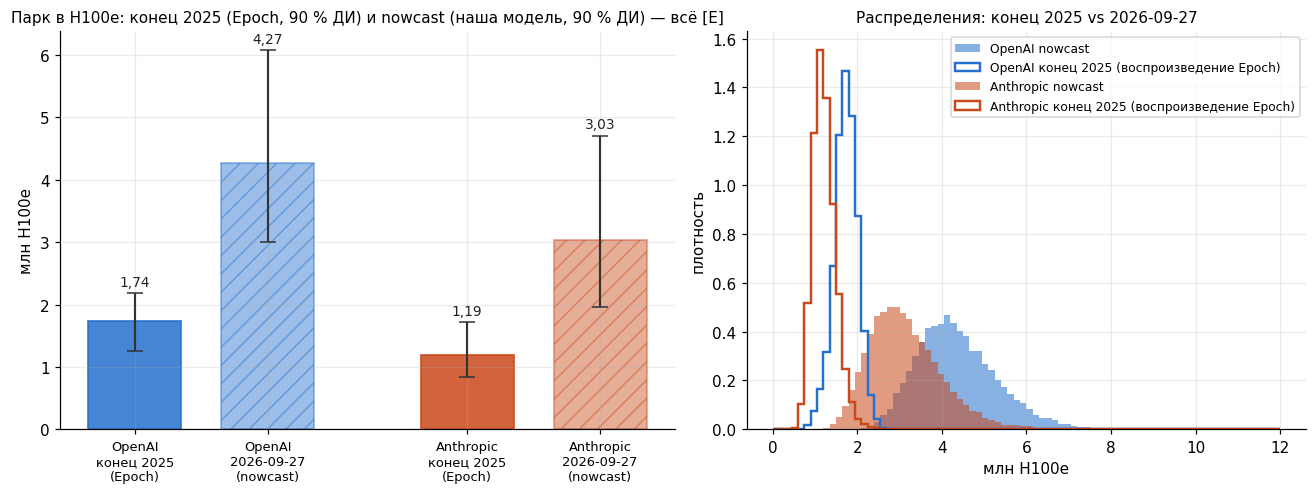

,lab,case,h100e_p50_млн,ГВт IT p50
0,openai,базовый,4.27,4.62
1,openai,"раскрытые ГВт — мощность объекта (PUE 1,3)",3.28,3.55
2,openai,g = 2.5 (нижняя граница),3.43,3.74
3,openai,g = 4.5 (верхняя граница),5.30,5.72
4,openai,η новых вводов = 1209 H100e/МВт,4.27,4.04
5,anthropic,базовый,3.03,3.31
6,anthropic,"раскрытые ГВт — мощность объекта (PUE 1,3)",2.33,2.55
7,anthropic,g = 2.5 (нижняя граница),2.34,2.59
8,anthropic,g = 5.0 (верхняя граница),3.92,4.25
9,anthropic,η новых вводов = 1009 H100e/МВт,3.03,3.20


In [7]:
# ---------------------------------------------------------------- Блок 2, графики: конец 2025 (Epoch) и nowcast с интервалами
COL = {'OpenAI': '#2470cc', 'Anthropic': '#c9491a'}   # категориальные цвета (слоты 1 и 2 палитры)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={'width_ratios': [1.1, 1]})
ax = axes[0]
labels, x = [], 0
for lab in ('OpenAI', 'Anthropic'):
    e = R_NOWCAST['reproduction'][lab]['epoch']; n = R_NOWCAST[lab.lower()]['h100e']
    for tag, (lo, mid, hi), hatch in (('конец 2025\n(Epoch)', (e['p05'], e['p50'], e['p95']), None),
                                      (f'{DATE_TAG}\n(nowcast)', (n['p05'], n['p50'], n['p95']), '//')):
        ax.bar(x, mid / 1e6, width=0.7, color=COL[lab], alpha=0.85 if hatch is None else 0.45, hatch=hatch, edgecolor=COL[lab], linewidth=1.2)
        ax.errorbar(x, mid / 1e6, yerr=[[(mid - lo) / 1e6], [(hi - mid) / 1e6]], fmt='none', ecolor='#333', capsize=5, lw=1.4)
        ax.text(x, hi / 1e6 + 0.12, ru(mid / 1e6, 2), ha='center', fontsize=9, color='#222')
        labels.append(f'{lab}\n{tag}'); x += 1
    x += 0.5
ax.set_xticks([0, 1, 2.5, 3.5]); ax.set_xticklabels(labels, fontsize=8.5)
ax.set_ylabel('млн H100e'); ax.set_title('Парк в H100e: конец 2025 (Epoch, 90 % ДИ) и nowcast (наша модель, 90 % ДИ) — всё [E]', fontsize=10)
ax = axes[1]
for lab in ('OpenAI', 'Anthropic'):
    s = R_NOWCAST['_samples'][f'{lab.lower()}_h100e'] / 1e6
    ax.hist(s, bins=80, range=(0, 12), density=True, color=COL[lab], alpha=0.55, label=f'{lab} nowcast')
    s0 = R_NOWCAST['_samples'][f'{lab.lower()}_rep_h100e'] / 1e6
    ax.hist(s0, bins=80, range=(0, 12), density=True, histtype='step', color=COL[lab], lw=1.6, label=f'{lab} конец 2025 (воспроизведение Epoch)')
ax.set_xlabel('млн H100e'); ax.set_ylabel('плотность'); ax.legend(fontsize=8); ax.set_title(f'Распределения: конец 2025 vs {DATE_TAG}', fontsize=10)
plt.tight_layout(); plt.savefig(OUT / 'results' / f'nowcast_{DATE_TAG}.png', dpi=130); plt.show()

# таблица чувствительности
rows = []
for lab in ('openai', 'anthropic'):
    S = R_NOWCAST['sensitivity'][lab]; base = R_NOWCAST[lab]['h100e']['p50']
    rows.append({'lab': lab, 'case': 'базовый', 'h100e_p50_млн': base / 1e6, 'ГВт IT p50': R_NOWCAST[lab]['gw_it_mw']['p50'] / 1e3})
    rows.append({'lab': lab, 'case': 'раскрытые ГВт — мощность объекта (PUE 1,3)', 'h100e_p50_млн': S['disclosed_is_facility_power_PUE1.3']['h100e']['p50'] / 1e6, 'ГВт IT p50': S['disclosed_is_facility_power_PUE1.3']['gw_it_mw']['p50'] / 1e3})
    rows.append({'lab': lab, 'case': f"g = {S['g_low']['g']} (нижняя граница)", 'h100e_p50_млн': S['g_low']['h100e']['p50'] / 1e6, 'ГВт IT p50': S['g_low']['gw_it_mw']['p50'] / 1e3})
    rows.append({'lab': lab, 'case': f"g = {S['g_high']['g']} (верхняя граница)", 'h100e_p50_млн': S['g_high']['h100e']['p50'] / 1e6, 'ГВт IT p50': S['g_high']['gw_it_mw']['p50'] / 1e3})
    k = [k for k in S if k.startswith('eta_new')][0]
    rows.append({'lab': lab, 'case': f'η новых вводов = {k.split("_")[-1]} H100e/МВт', 'h100e_p50_млн': base / 1e6, 'ГВт IT p50': S[k]['gw_it_mw']['p50'] / 1e3})
display(pd.DataFrame(rows).round(2))

## Блок 3 · Единая таблица пересчёта ГВт ↔ чипы ↔ H100e и число физических ускорителей

Все коэффициенты — на параметрах методологии Epoch AI Chip Users: IT‑мощность на чип = мощность сервера на чип × IT‑overhead 1,14 (5–95 %: 1,00–1,35); H100e — по пиковым плотным 8‑битным FLOP/s. Trainium2 — 871 Вт IT (оценка Epoch: ~500 Вт TDP × 1,74 суммарного overhead, привязано к Rainier: 300 тыс. H100e при 398 МВт). TPUv7 — 960 Вт TDP × 1,742 (overhead, перенесённый с GB200 NVL72) = 1 672 Вт IT, 4,614 / 1,979 = 2,33 H100e. Trainium3 и GB300‑H100e — пометки, данных Epoch нет.

Оценка числа физических ускорителей: OpenAI конец 2025 — (а) по формуле «IT‑мощность ÷ средняя мощность чипа» (Монте‑Карло по доле Blackwell 30–50 % и IT‑мощности 1,44–2,29 ГВт) и (б) побочный результат воспроизведённой модели Epoch из блока 2 (включает ≈10 % A100 по штукам); Anthropic конец 2025 — Trainium2 (доля 35–70 %) + NVIDIA/TPU при 1,4–1,7 кВт IT на чип; Anthropic середина 2026 «по фактам» — ≥1 млн Trainium2 + 220 тыс. GPU Colossus 1 + диапазоны TPU/Azure/Colossus 2. Две контрольные точки (Colossus 1, Абилин) должны воспроизводиться коэффициентами с точностью ±15 %.

In [8]:
%%writefile gpu_fleet_review_out/calc_chips.py
# -*- coding: utf-8 -*-
"""calc_chips.py — коэффициенты ГВт ↔ чипы ↔ H100e, число физических ускорителей, контрольные точки.
Только NumPy/pandas. Запуск: python calc_chips.py  |  из ноутбука: %run -i calc_chips.py
Импортирует распределения и модель OpenAI из calc_nowcast.py (тот же каталог)."""
import os, sys, json, math, datetime as dt
from pathlib import Path
import numpy as np, pandas as pd
sys.path.insert(0, str(Path(__file__).resolve().parent))
import calc_nowcast as CN
from calc_nowcast import lognorm_ci, norm_ci, pct, ru, ru_m, reproduce_openai, sample_openai_power

_g = globals()
NOWCAST_DATE = _g.get('NOWCAST_DATE') or CN.NOWCAST_DATE
SEED = int(_g.get('SEED') or CN.SEED); N_MC = int(_g.get('N_MC') or CN.N_MC); OUT = Path(_g.get('OUT') or CN.OUT)
DATE_TAG = NOWCAST_DATE.isoformat()

# ------------------------------------------------------------------ коэффициенты по чипам  [FACT S04, S10]
IT_OVERHEAD = 1.14                      # [FACT S04] медиана сервер -> IT
TPU_IT_OVERHEAD = 1.742                 # [FACT S04] overhead для TPU (перенесён с GB200 NVL72; у TPU нет публичных серверных спецификаций)
H100_FLOPS = 1.979e15                   # [FACT S10] знаменатель H100e (плотные 8-бит)
CHIP_ROWS = [  # chip, server_w_per_chip, overhead, it_w_per_chip, h100e_per_chip, source/note
    ('A100',      812.5,  IT_OVERHEAD, 812.5 * IT_OVERHEAD,   0.3153, 'Epoch S04 (DGX A100 6,5 кВт / 8)'),
    ('H100/H200', 1275.0, IT_OVERHEAD, 1275.0 * IT_OVERHEAD,  1.0,    'Epoch S04 (DGX H100 10,2 кВт / 8)'),
    ('GB200',     1833.3, IT_OVERHEAD, 1833.3 * IT_OVERHEAD,  2.5265, 'Epoch S04 (NVL72 132 кВт / 72)'),
    ('GB300',     1944.4, IT_OVERHEAD, 1944.4 * IT_OVERHEAD,  2.5265, 'Epoch S04 (NVL72 140 кВт / 72); H100e принят как у GB200 — пометка Epoch'),
    ('Trainium2', float('nan'), float('nan'), CN.T2_IT_W,      CN.T2_H100E, 'Epoch S04: ~500 Вт TDP × 1,74 = 871 Вт IT (привязка к Rainier 300k H100e / 398 МВт); 1299/1979 H100e'),
    ('Trainium3', float('nan'), float('nan'), float('nan'),    float('nan'), 'нет данных Epoch — не заполнено'),
    ('TPUv7 (Ironwood)', float('nan'), TPU_IT_OVERHEAD, 960 * TPU_IT_OVERHEAD, 4.614e15 / H100_FLOPS, 'Epoch S04/S10: TDP 960 Вт × 1,742; 4,614 PFLOP/s 8-бит → 2,33 H100e'),
]
rows = []
for chip, sw, ovh, itw, h, src in CHIP_ROWS:
    rows.append({'chip': chip, 'server_w_per_chip': sw, 'it_overhead': ovh, 'it_w_per_chip': itw, 'h100e_per_chip': h,
                 'chips_per_gw_it': (1e9 / itw) if itw == itw else float('nan'),
                 'h100e_per_gw_it': (1e9 / itw * h) if (itw == itw and h == h) else float('nan'), 'kind': 'chip', 'source': src})
# ------------------------------------------------------------------ строки «парки»  [FACT S04]
HOPPER_SHARE = 1.48 / 2.48; BLACKWELL_SHARE = 1 - HOPPER_SHARE           # Hopper : Blackwell = 1,48 : 1 по штукам  [FACT S04]
W_H, W_B = 1275.0 * IT_OVERHEAD, 1833.3 * IT_OVERHEAD
MIX_W = HOPPER_SHARE * W_H + BLACKWELL_SHARE * W_B                       # ≈ 1 710 Вт IT на чип
FLEETS = [
    ('NVIDIA-микс OpenAI, конец 2025 (Hopper:Blackwell 1,48:1)', MIX_W, 1e9 / MIX_W, 1e9 / MIX_W * (HOPPER_SHARE * 1.0 + BLACKWELL_SHARE * 2.5265), 'наш расчёт по Epoch S04 (Epoch: ~945 H100e/МВт, ~585 тыс. чипов/ГВт)'),
    ('Anthropic смешанный парк, конец 2025', float('nan'), float('nan'), 865.3e3, 'Epoch S04: 865 H100e/МВт (747–1 019)'),
    ('TPU-парк Google (v5e/v5p/v6e/v7), конец 2025', float('nan'), float('nan'), 1009e3, 'Epoch S04: ~1 009 H100e/МВт'),
    ('Trainium2-парк', CN.T2_IT_W, 1e9 / CN.T2_IT_W, CN.T2_PER_MW * 1e3, 'Epoch S04: 754 H100e/МВт'),
    ('1 ГВт объекта при PUE 1,3 → NVIDIA-микс OpenAI', MIX_W, 1e9 / 1.3 / MIX_W, 1e9 / 1.3 / MIX_W * (HOPPER_SHARE + BLACKWELL_SHARE * 2.5265), '[ASSUMPTION] PUE 1,3 — допущение внутри интервала Epoch 1,1–1,7'),
]
for name, itw, cpg, hpg, src in FLEETS:
    rows.append({'chip': name, 'server_w_per_chip': float('nan'), 'it_overhead': float('nan'), 'it_w_per_chip': itw, 'h100e_per_chip': float('nan'),
                 'chips_per_gw_it': cpg, 'h100e_per_gw_it': hpg, 'kind': 'fleet', 'source': src})
COEF = pd.DataFrame(rows)

# ------------------------------------------------------------------ Монте-Карло: физические ускорители
def chips_openai_2025_formula(n, rng):
    """N = P_IT / (w_H·1453 + w_B·2090), доля Blackwell по штукам ~ U(0,30; 0,50)  [ASSUMPTION]; P_IT — как у Epoch."""
    power, _, _ = sample_openai_power(n, rng)
    p_it = power[2025]
    w_b = rng.uniform(0.30, 0.50, n); w_h = 1 - w_b
    chips = p_it * 1e6 / (w_h * W_H + w_b * W_B)
    h100e = chips * (w_h * 1.0 + w_b * 2.5265)
    return {'chips': pct(chips), 'h100e': pct(h100e), 'blackwell_share_h100e': pct(w_b * 2.5265 / (w_h + w_b * 2.5265)), 'p_it_mw': pct(p_it)}

def chips_anthropic_2025(n, rng):
    """Trainium2 (871 Вт) по доле IT-мощности 35–70 % + NVIDIA/TPU при 1,4–1,7 кВт IT на чип  [ASSUMPTION: H100/GB200 в пропорции OpenAI ≈ 1,71 кВт; TPU v7 1,67; v6e 0,66; v5e 0,39]."""
    p = lognorm_ci(*CN.ANTH_POWER_GW_CI, n, rng) * 1e9   # ГВт -> Вт
    sh = norm_ci(*CN.TRAINIUM_SHARE_CI, n, rng, *CN.TRAINIUM_SHARE_CLIP)
    w_nt = rng.uniform(1400, 1700, n)
    t2 = sh * p / CN.T2_IT_W; nt = (1 - sh) * p / w_nt
    return {'chips': pct(t2 + nt), 'trainium2_chips': pct(t2), 'nvidia_tpu_chips': pct(nt)}

def chips_anthropic_mid2026(n, rng):
    """«По фактам»: ≥1 млн Trainium2 [V S25] + >220 тыс. GPU Colossus 1 [V S27] + диапазоны TPU / Azure-CoreWeave / Colossus 2 [ASSUMPTION]."""
    parts = {'Trainium2 (заявлено >1 млн, 20.04.2026)': rng.uniform(1_000_000, 1_200_000, n),   # [V S25] нижняя граница факт, верх — допущение
             'Colossus 1 (H100/H200/GB200)': np.full(n, 220_000.0),                               # [V S27]
             'TPU Google (ввод 2026, до 1 млн по сделке)': rng.uniform(200_000, 600_000, n),        # [ASSUMPTION] доля введённого к середине 2026
             'Azure / CoreWeave GPU': rng.uniform(0, 150_000, n),                                   # [ASSUMPTION]
             'доля Colossus 2 (GB200/GB300)': rng.uniform(0, 110_000, n)}                          # [ASSUMPTION] Epoch: Anthropic среди пользователей
    total = sum(parts.values())
    return {'chips': pct(total), 'parts': {k: pct(v) for k, v in parts.items()}}

# ------------------------------------------------------------------ контрольные точки
def control_points():
    cp = {}
    # Colossus 1: 150k H100 + 50k H200 + 30k GB200 (каталог Epoch)  [FACT S37]; анонс: >220 тыс. GPU, ~300 МВт  [FACT S27]
    n_h, n_gb = 200_000, 30_000
    h100e = n_h * 1.0 + n_gb * 2.5265; it_mw = (n_h * W_H + n_gb * W_B) / 1e6
    cp['Colossus 1'] = {'chips': n_h + n_gb, 'h100e_calc': h100e, 'h100e_epoch': 275_796, 'h100e_dev_%': 100 * (h100e / 275_796 - 1),
                        'it_mw_calc': it_mw, 'it_mw_epoch': 340, 'it_mw_dev_%': 100 * (it_mw / 340 - 1), 'announced_mw': '>300 (Anthropic, S27)',
                        'facility_mw_epoch': 425, 'kw_per_gpu_it_calc': it_mw * 1e3 / (n_h + n_gb),
                        'ok_15pct': abs(h100e / 275_796 - 1) < 0.15 and abs(it_mw / 340 - 1) < 0.15}
    # Абилин: 421 МВт IT (4 здания) -> GB200 -> H100e; Epoch: ~509 тыс. H100e  [FACT S37]; «>450 тыс. GB200 на ~1,2 ГВт» — план полной застройки (СМИ)
    it_mw = 421.0; gb200 = it_mw * 1e6 / W_B; h100e = gb200 * 2.5265
    full_it = 843.0; full_gb200 = full_it * 1e6 / W_B
    cp['Stargate Abilene'] = {'it_mw': it_mw, 'gb200_calc': gb200, 'h100e_calc': h100e, 'h100e_epoch': 509_348, 'h100e_dev_%': 100 * (h100e / 509_348 - 1),
                              'full_build_it_mw_epoch_2026-11': full_it, 'full_build_facility_mw_epoch': 1180, 'full_build_gb200_calc': full_gb200,
                              'full_build_h100e_epoch': 1_018_696, 'media_claim_gb200': 450_000, 'media_claim_it_mw_at_2090W': 450_000 * W_B / 1e6,
                              'media_vs_epoch_dev_%': 100 * (450_000 * W_B / 1e6 / full_it - 1),
                              'ok_15pct': abs(h100e / 509_348 - 1) < 0.15 and abs(450_000 * W_B / 1e6 / full_it - 1) < 0.15}
    return cp

def main(verbose=True):
    rng = np.random.default_rng(SEED)
    R = {'meta': {'date': DATE_TAG, 'seed': SEED, 'n_mc': N_MC},
         'coefficients': COEF.to_dict(orient='records'),
         'openai_end2025': {'formula_05_3': chips_openai_2025_formula(N_MC, rng)},   # ключ formula_05_3 — историческое имя формулы «IT-мощность ÷ средняя мощность чипа»
         'anthropic_end2025': chips_anthropic_2025(N_MC, rng),
         'anthropic_mid2026_by_facts': chips_anthropic_mid2026(N_MC, rng),
         'control_points': control_points()}
    oa = reproduce_openai(N_MC, rng)[2025]
    R['openai_end2025']['epoch_model_reproduced'] = {'chips': pct(oa['chips']), 'note': 'включает A100 (~10 % штук); лаг и overhead по приорам Epoch',
        'blackwell_share_chips': pct((oa['counts']['B200'] + oa['counts']['B300']) / oa['chips']),
        'hopper_share_chips': pct(oa['counts']['H100/H200'] / oa['chips']), 'a100_share_chips': pct(oa['counts']['A100'] / oa['chips'])}
    (OUT / 'data').mkdir(parents=True, exist_ok=True); (OUT / 'results').mkdir(parents=True, exist_ok=True)
    COEF.to_csv(OUT / 'data' / 'coefficients.csv', index=False)
    (OUT / 'results' / f'chips_{DATE_TAG}.json').write_text(json.dumps(R, ensure_ascii=False, indent=2, default=float), encoding='utf-8')
    if verbose:
        f = R['openai_end2025']['formula_05_3']['chips']; e = R['openai_end2025']['epoch_model_reproduced']['chips']
        print(f"OpenAI конец 2025, физ. ускорители: формула P_IT/⟨W⟩ → {f['p05']/1e6:.2f} / {f['p50']/1e6:.2f} / {f['p95']/1e6:.2f} млн ; "
              f"модель Epoch (с A100) → {e['p05']/1e6:.2f} / {e['p50']/1e6:.2f} / {e['p95']/1e6:.2f} млн")
        a = R['anthropic_end2025']['chips']; m = R['anthropic_mid2026_by_facts']['chips']
        print(f"Anthropic конец 2025: {a['p05']/1e6:.2f} / {a['p50']/1e6:.2f} / {a['p95']/1e6:.2f} млн ;  середина 2026 по фактам: {m['p05']/1e6:.2f} / {m['p50']/1e6:.2f} / {m['p95']/1e6:.2f} млн")
        for k, v in R['control_points'].items():
            print(f"Контрольная точка {k}: H100e расчёт/Epoch = {v['h100e_calc']/1e3:.0f}k / {v['h100e_epoch']/1e3:.0f}k ({v['h100e_dev_%']:+.1f} %) ; ±15 %: {'OK' if v['ok_15pct'] else 'FAIL'}")
    return R

if __name__ == '__main__':
    R_CHIPS = main()

Overwriting gpu_fleet_review_out/calc_chips.py


In [9]:
%run -i gpu_fleet_review_out/calc_chips.py
cf = COEF.copy()
for c in ['server_w_per_chip', 'it_w_per_chip']: cf[c] = cf[c].round(0)
cf['h100e_per_chip'] = cf['h100e_per_chip'].round(3); cf['chips_per_gw_it'] = (cf['chips_per_gw_it'] / 1e3).round(0); cf['h100e_per_gw_it'] = (cf['h100e_per_gw_it'] / 1e3).round(0)
cf = cf.rename(columns={'chips_per_gw_it': 'тыс. чипов на 1 ГВт IT', 'h100e_per_gw_it': 'тыс. H100e на 1 ГВт IT'})
display(cf)
display(pd.DataFrame(R_CHIPS['control_points']).T)

OpenAI конец 2025, физ. ускорители: формула P_IT/⟨W⟩ → 0.84 / 1.14 / 1.34 млн ; модель Epoch (с A100) → 0.85 / 1.18 / 1.48 млн
Anthropic конец 2025: 0.90 / 1.25 / 1.76 млн ;  середина 2026 по фактам: 1.62 / 1.85 / 2.08 млн
Контрольная точка Colossus 1: H100e расчёт/Epoch = 276k / 276k (-0.0 %) ; ±15 %: OK
Контрольная точка Stargate Abilene: H100e расчёт/Epoch = 509k / 509k (-0.1 %) ; ±15 %: OK


,chip,server_w_per_chip,it_overhead,it_w_per_chip,h100e_per_chip,тыс. чипов на 1 ГВт IT,тыс. H100e на 1 ГВт IT,kind,source
0,A100,812.0,1.140,926.0,0.315,1080.0,340.0,chip,"Epoch S04 (DGX A100 6,5 кВт / 8)"
1,H100/H200,1275.0,1.140,1453.0,1.000,688.0,688.0,chip,"Epoch S04 (DGX H100 10,2 кВт / 8)"
2,GB200,1833.0,1.140,2090.0,2.526,478.0,1209.0,chip,Epoch S04 (NVL72 132 кВт / 72)
3,GB300,1944.0,1.140,2217.0,2.526,451.0,1140.0,chip,Epoch S04 (NVL72 140 кВт / 72); H100e принят как у GB200 — пометка Epoch
4,Trainium2,NaN,NaN,871.0,0.656,1148.0,754.0,chip,"Epoch S04: ~500 Вт TDP × 1,74 = 871 Вт IT (привязка к Rainier 300k H100e / 398 МВт); 1299/1979 H100e"
5,Trainium3,NaN,NaN,NaN,NaN,NaN,NaN,chip,нет данных Epoch — не заполнено
6,TPUv7 (Ironwood),NaN,1.742,1672.0,2.331,598.0,1394.0,chip,"Epoch S04/S10: TDP 960 Вт × 1,742; 4,614 PFLOP/s 8-бит → 2,33 H100e"
7,"NVIDIA-микс OpenAI, конец 2025 (Hopper:Blackwell 1,48:1)",NaN,NaN,1710.0,NaN,585.0,945.0,fleet,"наш расчёт по Epoch S04 (Epoch: ~945 H100e/МВт, ~585 тыс. чипов/ГВт)"
8,"Anthropic смешанный парк, конец 2025",NaN,NaN,NaN,NaN,NaN,865.0,fleet,Epoch S04: 865 H100e/МВт (747–1 019)
9,"TPU-парк Google (v5e/v5p/v6e/v7), конец 2025",NaN,NaN,NaN,NaN,NaN,1009.0,fleet,Epoch S04: ~1 009 H100e/МВт


,chips,h100e_calc,h100e_epoch,h100e_dev_%,it_mw_calc,it_mw_epoch,it_mw_dev_%,announced_mw,facility_mw_epoch,kw_per_gpu_it_calc,ok_15pct,it_mw,gb200_calc,full_build_it_mw_epoch_2026-11,full_build_facility_mw_epoch,full_build_gb200_calc,full_build_h100e_epoch,media_claim_gb200,media_claim_it_mw_at_2090W,media_vs_epoch_dev_%
Colossus 1,230000,275795.0,275796,-0.000363,353.39886,340,3.940841,">300 (Anthropic, S27)",425,1.536517,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Stargate Abilene,NaN,508935.808402,509348,-0.080925,NaN,NaN,NaN,NaN,NaN,NaN,True,421.0,201439.069227,843.0,1180,403356.616053,1018696,450000,940.4829,11.563808


## Блок 4 · Сплит обучение/инференс на одном базисе и сценарии 2026

**Базис.** Облачные расходы на compute (The Information → Epoch). «Обучение» здесь = весь R&D‑compute (обучение + эксперименты + исследования); финальные прогоны — меньшая его часть (Epoch, 23.03.2026 [S08]). Строки другого базиса (график WSJ, лизк отчётности с амортизацией) вынесены отдельно и не смешиваются с основной таблицей.

**Сценарии 2026 (все `[E]`).** OpenAI: `C_RD` = $32 млрд (The Information, февраль [S15]); `C_inf` — A: $14,1 млрд (Sacra, старый винтаж [S16]); B: $50 − 32 = $18 млрд (бюджет Брокмана [S13]); C: $22 млрд (если рост инференса ×4 в 2025 частично повторится — верхняя граница); D: ×2 к $8,4 млрд = $16,8 млрд. Anthropic: `C_total(кв.) = c · Revenue` (c = 0,71 в I кв., 0,56 во II кв. [S29]), `C_inf = (1 − m) · Revenue` при валовой марже инференса `m` ∈ {50, 60, 65, 72 %}, `C_RD = C_total − C_inf`. Сценарии, где квартальный R&D‑compute < $1 млрд, отбрасываются: в 2025 R&D‑compute составил $4,1 млрд/год ≈ $1,0 млрд/квартал [S06], а компания продолжает наращивать обучение (Amazon — «primary training partner», сделка до 5 ГВт [S25]), поэтому падение ниже квартального уровня 2025 года неправдоподобно.

In [10]:
%%writefile gpu_fleet_review_out/calc_split.py
# -*- coding: utf-8 -*-
"""calc_split.py — сплит обучение (R&D-compute) / инференс, 2024–2026, базис облачных расходов; сценарии 2026.
Запуск: python calc_split.py  |  из ноутбука: %run -i calc_split.py"""
import os, sys, json, datetime as dt
from pathlib import Path
import pandas as pd

_g = globals()
NOWCAST_DATE = _g.get('NOWCAST_DATE') or dt.date.fromisoformat(os.environ.get('NOWCAST_DATE', dt.date.today().isoformat()))
OUT = Path(_g.get('OUT') or os.environ.get('OUT', Path(__file__).resolve().parent)); DATE_TAG = NOWCAST_DATE.isoformat()

def ru(x, nd=1): return f'{x:,.{nd}f}'.replace(',', ' ').replace('.', ',')

# ------------------------------------------------------------------ входы (млрд USD)
SPLIT_INPUTS = [  # company, period, rd_compute, inference, total, basis, status, source, note
    ('OpenAI', '2024', 5.0, 2.0, 6.8, 'cloud compute spend', 'V', 'S07;S04', 'обучение $3 млрд + исследования $1 млрд (амортиз.) ≈ $5 млрд R&D; инференс $1,8–2 млрд'),          # [FACT S07]
    ('OpenAI', '2025', 8.0, 8.4, 16.3, 'cloud compute spend', 'V/V2', 'S04;S16;S09', 'R&D «около половины» $16,3 млрд (Epoch); инференс >$8 млрд (The Information) / $8,4 млрд (Sacra); рост ×4'),  # [FACT S04, S16]
    ('OpenAI', '2026 план', 32.0, None, 50.0, 'cloud compute spend (план)', 'V2', 'S15;S13', 'обучение $32 млрд (The Information, февраль); бюджет $50 млрд (Брокман, май); инференс — сценарии'),  # [FACT S15, S13]
    ('OpenAI', '2027 план', 65.0, None, None, 'план', 'V2', 'S15', 'обучение ~$65 млрд'),
    ('OpenAI', '2025 (другой базис)', None, None, None, 'WSJ chart / лизк отчётности', 'N/V2', 'S31;S34', 'WSJ: обучение $13–25 млрд «в зависимости от учёта» (пересказ Substack) [N]; R&D-расходы $19 млрд с амортизацией [V2] — не сопоставимо'),
    ('OpenAI', '2025 (другой базис: платежи Microsoft, аудировано)', 10.59, 6.047, 17.2, 'GAAP, только Microsoft', 'V', 'S34', 'лизк аудированной отчётности (15.06.2026): $10,59 млрд по строке R&D (Зитрон: «most likely… cost of training»), $6,05 млрд по cost of revenue → ≈ 64/36; отдельной строки inference/training нет; не сопоставимо с облачным базисом'),
    ('Anthropic', '2024', None, None, 2.5, 'cloud compute spend', 'V', 'S04', 'сплит не раскрыт'),                                                                               # [FACT S04]
    ('Anthropic', '2025', 4.1, 2.7, 6.8, 'cloud compute spend', 'V/E', 'S06;S04', 'R&D $4,1 млрд — прогноз компании (декабрь); инференс $2,7 млрд — Epoch из 40 % валовой маржи при выручке $4,5 млрд'),  # [FACT S06]
    ('Anthropic', 'Q1 2026', None, None, round(0.71 * 4.8, 2), 'compute/revenue (WSJ)', 'V2/E', 'S29', '71 ¢ на $1 выручки × $4,8 млрд (включая обучение)'),                    # [FACT S29]
    ('Anthropic', 'Q2 2026 (прогноз)', None, None, round(0.56 * 10.9, 2), 'compute/revenue (WSJ)', 'V2/E', 'S29', '56 ¢ × $10,9 млрд (прогноз компании); Epoch: «около $6 млрд»'),
    ('Anthropic', '2028 (другой базис)', 30.0, None, None, 'WSJ chart', 'V2', 'S31', 'обучение ~$30 млрд (2028 или 2029 по разным пересказам) против ~$121 млрд у OpenAI в 2028 — график WSJ 05.04.2026 за пейволлом, цифры по пересказам'),
]
INPUTS = pd.DataFrame(SPLIT_INPUTS, columns=['company', 'period', 'rd_compute_bn', 'inference_bn', 'total_bn', 'basis', 'status', 'source', 'note'])

OPENAI_RD_2026 = 32.0                                   # [FACT S15]
OPENAI_TOTAL_2026 = 50.0                                # [FACT S13]
OPENAI_INF_SCEN = {'A. Февральский план (Sacra $14,1 млрд, старый винтаж)': 14.1,      # [FACT S16]
                   'B. Бюджет Брокмана: $50 − $32': OPENAI_TOTAL_2026 - OPENAI_RD_2026,  # [FACT S13, S15]
                   'C. Инференс догоняет (верхняя граница)': 22.0,                       # [ASSUMPTION]
                   'D. Инференс ×2 к 2025 ($8,4 млрд × 2)': 2 * 8.4}                       # [ASSUMPTION]
ANTH_QUARTERS = {'Q1 2026': {'revenue': 4.8, 'c': 0.71}, 'Q2 2026': {'revenue': 10.9, 'c': 0.56}}   # [FACT S29]
ANTH_MARGINS = [0.50, 0.60, 0.65, 0.72]                  # [ASSUMPTION] сетка валовой маржи инференса (2025 в среднем ~40 % по всему compute)
ANTH_MIN_RD_PER_Q = 1.0                                  # [ASSUMPTION] порог: R&D-compute 2025 = $4,1 млрд/год ≈ $1,0 млрд/квартал [S06]

def split(rd, inf):
    return rd / (rd + inf), inf / (rd + inf)

def main(verbose=True):
    R = {'meta': {'date': DATE_TAG, 'basis': 'cloud compute spend, USD bn'}, 'history': [], 'openai_2026': [], 'anthropic_2026': []}
    for r in INPUTS.itertuples():
        if r.rd_compute_bn and r.inference_bn and 'другой базис' not in r.period:
            s_rd, s_inf = split(r.rd_compute_bn, r.inference_bn)
            R['history'].append({'company': r.company, 'period': r.period, 'rd_bn': r.rd_compute_bn, 'inf_bn': r.inference_bn, 'total_bn': r.total_bn,
                                 'rd_share': s_rd, 'inf_share': s_inf, 'status': r.status, 'source': r.source, 'formula': 's_RD = C_RD / (C_RD + C_inf)'})
    for name, inf in OPENAI_INF_SCEN.items():
        s_rd, s_inf = split(OPENAI_RD_2026, inf)
        R['openai_2026'].append({'scenario': name, 'rd_bn': OPENAI_RD_2026, 'inf_bn': inf, 'total_bn': OPENAI_RD_2026 + inf, 'rd_share': s_rd, 'inf_share': s_inf,
                                 'status': 'E', 'formula': f'C_RD = 32 [S15]; C_inf = {inf:g}; s_RD = 32 / (32 + {inf:g})'})
    for q, d in ANTH_QUARTERS.items():
        total = d['c'] * d['revenue']
        for m in ANTH_MARGINS:
            inf = (1 - m) * d['revenue']; rd = total - inf
            ok = rd >= ANTH_MIN_RD_PER_Q
            s_rd, s_inf = split(rd, inf) if rd > 0 else (float('nan'), float('nan'))
            R['anthropic_2026'].append({'quarter': q, 'revenue_bn': d['revenue'], 'c_compute_to_revenue': d['c'], 'total_bn': total, 'inference_gross_margin': m,
                                        'inf_bn': inf, 'rd_bn': rd, 'rd_share': s_rd, 'inf_share': s_inf, 'accepted': ok,
                                        'status': 'E', 'formula': f'C_total = {d["c"]} × {d["revenue"]} [S29]; C_inf = (1 − {m}) × {d["revenue"]}; C_RD = C_total − C_inf'})
    # полугодие 2026 Anthropic по принятым сценариям (одна маржа на оба квартала)
    h1 = []
    for m in ANTH_MARGINS:
        rows = [x for x in R['anthropic_2026'] if x['inference_gross_margin'] == m]
        if all(x['accepted'] for x in rows):
            rd = sum(x['rd_bn'] for x in rows); inf = sum(x['inf_bn'] for x in rows)
            h1.append({'inference_gross_margin': m, 'rd_bn': rd, 'inf_bn': inf, 'rd_share': rd / (rd + inf), 'inf_share': inf / (rd + inf)})
    R['anthropic_h1_2026_accepted'] = h1
    acc_q = [x for x in R['anthropic_2026'] if x['accepted']]
    R['summary'] = {
        'openai_2024': next(x for x in R['history'] if x['company'] == 'OpenAI' and x['period'] == '2024'),
        'openai_2025': next(x for x in R['history'] if x['company'] == 'OpenAI' and x['period'] == '2025'),
        'anthropic_2025': next(x for x in R['history'] if x['company'] == 'Anthropic' and x['period'] == '2025'),
        'openai_2026_rd_share_range': (min(x['rd_share'] for x in R['openai_2026']), max(x['rd_share'] for x in R['openai_2026'])),
        'anthropic_2026_rd_share_range_quarters': (min(x['rd_share'] for x in acc_q), max(x['rd_share'] for x in acc_q)),
        'anthropic_h1_2026_rd_share_range': (min(x['rd_share'] for x in h1), max(x['rd_share'] for x in h1)),
        'anthropic_h1_2026_central_m65': next((x for x in h1 if x['inference_gross_margin'] == 0.65), None),
        'rejected_scenarios': [f"{x['quarter']}, маржа {100*x['inference_gross_margin']:.0f} %: R&D ${ru(x['rd_bn'],2)} млрд/кв. < ${ru(ANTH_MIN_RD_PER_Q,1)} млрд" for x in R['anthropic_2026'] if not x['accepted']],
    }
    (OUT / 'data').mkdir(parents=True, exist_ok=True); (OUT / 'results').mkdir(parents=True, exist_ok=True)
    INPUTS.to_csv(OUT / 'data' / 'split_inputs.csv', index=False)
    (OUT / 'results' / f'split_{DATE_TAG}.json').write_text(json.dumps(R, ensure_ascii=False, indent=2, default=float), encoding='utf-8')
    (OUT / 'results' / f'split_{DATE_TAG}.md').write_text(split_markdown(R), encoding='utf-8')
    if verbose:
        S = R['summary']
        print(f"OpenAI 2024: {100*S['openai_2024']['rd_share']:.0f}/{100*S['openai_2024']['inf_share']:.0f}  2025: {100*S['openai_2025']['rd_share']:.0f}/{100*S['openai_2025']['inf_share']:.0f}  "
              f"2026 (сценарии): R&D {100*S['openai_2026_rd_share_range'][0]:.0f}–{100*S['openai_2026_rd_share_range'][1]:.0f} %")
        print(f"Anthropic 2025: {100*S['anthropic_2025']['rd_share']:.0f}/{100*S['anthropic_2025']['inf_share']:.0f}  2026 по кварталам (принятые): R&D "
              f"{100*S['anthropic_2026_rd_share_range_quarters'][0]:.0f}–{100*S['anthropic_2026_rd_share_range_quarters'][1]:.0f} %; I полугодие: {100*S['anthropic_h1_2026_rd_share_range'][0]:.0f}–{100*S['anthropic_h1_2026_rd_share_range'][1]:.0f} %")
        print('Отброшено:', '; '.join(S['rejected_scenarios']) or '—')
    return R

def split_markdown(R):
    S = R['summary']; o24, o25, a25 = S['openai_2024'], S['openai_2025'], S['anthropic_2025']
    lines = [f"# Сплит обучение (R&D-compute) / инференс, базис — облачные расходы на compute ({R['meta']['date']})", '',
             '| Компания | Период | R&D-compute | Инференс | Всего | Сплит R&D / инф., % | Статус | Источник |', '|---|---|---|---|---|---|---|---|']
    for x in R['history']:
        lines.append(f"| {x['company']} | {x['period']} | ${ru(x['rd_bn'])} млрд | ${ru(x['inf_bn'])} млрд | ${ru(x['total_bn'])} млрд | {100*x['rd_share']:.0f} / {100*x['inf_share']:.0f} | [{x['status']}] | [{x['source'].replace(';', '], [')}] |")
    for x in R['openai_2026']:
        lines.append(f"| OpenAI | 2026, сценарий {x['scenario']} | ${ru(x['rd_bn'])} млрд | ${ru(x['inf_bn'])} млрд | ${ru(x['total_bn'])} млрд | {100*x['rd_share']:.0f} / {100*x['inf_share']:.0f} | [E] | [S15], [S13], [S16] |")
    for x in R['anthropic_2026']:
        tag = '' if x['accepted'] else ' — **отброшен** (R&D < $1 млрд/кв.)'
        lines.append(f"| Anthropic | {x['quarter']}, маржа инференса {100*x['inference_gross_margin']:.0f} %{tag} | ${ru(x['rd_bn'],2)} млрд | ${ru(x['inf_bn'],2)} млрд | ${ru(x['total_bn'],2)} млрд | {100*x['rd_share']:.0f} / {100*x['inf_share']:.0f} | [E] | [S29] |")
    for x in R['anthropic_h1_2026_accepted']:
        lines.append(f"| Anthropic | I полугодие 2026, маржа {100*x['inference_gross_margin']:.0f} % | ${ru(x['rd_bn'],2)} млрд | ${ru(x['inf_bn'],2)} млрд | ${ru(x['rd_bn']+x['inf_bn'],2)} млрд | {100*x['rd_share']:.0f} / {100*x['inf_share']:.0f} | [E] | [S29] |")
    lo_o, hi_o = S['openai_2026_rd_share_range']; lo_a, hi_a = S['anthropic_h1_2026_rd_share_range']; lo_q, hi_q = S['anthropic_2026_rd_share_range_quarters']
    lines += ['', '## Выводы', '',
        f"(а) **2025.** OpenAI делила облачные расходы на compute примерно поровну: ~${ru(o25['rd_bn'])} млрд R&D и ${ru(o25['inf_bn'])} млрд инференс из ${ru(o25['total_bn'])} млрд → {100*o25['rd_share']:.0f}/{100*o25['inf_share']:.0f} [S04][V], [S16][V2]; в 2024 — {100*o24['rd_share']:.0f}/{100*o24['inf_share']:.0f} (${ru(o24['rd_bn'])} / ${ru(o24['inf_bn'])} млрд) [S07][V]. Anthropic 2025: ${ru(a25['rd_bn'])} млрд R&D против ~${ru(a25['inf_bn'])} млрд инференса → {100*a25['rd_share']:.0f}/{100*a25['inf_share']:.0f} [S06][V]/[E] (инференс выведен Epoch из 40 % валовой маржи).",
        f"(б) **OpenAI 2026 — по плану {100*lo_o:.0f}–{100*hi_o:.0f} % R&D.** Обучение $32 млрд [S15][V2] при инференсе $14,1–22 млрд по сценариям A–D (бюджет $50 млрд [S13][V2]); винтажи прогнозов различаются (Sacra — до февральского пересмотра), а инференс в 2025 рос ×4, поэтому план может быть занижен в пользу R&D [E].",
        f"(в) **Anthropic 2026 — {100*lo_a:.0f}–{100*hi_a:.0f} % R&D по сценариям** (I полугодие; по кварталам {100*lo_q:.0f}–{100*hi_q:.0f} %); центральный сценарий (маржа инференса 65 %) — {100*S['anthropic_h1_2026_central_m65']['rd_share']:.0f}/{100*S['anthropic_h1_2026_central_m65']['inf_share']:.0f}. Сдвиг к инференсу против 60/40 в 2025 следует из падения compute/выручка с ~1,5 (2025) до 0,71 и 0,56 [S29][V2]. Отброшены сценарии с R&D < $1 млрд/квартал: " + '; '.join(S['rejected_scenarios']) + ' [E].',
        f"(г₀) **Проверка по аудированной отчётности.** В лизке отчётности OpenAI за 2025 [S34][V] нет строки инференс/обучение; ближайший аналог — платежи Microsoft: $10,59 млрд по R&D и $6,05 млрд по cost of revenue (≈ 64/36), но это GAAP-базис только по одному поставщику, поэтому оценка 50/50 на облачном базисе не заменяется.",
        "(г) **Оговорки.** «Обучение» = весь R&D-compute, финальные прогоны — меньшая часть [S08][V]; винтажи прогнозов OpenAI на 2026 не совпадают ($14,1 млрд — до февраля; $32 млрд — февраль; $50 млрд — май); валовая маржа инференса Anthropic в 2026 не раскрыта — сплит 2026 только сценарный; строки другого базиса (WSJ $13–25 млрд, R&D-расходы $19 млрд с амортизацией) не смешиваются с облачным базисом.", '']
    return '\n'.join(lines)

if __name__ == '__main__':
    R_SPLIT = main()

Overwriting gpu_fleet_review_out/calc_split.py


OpenAI 2024: 71/29  2025: 49/51  2026 (сценарии): R&D 59–69 %
Anthropic 2025: 60/40  2026 по кварталам (принятые): R&D 29–61 %; I полугодие: 34–54 %
Отброшено: Q2 2026, маржа 50 %: R&D $0,65 млрд/кв. < $1,0 млрд


# Сплит обучение (R&D-compute) / инференс, базис — облачные расходы на compute (2026-09-27)

| Компания | Период | R&D-compute | Инференс | Всего | Сплит R&D / инф., % | Статус | Источник |
|---|---|---|---|---|---|---|---|
| OpenAI | 2024 | $5,0 млрд | $2,0 млрд | $6,8 млрд | 71 / 29 | [V] | [S07], [S04] |
| OpenAI | 2025 | $8,0 млрд | $8,4 млрд | $16,3 млрд | 49 / 51 | [V/V2] | [S04], [S16], [S09] |
| OpenAI | 2026 план | $32,0 млрд | $nan млрд | $50,0 млрд | nan / nan | [V2] | [S15], [S13] |
| OpenAI | 2027 план | $65,0 млрд | $nan млрд | $nan млрд | nan / nan | [V2] | [S15] |
| Anthropic | 2024 | $nan млрд | $nan млрд | $2,5 млрд | nan / nan | [V] | [S04] |
| Anthropic | 2025 | $4,1 млрд | $2,7 млрд | $6,8 млрд | 60 / 40 | [V/E] | [S06], [S04] |
| Anthropic | Q1 2026 | $nan млрд | $nan млрд | $3,4 млрд | nan / nan | [V2/E] | [S29] |
| Anthropic | Q2 2026 (прогноз) | $nan млрд | $nan млрд | $6,1 млрд | nan / nan | [V2/E] | [S29] |
| OpenAI | 2026, сценарий A. Февральский план (Sacra $14,1 млрд, старый винтаж) | $32,0 млрд | $14,1 млрд | $46,1 млрд | 69 / 31 | [E] | [S15], [S13], [S16] |
| OpenAI | 2026, сценарий B. Бюджет Брокмана: $50 − $32 | $32,0 млрд | $18,0 млрд | $50,0 млрд | 64 / 36 | [E] | [S15], [S13], [S16] |
| OpenAI | 2026, сценарий C. Инференс догоняет (верхняя граница) | $32,0 млрд | $22,0 млрд | $54,0 млрд | 59 / 41 | [E] | [S15], [S13], [S16] |
| OpenAI | 2026, сценарий D. Инференс ×2 к 2025 ($8,4 млрд × 2) | $32,0 млрд | $16,8 млрд | $48,8 млрд | 66 / 34 | [E] | [S15], [S13], [S16] |
| Anthropic | Q1 2026, маржа инференса 50 % | $1,01 млрд | $2,40 млрд | $3,41 млрд | 30 / 70 | [E] | [S29] |
| Anthropic | Q1 2026, маржа инференса 60 % | $1,49 млрд | $1,92 млрд | $3,41 млрд | 44 / 56 | [E] | [S29] |
| Anthropic | Q1 2026, маржа инференса 65 % | $1,73 млрд | $1,68 млрд | $3,41 млрд | 51 / 49 | [E] | [S29] |
| Anthropic | Q1 2026, маржа инференса 72 % | $2,06 млрд | $1,34 млрд | $3,41 млрд | 61 / 39 | [E] | [S29] |
| Anthropic | Q2 2026, маржа инференса 50 % — **отброшен** (R&D < $1 млрд/кв.) | $0,65 млрд | $5,45 млрд | $6,10 млрд | 11 / 89 | [E] | [S29] |
| Anthropic | Q2 2026, маржа инференса 60 % | $1,74 млрд | $4,36 млрд | $6,10 млрд | 29 / 71 | [E] | [S29] |
| Anthropic | Q2 2026, маржа инференса 65 % | $2,29 млрд | $3,81 млрд | $6,10 млрд | 38 / 62 | [E] | [S29] |
| Anthropic | Q2 2026, маржа инференса 72 % | $3,05 млрд | $3,05 млрд | $6,10 млрд | 50 / 50 | [E] | [S29] |
| Anthropic | I полугодие 2026, маржа 60 % | $3,23 млрд | $6,28 млрд | $9,51 млрд | 34 / 66 | [E] | [S29] |
| Anthropic | I полугодие 2026, маржа 65 % | $4,02 млрд | $5,50 млрд | $9,51 млрд | 42 / 58 | [E] | [S29] |
| Anthropic | I полугодие 2026, маржа 72 % | $5,12 млрд | $4,40 млрд | $9,51 млрд | 54 / 46 | [E] | [S29] |

## Выводы

(а) **2025.** OpenAI делила облачные расходы на compute примерно поровну: ~$8,0 млрд R&D и $8,4 млрд инференс из $16,3 млрд → 49/51 [S04][V], [S16][V2]; в 2024 — 71/29 ($5,0 / $2,0 млрд) [S07][V]. Anthropic 2025: $4,1 млрд R&D против ~$2,7 млрд инференса → 60/40 [S06][V]/[E] (инференс выведен Epoch из 40 % валовой маржи).
(б) **OpenAI 2026 — по плану 59–69 % R&D.** Обучение $32 млрд [S15][V2] при инференсе $14,1–22 млрд по сценариям A–D (бюджет $50 млрд [S13][V2]); винтажи прогнозов различаются (Sacra — до февральского пересмотра), а инференс в 2025 рос ×4, поэтому план может быть занижен в пользу R&D [E].
(в) **Anthropic 2026 — 34–54 % R&D по сценариям** (I полугодие; по кварталам 29–61 %); центральный сценарий (маржа инференса 65 %) — 42/58. Сдвиг к инференсу против 60/40 в 2025 следует из падения compute/выручка с ~1,5 (2025) до 0,71 и 0,56 [S29][V2]. Отброшены сценарии с R&D < $1 млрд/квартал: Q2 2026, маржа 50 %: R&D $0,65 млрд/кв. < $1,0 млрд [E].
(г₀) **Проверка по аудированной отчётности.** В лизке отчётности OpenAI за 2025 [S34][V] нет строки инференс/обучение; ближайший аналог — платежи Microsoft: $10,59 млрд по R&D и $6,05 млрд по cost of revenue (≈ 64/36), но это GAAP-базис только по одному поставщику, поэтому оценка 50/50 на облачном базисе не заменяется.
(г) **Оговорки.** «Обучение» = весь R&D-compute, финальные прогоны — меньшая часть [S08][V]; винтажи прогнозов OpenAI на 2026 не совпадают ($14,1 млрд — до февраля; $32 млрд — февраль; $50 млрд — май); валовая маржа инференса Anthropic в 2026 не раскрыта — сплит 2026 только сценарный; строки другого базиса (WSJ $13–25 млрд, R&D-расходы $19 млрд с амортизацией) не смешиваются с облачным базисом.


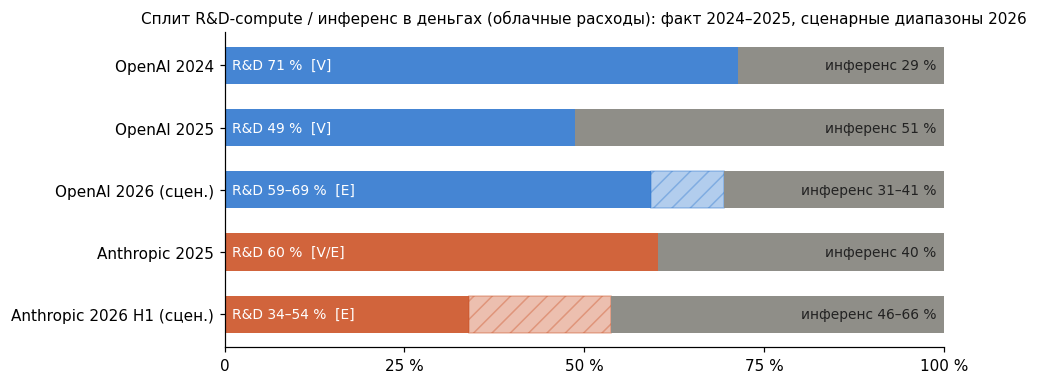

In [11]:
%run -i gpu_fleet_review_out/calc_split.py
md(open(OUT / 'results' / f'split_{DATE_TAG}.md', encoding='utf-8').read())

# график: stacked-бары сплита 2024–2026 (для 2026 — диапазон)
S = R_SPLIT['summary']
fig, ax = plt.subplots(figsize=(9, 3.6))
items = [('OpenAI 2024', S['openai_2024']['rd_share'], S['openai_2024']['rd_share'], 'V'),
         ('OpenAI 2025', S['openai_2025']['rd_share'], S['openai_2025']['rd_share'], 'V'),
         ('OpenAI 2026 (сцен.)', *S['openai_2026_rd_share_range'], 'E'),
         ('Anthropic 2025', S['anthropic_2025']['rd_share'], S['anthropic_2025']['rd_share'], 'V/E'),
         ('Anthropic 2026 H1 (сцен.)', *S['anthropic_h1_2026_rd_share_range'], 'E')]
for i, (name, lo, hi, st) in enumerate(items):
    col = COL['OpenAI'] if name.startswith('OpenAI') else COL['Anthropic']
    ax.barh(i, lo, color=col, alpha=0.85, height=0.6)
    if hi > lo: ax.barh(i, hi - lo, left=lo, color=col, alpha=0.35, hatch='//', edgecolor=col, height=0.6)
    ax.barh(i, 1 - hi, left=hi, color='#8f8e88', height=0.6)
    ax.text(0.01, i, f'R&D {100*lo:.0f}' + (f'–{100*hi:.0f}' if hi > lo else '') + f' %  [{st}]', va='center', fontsize=9, color='white' if lo > 0.15 else '#222')
    ax.text(0.99, i, f'инференс {100*(1-hi):.0f}' + (f'–{100*(1-lo):.0f}' if hi > lo else '') + ' %', va='center', ha='right', fontsize=9, color='#222')
ax.set_yticks(range(len(items))); ax.set_yticklabels([x[0] for x in items]); ax.invert_yaxis(); ax.set_xlim(0, 1); ax.set_xticks([0, .25, .5, .75, 1]); ax.set_xticklabels(['0', '25 %', '50 %', '75 %', '100 %'])
ax.set_title('Сплит R&D-compute / инференс в деньгах (облачные расходы): факт 2024–2025, сценарные диапазоны 2026', fontsize=10); ax.grid(False)
plt.tight_layout(); plt.savefig(OUT / 'results' / f'split_{DATE_TAG}.png', dpi=130); plt.show()

## Блок 5 · Данные и спецификация для слайда

Композиция: заголовок‑ответ; слева — столбики H100e с 90 % ДИ (конец 2025 по Epoch и nowcast на дату слайда, обе компании, подпись ГВт под каждым); справа — stacked‑бары сплита R&D/инференс 2024–2026 (2026 — диапазон); низ — строка статусов «факт / оценка / экстраполяция», семь источников и дата доступа; две оговорки одной строкой каждая. Цвета: OpenAI — синий, Anthropic — оранжевый; статус кодируется **заливкой, а не цветом**: сплошная — факт/оценка Epoch, штриховка — наша экстраполяция/сценарий. HTML‑макет — один экран 1280×720, без внешних зависимостей, системные шрифты с fallback.

In [12]:
# ---------------------------------------------------------------- Блок 5: slide_data.json, slide_spec.md, slide.html
o, a = R_NOWCAST['openai'], R_NOWCAST['anthropic']; S = R_SPLIT['summary']
eo, ea = R_NOWCAST['reproduction']['OpenAI']['epoch'], R_NOWCAST['reproduction']['Anthropic']['epoch']
FOOTER_SOURCES = ['S01', 'S02', 'S11', 'S13', 'S15', 'S06', 'S29']
slide_data = {
    'as_of': DATE_TAG, 'accessed': ACCESSED,
    'title': f"Штуки не публикуются; в H100e OpenAI ≈ {ru(eo['p50']/1e6,1)} млн, Anthropic ≈ {ru(ea['p50']/1e6,1)} млн (конец 2025); "
             f"nowcast на {NOWCAST_DATE.strftime('%d.%m.%Y')} — ×{ru(o['multiplier_vs_end2025']['p50'],1)} и ×{ru(a['multiplier_vs_end2025']['p50'],1)}; сплит обучение/инференс 2025: 50/50 и 60/40; 2026 — обучение {100*S['openai_2026_rd_share_range'][0]:.0f}–{100*S['openai_2026_rd_share_range'][1]:.0f} % у OpenAI по плану, {100*S['anthropic_h1_2026_rd_share_range'][0]:.0f}–{100*S['anthropic_h1_2026_rd_share_range'][1]:.0f} % у Anthropic по сценариям",
    'bars_h100e': [
        {'company': 'OpenAI', 'period': 'конец 2025', 'p05': eo['p05'], 'p50': eo['p50'], 'p95': eo['p95'], 'status': 'E (Epoch)', 'source': 'S02'},
        {'company': 'OpenAI', 'period': f'nowcast {DATE_TAG}', 'p05': o['h100e']['p05'], 'p50': o['h100e']['p50'], 'p95': o['h100e']['p95'], 'status': 'E (наша модель)', 'source': 'calc_nowcast.py'},
        {'company': 'Anthropic', 'period': 'конец 2025', 'p05': ea['p05'], 'p50': ea['p50'], 'p95': ea['p95'], 'status': 'E (Epoch)', 'source': 'S02'},
        {'company': 'Anthropic', 'period': f'nowcast {DATE_TAG}', 'p05': a['h100e']['p05'], 'p50': a['h100e']['p50'], 'p95': a['h100e']['p95'], 'status': 'E (наша модель)', 'source': 'calc_nowcast.py'},
    ],
    'gw_labels': [
        {'company': 'OpenAI', 'period': 'конец 2025', 'label': '1,9 ГВт [V2]', 'source': 'S01'},
        {'company': 'OpenAI', 'period': f'nowcast {DATE_TAG}', 'label': f"≈{ru(o['gw_it_mw']['p50']/1e3,1)} ГВт IT ({ru(o['gw_it_mw']['p05']/1e3,1)}–{ru(o['gw_it_mw']['p95']/1e3,1)}) [E]", 'source': 'calc_nowcast.py'},
        {'company': 'Anthropic', 'period': 'конец 2025', 'label': '≈1,4 ГВт [V2, оценка OpenAI]', 'source': 'S11'},
        {'company': 'Anthropic', 'period': f'nowcast {DATE_TAG}', 'label': f"≈{ru(a['gw_it_mw']['p50']/1e3,1)} ГВт IT ({ru(a['gw_it_mw']['p05']/1e3,1)}–{ru(a['gw_it_mw']['p95']/1e3,1)}) [E]", 'source': 'calc_nowcast.py'},
    ],
    'split_bars': [
        {'company': 'OpenAI', 'year': '2024', 'rd_min': S['openai_2024']['rd_share'], 'rd_max': S['openai_2024']['rd_share'], 'inf_min': S['openai_2024']['inf_share'], 'inf_max': S['openai_2024']['inf_share'], 'status': 'V', 'source': 'S07'},
        {'company': 'OpenAI', 'year': '2025', 'rd_min': S['openai_2025']['rd_share'], 'rd_max': S['openai_2025']['rd_share'], 'inf_min': S['openai_2025']['inf_share'], 'inf_max': S['openai_2025']['inf_share'], 'status': 'V', 'source': 'S04;S16'},
        {'company': 'OpenAI', 'year': '2026 (план, сценарии)', 'rd_min': S['openai_2026_rd_share_range'][0], 'rd_max': S['openai_2026_rd_share_range'][1], 'inf_min': 1 - S['openai_2026_rd_share_range'][1], 'inf_max': 1 - S['openai_2026_rd_share_range'][0], 'status': 'E', 'source': 'S15;S13;S16'},
        {'company': 'Anthropic', 'year': '2024', 'rd_min': None, 'rd_max': None, 'inf_min': None, 'inf_max': None, 'status': '—', 'source': 'S04'},
        {'company': 'Anthropic', 'year': '2025', 'rd_min': S['anthropic_2025']['rd_share'], 'rd_max': S['anthropic_2025']['rd_share'], 'inf_min': S['anthropic_2025']['inf_share'], 'inf_max': S['anthropic_2025']['inf_share'], 'status': 'V/E', 'source': 'S06'},
        {'company': 'Anthropic', 'year': '2026 H1 (сценарии)', 'rd_min': S['anthropic_h1_2026_rd_share_range'][0], 'rd_max': S['anthropic_h1_2026_rd_share_range'][1], 'inf_min': 1 - S['anthropic_h1_2026_rd_share_range'][1], 'inf_max': 1 - S['anthropic_h1_2026_rd_share_range'][0], 'status': 'E', 'source': 'S29'},
    ],
    'footer_sources': FOOTER_SOURCES,
    'caveats': ['«Обучение» = весь R&D-compute (эксперименты, исследования); финальные прогоны — меньшая часть [S08].',
                'Сторонний инференс учтён в оценке Anthropic (Bedrock/Vertex, ≈10 %) и не учтён у OpenAI (Azure, до ~25 %) — сравнение смещено против OpenAI на 10–25 % [S04].'],
    'status_legend': {'факт': '[V]/[V2] — раскрыто компанией или подтверждено прессой', 'оценка': '[E] Epoch — медиана и 90 % ДИ', 'экстраполяция': '[E] наша модель — штриховка'},
}
save_json(slide_data, OUT / 'results' / 'slide_data.json')

# ---- slide_spec.md
spec = f"""# Спецификация слайда — as of {DATE_TAG}, источники проверены {ACCESSED}

**Заголовок‑ответ (одна строка, ≤ 2 строк на слайде).** {slide_data['title']}

**Слева (≈55 % ширины): «Парк в H100e».** Четыре столбика: OpenAI конец 2025 (Epoch), OpenAI nowcast {DATE_TAG}, Anthropic конец 2025 (Epoch), Anthropic nowcast. Высота — медиана; усы — 90 % ДИ (p05–p95). Подпись над столбиком — медиана в млн H100e; подпись под столбиком — ГВт со статусом: {' · '.join(g['label'] for g in slide_data['gw_labels'])}. Ось Y — «млн H100e» (0 … округление вверх от p95 nowcast OpenAI). Ось X — компания и период.

**Справа (≈45 %): «Сплит R&D / инференс, в деньгах».** Горизонтальные stacked‑бары по годам 2024, 2025, 2026 для каждой компании. Левый сегмент — R&D‑compute, правый — инференс. Для 2026 — диапазон (штриховка между мин. и макс. долей R&D); Anthropic 2024 — «не раскрыто». Значения: OpenAI {100*S['openai_2024']['rd_share']:.0f}/{100*S['openai_2024']['inf_share']:.0f} (2024), {100*S['openai_2025']['rd_share']:.0f}/{100*S['openai_2025']['inf_share']:.0f} (2025), R&D {100*S['openai_2026_rd_share_range'][0]:.0f}–{100*S['openai_2026_rd_share_range'][1]:.0f} % (2026 план); Anthropic {100*S['anthropic_2025']['rd_share']:.0f}/{100*S['anthropic_2025']['inf_share']:.0f} (2025), R&D {100*S['anthropic_h1_2026_rd_share_range'][0]:.0f}–{100*S['anthropic_h1_2026_rd_share_range'][1]:.0f} % (H1 2026 сценарии). Ось X — доля, 0–100 %.

**Цветовое кодирование.** Компания — цветом: OpenAI `#2470cc` (синий), Anthropic `#c9491a` (оранжевый). Статус — заливкой, не цветом: сплошная заливка — факт [V]/[V2] или оценка Epoch [E]; диагональная штриховка — наша экстраполяция/сценарий [E]. Текст — только нейтральные цвета (`#0b0b0b`, `#52514e`), никогда цветом серии. Инференс в stacked‑барах — нейтральный серый `#8f8e88`.

**Низ: строка статусов и источников.** «факт [V]/[V2] · оценка Epoch [E] · экстраполяция/сценарий [E, штриховка]». Источники: {', '.join(FOOTER_SOURCES)} (S01 — блог OpenAI 1,9 ГВт; S02 — Epoch AI Chip Users; S11 — Bloomberg/меморандум OpenAI 1,4 ГВт; S13 — Bloomberg, $50 млрд; S15 — The Information/The Decoder, $32 млрд; S06 — Epoch, расходы Anthropic; S29 — WSJ, кварталы Anthropic). Дата доступа: {ACCESSED}. Дата слайда: {DATE_TAG}.

**Две оговорки (по одной строке).**
1. {slide_data['caveats'][0]}
2. {slide_data['caveats'][1]}
"""
write_text(spec, OUT / 'results' / 'slide_spec.md')

# ---- slide.html: один экран 1280×720, inline SVG, без внешних зависимостей
def esc(s): return str(s).replace('&', '&amp;').replace('<', '&lt;').replace('>', '&gt;')
W, H = 1280, 720
COLH = {'OpenAI': '#2470cc', 'Anthropic': '#c9491a'}
# левая панель: столбики
Lx, Ly, Lw, Lh = 40, 120, 640, 420
ymax = math.ceil(max(b['p95'] for b in slide_data['bars_h100e']) / 1e6) + 0.5
def ypx(v): return Ly + Lh - (v / 1e6) / ymax * Lh
svg = [f'<svg viewBox="0 0 {W} {H}" width="{W}" height="{H}" xmlns="http://www.w3.org/2000/svg" role="img" aria-label="GPU-парк OpenAI и Anthropic">',
       '<defs><pattern id="hatchO" patternUnits="userSpaceOnUse" width="8" height="8" patternTransform="rotate(45)"><rect width="8" height="8" fill="#2470cc" fill-opacity="0.18"/><line x1="0" y1="0" x2="0" y2="8" stroke="#2470cc" stroke-width="3"/></pattern>',
       '<pattern id="hatchA" patternUnits="userSpaceOnUse" width="8" height="8" patternTransform="rotate(45)"><rect width="8" height="8" fill="#c9491a" fill-opacity="0.18"/><line x1="0" y1="0" x2="0" y2="8" stroke="#c9491a" stroke-width="3"/></pattern></defs>',
       f'<rect width="{W}" height="{H}" fill="var(--surface)"/>',
       *[f'<text x="40" y="{44 + 26*k}" class="title">{esc(line)}</text>' for k, line in enumerate(textwrap.wrap(slide_data['title'], 118)[:2])],
       f'<text x="{Lx}" y="{Ly-14}" class="h2">Парк в H100e: медиана и 90 % ДИ</text>',
       f'<text x="{Lx+Lw+40}" y="{Ly-14}" class="h2">Сплит R&amp;D-compute / инференс, в деньгах</text>']
for k in range(int(ymax) + 1):
    y = ypx(k * 1e6); svg.append(f'<line x1="{Lx}" y1="{y:.1f}" x2="{Lx+Lw}" y2="{y:.1f}" class="grid"/><text x="{Lx-6}" y="{y+4:.1f}" class="tick" text-anchor="end">{k}</text>')
svg.append(f'<text x="{Lx-28}" y="{Ly+Lh/2}" class="tick" transform="rotate(-90 {Lx-28} {Ly+Lh/2})" text-anchor="middle">млн H100e</text>')
bw, gap = 110, 40; x0 = Lx + 50
for i, b in enumerate(slide_data['bars_h100e']):
    x = x0 + i * (bw + gap) + (30 if i >= 2 else 0); col = COLH[b['company']]; hatched = 'nowcast' in b['period']
    fill = f'url(#hatch{"O" if b["company"]=="OpenAI" else "A"})' if hatched else col
    svg.append(f'<rect x="{x}" y="{ypx(b["p50"]):.1f}" width="{bw}" height="{Ly+Lh-ypx(b["p50"]):.1f}" fill="{fill}" stroke="{col}" stroke-width="1.5" rx="3"/>')
    svg.append(f'<line x1="{x+bw/2}" y1="{ypx(b["p05"]):.1f}" x2="{x+bw/2}" y2="{ypx(b["p95"]):.1f}" class="ci"/>'
               f'<line x1="{x+bw/2-12}" y1="{ypx(b["p05"]):.1f}" x2="{x+bw/2+12}" y2="{ypx(b["p05"]):.1f}" class="ci"/><line x1="{x+bw/2-12}" y1="{ypx(b["p95"]):.1f}" x2="{x+bw/2+12}" y2="{ypx(b["p95"]):.1f}" class="ci"/>')
    svg.append(f'<text x="{x+bw/2}" y="{ypx(b["p95"])-8:.1f}" class="val" text-anchor="middle">{esc(ru(b["p50"]/1e6,2))} млн</text>')
    svg.append(f'<text x="{x+bw/2}" y="{Ly+Lh+16}" class="lab" text-anchor="middle">{esc(b["company"])}</text>')
    svg.append(f'<text x="{x+bw/2}" y="{Ly+Lh+30}" class="lab" text-anchor="middle">{esc(b["period"])}</text>')
    gwl = slide_data['gw_labels'][i]['label']
    svg.append(f'<text x="{x+bw/2}" y="{Ly+Lh+46}" class="lab2" text-anchor="middle">{esc(gwl)}</text>')
    svg.append(f'<text x="{x+bw/2}" y="{Ly+Lh+60}" class="lab2" text-anchor="middle">{esc(b["status"])}</text>')
# правая панель: stacked-бары
Rx, Ry, Rw = Lx + Lw + 40, Ly + 10, 560
rowh, rgap = 34, 14
for i, sb in enumerate(slide_data['split_bars']):
    y = Ry + i * (rowh + rgap) + (16 if i >= 3 else 0); col = COLH[sb['company']]
    svg.append(f'<text x="{Rx}" y="{y+rowh/2+4}" class="lab">{esc(sb["company"])} {esc(sb["year"])}</text>')
    bx = Rx + 170; bwid = 215
    if sb['rd_min'] is None:
        svg.append(f'<rect x="{bx}" y="{y}" width="{bwid}" height="{rowh}" fill="#ecebe7" rx="3"/><text x="{bx+bwid/2}" y="{y+rowh/2+4}" class="lab2" text-anchor="middle">сплит не раскрыт [{esc(sb["source"])}]</text>'); continue
    lo, hi = sb['rd_min'], sb['rd_max']
    svg.append(f'<rect x="{bx}" y="{y}" width="{lo*bwid:.1f}" height="{rowh}" fill="{col}" rx="3"/>')
    if hi > lo: svg.append(f'<rect x="{bx+lo*bwid:.1f}" y="{y}" width="{(hi-lo)*bwid:.1f}" height="{rowh}" fill="url(#hatch{"O" if sb["company"]=="OpenAI" else "A"})" stroke="{col}" stroke-width="1"/>')
    svg.append(f'<rect x="{bx+hi*bwid+2:.1f}" y="{y}" width="{(1-hi)*bwid-2:.1f}" height="{rowh}" fill="#8f8e88" rx="3"/>')
    rd_txt = f'R&amp;D {100*lo:.0f}' + (f'–{100*hi:.0f}' if hi > lo else '') + ' %'; inf_txt = f'инференс {100*(1-hi):.0f}' + (f'–{100*(1-lo):.0f}' if hi > lo else '') + ' %'
    svg.append(f'<text x="{bx+6}" y="{y+rowh/2+4}" class="valw">{rd_txt}</text><text x="{bx+bwid+8}" y="{y+rowh/2+4}" class="val">{inf_txt} [{esc(sb["status"])}]</text>')
# низ: легенда статусов, оговорки, источники
fy = Ly + Lh + 84
svg.append(f'<rect x="{Lx}" y="{fy}" width="14" height="14" fill="#52514e"/><text x="{Lx+20}" y="{fy+12}" class="lab2">факт [V]/[V2] — сплошная заливка</text>')
svg.append(f'<rect x="{Lx+260}" y="{fy}" width="14" height="14" fill="#2470cc"/><text x="{Lx+280}" y="{fy+12}" class="lab2">оценка Epoch [E] — сплошная, 90 % ДИ усами</text>')
svg.append(f'<rect x="{Lx+600}" y="{fy}" width="14" height="14" fill="url(#hatchO)" stroke="#2470cc"/><text x="{Lx+620}" y="{fy+12}" class="lab2">экстраполяция / сценарий [E] — штриховка</text>')
svg.append(f'<text x="{Lx}" y="{fy+34}" class="cav">1. {esc(slide_data["caveats"][0])}</text>')
svg.append(f'<text x="{Lx}" y="{fy+52}" class="cav">2. {esc(slide_data["caveats"][1])}</text>')
svg.append(f'<text x="{Lx}" y="{H-14}" class="foot">Источники: {", ".join(FOOTER_SOURCES)} (реестр data/sources_2026-09-27.csv) · дата доступа {ACCESSED} · дата слайда {DATE_TAG} · nowcast: N(t)=N₂₀₂₅·g^Δt, Монте-Карло {ru(N_MC,0)} прогонов, seed {SEED}</text>')
svg.append('</svg>')
html = f"""<!DOCTYPE html>
<html lang="ru"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width, initial-scale=1"><title>GPU-парк OpenAI и Anthropic</title>
<style>
:root {{ --surface:#fcfcfb; --ink:#0b0b0b; --ink2:#52514e; --grid:#e6e5e0; }}
@media (prefers-color-scheme: dark) {{ :root:not([data-theme="light"]) {{ --surface:#1a1a19; --ink:#ffffff; --ink2:#c3c2b7; --grid:#33332f; }} }}
:root[data-theme="dark"] {{ --surface:#1a1a19; --ink:#ffffff; --ink2:#c3c2b7; --grid:#33332f; }}
html,body {{ margin:0; background:var(--surface); color:var(--ink); font-family: -apple-system, "Segoe UI", Roboto, "Helvetica Neue", Arial, "Noto Sans", sans-serif; }}
.slide {{ width:100vw; height:100vh; display:flex; align-items:center; justify-content:center; padding:0 16px; box-sizing:border-box; }}
svg {{ max-width:100%; max-height:100vh; height:auto; }}
.title {{ font-size:18px; font-weight:600; fill:var(--ink); }}
.h2 {{ font-size:14px; font-weight:600; fill:var(--ink2); }}
.tick, .lab2, .foot {{ font-size:11px; fill:var(--ink2); }}
.lab {{ font-size:12px; fill:var(--ink); }}
.val {{ font-size:12px; font-weight:600; fill:var(--ink); }}
.valw {{ font-size:11px; font-weight:600; fill:#ffffff; }}
.cav {{ font-size:12px; fill:var(--ink); }}
.grid {{ stroke:var(--grid); stroke-width:1; }}
.ci {{ stroke:var(--ink); stroke-width:1.6; }}
</style></head>
<body><div class="slide">{''.join(svg)}</div></body></html>"""
write_text(html, OUT / 'results' / 'slide.html')
print('slide_data.json, slide_spec.md, slide.html записаны;', f"{len(html)/1024:.0f} КБ HTML, внешних зависимостей нет")
display(HTML(f'<div style="border:1px solid #ddd;max-width:1000px">{"".join(svg).replace("var(--surface)", "#fcfcfb").replace("var(--ink2)", "#52514e").replace("var(--ink)", "#0b0b0b").replace("var(--grid)", "#e6e5e0")}</div>'))

slide_data.json, slide_spec.md, slide.html записаны; 9 КБ HTML, внешних зависимостей нет


### Отчёт для CTO (`results/report_cto.html`)

Отдельная HTML‑страница для показа CTO: те же числа из JSON‑результатов блоков 2–4 и реестра блока 1, но **без кодов источников и статусов** — рядом с каждым числом словами написано, откуда оно (издатель, дата, ссылка), а методика описана обычным языком. Один файл, без внешних зависимостей кроме шрифтов Google Fonts (есть системный fallback); светлая и тёмная темы; графики — inline SVG с подсказками при наведении.

In [13]:
# ---------------------------------------------------------------- отчёт для CTO: results/report_cto.html
o, a = R_NOWCAST['openai'], R_NOWCAST['anthropic']; ro, ra = R_NOWCAST['reproduction']['OpenAI'], R_NOWCAST['reproduction']['Anthropic']
S = R_SPLIT['summary']; C = R_CHIPS; cp = C['control_points']; so, sa = R_NOWCAST['sensitivity']['openai'], R_NOWCAST['sensitivity']['anthropic']
ch_o = C['openai_end2025']['formula_05_3']['chips']; ch_a = C['anthropic_end2025']['chips']; ch_a26 = C['anthropic_mid2026_by_facts']
cc_o, cc_a = o['cross_check_by_sites'], a['cross_check_by_sites']
DT = R_NOWCAST['meta']['delta_t_years']; DAYS = (NOWCAST_DATE - dt.date(2025, 12, 31)).days
lo_o, hi_o = S['openai_2026_rd_share_range']; lo_a, hi_a = S['anthropic_h1_2026_rd_share_range']; c65 = S['anthropic_h1_2026_central_m65']
MONTHS = ['января', 'февраля', 'марта', 'апреля', 'мая', 'июня', 'июля', 'августа', 'сентября', 'октября', 'ноября', 'декабря']
MONTHS_N = ['январь', 'февраль', 'март', 'апрель', 'май', 'июнь', 'июль', 'август', 'сентябрь', 'октябрь', 'ноябрь', 'декабрь']
def date_ru(s):
    s = str(s)
    if re.fullmatch(r'\d{4}-\d{2}-\d{2}', s): y, m, d = s.split('-'); return f'{int(d)} {MONTHS[int(m)-1]} {y}'
    if re.fullmatch(r'\d{4}-\d{2}', s): y, m = s.split('-'); return f'{MONTHS_N[int(m)-1]} {y}'
    return s
D_LONG = date_ru(NOWCAST_DATE.isoformat())            # «27 сентября 2026» — единый формат даты в отчёте
def esc(s): return str(s).replace('&', '&amp;').replace('<', '&lt;').replace('>', '&gt;').replace('"', '&quot;')
def mln(x, nd=2): return ru(x / 1e6, nd) + ' млн'
def mr(lo, hi, nd=2): return f'{ru(lo / 1e6, nd)}–{ru(hi / 1e6, nd)} млн'      # диапазон, единица один раз
def gw(x, nd=1): return ru(x / 1000, nd) + ' ГВт'
def gr(lo, hi, nd=1): return f'{ru(lo / 1000, nd)}–{ru(hi / 1000, nd)} ГВт'
def tk(x): return ru(x / 1e3, 0) + ' тыс.'
def pc(x): return f'{100*x:.0f}'
def times(x, nd=2): return f'в {ru(x, nd)} раза'

# Имена издателей словами (без кодов) и оригинальные заголовки для всплывающих подсказок ссылок
PUB = {'S01': 'блог OpenAI, финансовый директор Сара Фрайар', 'S02': 'Epoch AI, обзор AI Chip Users', 'S03': 'Epoch AI, данные AI Chip Users', 'S04': 'Epoch AI, методология AI Chip Users',
       'S05': 'Epoch AI', 'S06': 'Epoch AI по данным The Information', 'S07': 'Epoch AI по данным The Information', 'S08': 'Epoch AI', 'S10': 'Epoch AI, данные о продажах чипов',
       'S11': 'Bloomberg и пересказ Key Context, меморандум OpenAI инвесторам', 'S12': 'пост OpenAI (цифры подтверждены The Decoder)', 'S13': 'Bloomberg, показания Грега Брокмана в суде по делу Musk v. Altman', 'S14': 'Reuters (перепечатка Yahoo Finance)',
       'S15': 'The Information (пересказ The Decoder)', 'S16': 'Sacra', 'S17': 'Financial Times (пересказ Business Standard)', 'S18': 'пресс-релиз NVIDIA', 'S19': 'OpenAI, объявление о пяти площадках Stargate', 'S20': 'OpenAI и Amazon (Business Wire)', 'S21': 'OpenAI',
       'S22': 'OpenAI', 'S23': 'проспект IPO Cerebras и Data Center Dynamics', 'S24': 'OpenAI', 'S25': 'Anthropic', 'S26': 'Anthropic и уведомление Broadcom Комиссии по ценным бумагам США', 'S27': 'блог xAI (SpaceX) и Anthropic', 'S28': 'CoreWeave',
       'S29': 'The Wall Street Journal', 'S30': 'Gartner', 'S31': 'The Wall Street Journal (график, по пересказам)', 'S32': 'Fortune', 'S34': 'Эд Зитрон, публикация аудированной отчётности OpenAI (подтверждена Financial Times)',
       'S35': 'Semafor', 'S36': 'The Information', 'S37': 'Epoch AI, каталог ЦОД', 'S40': 'пресс-релиз AMD', 'S41': 'Broadcom', 'S42': 'Reuters (перепечатка CNBC)', 'S43': 'Anthropic', 'S44': 'Anthropic',
       'S45': 'Anthropic', 'S46': 'Epoch AI', 'S47': 'Amazon', 'S48': 'DeepSeek, технический отчёт V3 (arXiv)', 'S49': 'DeepSeek, статья в Nature', 'S50': 'Reuters по материалу Financial Times (перепечатка GV Wire)',
       'S51': 'The Information (пересказ Dealroom)', 'S52': 'Pulse2 по проспекту IPO Nscale', 'S53': 'Deloitte, TMT Predictions 2026', 'S54': 'Lenovo на CES 2026 (по Computerworld)', 'S55': 'SpaceX, отчёт за II квартал 2026',
       'S56': 'Илон Маск в X (по Tom’s Hardware)', 'S57': 'CNBC', 'S58': 'TechCrunch (по Bloomberg)', 'S59': 'Quartz (перепечатка Yahoo Finance)', 'S60': 'Epoch AI', 'S61': 'Epoch AI, методология каталога ЦОД', 'S62': 'NVIDIA', 'S63': 'CNBC'}
TITLE = {'S10': 'Data on AI Chip Sales', 'S11': 'OpenAI Tells Investors It Has Computing Advantage Over Anthropic', 'S27': 'New Compute Partnership with Anthropic', 'S36': 'How Anthropic Clinched $517 Billion in Compute Deals in 11 Months',
         'S37': 'AI Data Centers explorer', 'S52': 'Nscale IPO Filing Reveals $103.4 Billion in Active and Contracted AI Infrastructure Agreements', 'S23': 'Cerebras Form S-1', 'S22': 'Confidential submission of draft S-1',
         'S03': 'Data on AI chip users', 'S29': 'Mind-blowing growth is about to propel Anthropic into its first profitable quarter', 'S34': 'Exclusive: OpenAI Losses Increased Nearly 8X in 2025, With Spending Hitting $34 Billion'}
NOTE = {'S01': 'страница закрыта для автоматического доступа; цитата о 0,2 / 0,6 / 1,9 ГВт подтверждена по CNBC (19 января 2026) и Sherwood News (20 января 2026), дата — по RSS OpenAI',
        'S12': 'текст поста недоступен без входа; цифры подтверждены по The Decoder (30 апреля 2026)', 'S31': 'статья за пейволлом; цифры графика — по пересказам SaaStr и Fast Company',
        'S36': 'статья за пейволлом; детали — по пересказу Dealroom', 'S13': 'статья за пейволлом; подтверждено по перепечатке Yahoo Finance', 'S29': 'статья за пейволлом; цифры подтверждены по Dealroom и SemiAnalysis'}
USED_SOURCES = []
def cite(sid):
    r = SRC[SRC['id'] == sid].iloc[0]
    if sid not in USED_SOURCES: USED_SOURCES.append(sid)
    inner = f'{esc(PUB.get(sid, r["publisher"]))}, {date_ru(r["date"])}'
    return f'<a class="src" href="{esc(r["url"])}" target="_blank" rel="noopener" title="{esc(TITLE.get(sid, r["title"]))}">{inner}</a>' if r['url'] else inner

# ---------- графики (inline SVG + подсказки)
COLR = {'OpenAI': 'var(--openai)', 'Anthropic': 'var(--anthropic)'}
def chart_fleet():
    W, H = 760, 345; L, T, PW, PH = 60, 28, 680, 250
    bars = [('OpenAI', 'конец 2025', ro['epoch'], 'оценка Epoch AI', False), ('OpenAI', D_LONG, o['h100e'], 'наша оценка', True),
            ('Anthropic', 'конец 2025', ra['epoch'], 'оценка Epoch AI', False), ('Anthropic', D_LONG, a['h100e'], 'наша оценка', True)]
    ymax = math.ceil(max(b[2]['p95'] for b in bars) / 1e6) + 0.5
    y = lambda v: T + PH - (v / 1e6) / ymax * PH
    s = [f'<svg class="chart" viewBox="0 0 {W} {H}" width="{W}" height="{H}" style="aspect-ratio: {W} / {H}" role="img" aria-label="Парк в эквивалентах H100: конец 2025 и оценка на {D_LONG}">',
         '<defs><pattern id="hO" patternUnits="userSpaceOnUse" width="8" height="8" patternTransform="rotate(45)"><rect width="8" height="8" fill="var(--openai)" fill-opacity="0.15"/><line x1="0" y1="0" x2="0" y2="8" stroke="var(--openai)" stroke-width="3"/></pattern>',
         '<pattern id="hA" patternUnits="userSpaceOnUse" width="8" height="8" patternTransform="rotate(45)"><rect width="8" height="8" fill="var(--anthropic)" fill-opacity="0.15"/><line x1="0" y1="0" x2="0" y2="8" stroke="var(--anthropic)" stroke-width="3"/></pattern></defs>']
    for k in range(int(ymax) + 1):
        s.append(f'<line x1="{L}" y1="{y(k*1e6):.1f}" x2="{L+PW}" y2="{y(k*1e6):.1f}" class="grid"/><text x="{L-8}" y="{y(k*1e6)+4:.1f}" class="tick" text-anchor="end">{k}</text>')
    s.append(f'<text x="{L-8}" y="12" class="tick" text-anchor="start">млн эквивалентов H100</text>')
    bw, gap, x0 = 120, 44, L + 46
    for i, (lab, per, q, how, hatched) in enumerate(bars):
        x = x0 + i * (bw + gap) + (40 if i >= 2 else 0); col = COLR[lab]
        fill = f'url(#h{"O" if lab == "OpenAI" else "A"})' if hatched else col
        tip = f'{lab}, {per}: медиана {mln(q["p50"])}; 90 %: {mr(q["p05"], q["p95"])} ({how})'
        s.append(f'<g class="hit" data-tip="{esc(tip)}"><rect x="{x}" y="{y(q["p50"]):.1f}" width="{bw}" height="{T+PH-y(q["p50"]):.1f}" fill="{fill}" stroke="{col}" stroke-width="1.5" rx="3"/>'
                 f'<line x1="{x+bw/2}" y1="{y(q["p05"]):.1f}" x2="{x+bw/2}" y2="{y(q["p95"]):.1f}" class="ci"/><line x1="{x+bw/2-12}" y1="{y(q["p05"]):.1f}" x2="{x+bw/2+12}" y2="{y(q["p05"]):.1f}" class="ci"/><line x1="{x+bw/2-12}" y1="{y(q["p95"]):.1f}" x2="{x+bw/2+12}" y2="{y(q["p95"]):.1f}" class="ci"/>'
                 f'<text x="{x+bw/2}" y="{y(q["p95"])-8:.1f}" class="val" text-anchor="middle">{esc(mln(q["p50"]))}</text>'
                 f'<text x="{x+bw/2}" y="{T+PH+18}" class="lab" text-anchor="middle">{lab}</text><text x="{x+bw/2}" y="{T+PH+34}" class="lab2" text-anchor="middle">{esc(per)}</text><text x="{x+bw/2}" y="{T+PH+50}" class="lab2" text-anchor="middle">{how}</text></g>')
    s.append('</svg>')
    return ''.join(s)

def chart_split():
    rows = [('OpenAI', '2024', S['openai_2024']['rd_share'], S['openai_2024']['rd_share'], 'оценка Epoch AI по данным The Information'),
            ('OpenAI', '2025', S['openai_2025']['rd_share'], S['openai_2025']['rd_share'], 'оценка Epoch AI, The Information и Sacra'),
            ('OpenAI', '2026, план (сценарии)', lo_o, hi_o, 'наш расчёт по плановым цифрам OpenAI'),
            ('Anthropic', '2025', S['anthropic_2025']['rd_share'], S['anthropic_2025']['rd_share'], 'оценка: прогноз компании по данным The Information и расчёт Epoch AI'),
            ('Anthropic', '1-е полугодие 2026 (сценарии)', lo_a, hi_a, 'наш расчёт по квартальным данным The Wall Street Journal')]
    W, rowh, gapr, L, BW = 760, 34, 16, 250, 380; H = 16 + len(rows) * (rowh + gapr) + 10
    s = [f'<svg class="chart" viewBox="0 0 {W} {H}" width="{W}" height="{H}" style="aspect-ratio: {W} / {H}" role="img" aria-label="Доля обучения и исследований в расходах на вычисления">']
    for i, (lab, yr, lo, hi, how) in enumerate(rows):
        yy = 16 + i * (rowh + gapr) + (10 if i >= 3 else 0); col = COLR[lab]
        rd = f'{pc(lo)}' + (f'–{pc(hi)}' if hi > lo else '') + ' %'; inf = f'{pc(1-hi)}' + (f'–{pc(1-lo)}' if hi > lo else '') + ' %'
        tip = f'{lab}, {yr}: обучение и исследования {rd}, инференс {inf} ({how})'
        s.append(f'<g class="hit" data-tip="{esc(tip)}"><text x="{L-10}" y="{yy+rowh/2+4}" class="lab" text-anchor="end">{lab} {esc(yr.split(" (")[0])}</text>'
                 f'<rect x="{L}" y="{yy}" width="{lo*BW:.1f}" height="{rowh}" fill="{col}" rx="3"/>')
        if hi > lo: s.append(f'<rect x="{L+lo*BW:.1f}" y="{yy}" width="{(hi-lo)*BW:.1f}" height="{rowh}" fill="url(#h{"O" if lab == "OpenAI" else "A"})" stroke="{col}" stroke-width="1"/>')
        s.append(f'<rect x="{L+hi*BW+2:.1f}" y="{yy}" width="{(1-hi)*BW-2:.1f}" height="{rowh}" fill="var(--neutral)" rx="3"/>'
                 f'<text x="{L+6}" y="{yy+rowh/2+4}" class="valw">обучение {rd}</text><text x="{L+BW+8}" y="{yy+rowh/2+4}" class="val">инференс {inf}</text></g>')
    s.append('</svg>')
    return ''.join(s)

# ---------- таблицы (с data-label для мобильной раскладки)
def table(head, rows):
    h = ''.join(f'<th>{c}</th>' for c in head)
    b = ''.join('<tr>' + ''.join(f'<td data-label="{esc(head[j])}">{c}</td>' for j, c in enumerate(r)) + '</tr>' for r in rows)
    return f'<div class="tw"><table><thead><tr>{h}</tr></thead><tbody>{b}</tbody></table></div>'

t_coef = table(['Чип', 'Потребляемая мощность на чип', 'Эквивалентов H100 на чип', 'Чипов на 1 ГВт', 'Эквивалентов H100 на 1 ГВт'], [
    ['H100/H200 (поколение Hopper)', '1 453 Вт', '1,00', '≈ 690 тыс.', '≈ 690 тыс.'],
    ['GB200 (поколение Blackwell)', '2 090 Вт', '2,53', '≈ 480 тыс.', '≈ 1,21 млн'],
    ['Trainium2 (Amazon)', '871 Вт', '0,66', '≈ 1,15 млн', '≈ 754 тыс.'],
    ['TPU v7 (Google)', '1 672 Вт', '2,33', '≈ 600 тыс.', '≈ 1,39 млн'],
])

t_fleet = table(['Показатель', 'OpenAI', 'Anthropic', 'Откуда число'], [
    ['Мощность парка, конец 2025', '≈ 1,9 ГВт (0,2 ГВт в 2023, 0,6 ГВт в 2024)', '≈ 1,4 ГВт',
     f'OpenAI — раскрыто компанией: {cite("S01")}. Anthropic — оценка конкурента из меморандума OpenAI инвесторам: {cite("S11")}; сама Anthropic мощность не раскрывает'],
    ['Парк в эквивалентах H100, конец 2025', f'{mln(ro["epoch"]["p50"])}; 90 %: {mr(ro["epoch"]["p05"], ro["epoch"]["p95"])}', f'{mln(ra["epoch"]["p50"])}; 90 %: {mr(ra["epoch"]["p05"], ra["epoch"]["p95"])}',
     f'модель Epoch AI по мощности парка: у OpenAI — раскрытой (1,9 ГВт), у Anthropic — оценённой OpenAI (Epoch AI берёт диапазон 1,0–1,9 ГВт, {cite("S04")}): {cite("S02")}. Мы пересчитали обе модели заново: медианы совпали с точностью {ru(abs(ro["median_deviation_%"]),1)} % и {ru(abs(ra["median_deviation_%"]),1)} %'],
    ['Физических ускорителей, конец 2025', f'≈ {mln(ch_o["p50"])} (90 %: {mr(ch_o["p05"], ch_o["p95"])}): при доле Blackwell 30–50 % чипов (состав, который принимает Epoch AI: Hopper : Blackwell ≈ 1,5 : 1) около 60 % чипов — H100/H200 (поколение Hopper), но около {pc(C["openai_end2025"]["formula_05_3"]["blackwell_share_h100e"]["p50"])} % вычислительной мощности дают GB200 (Blackwell)',
     f'≈ {mln(ch_a["p50"])} (90 %: {mr(ch_a["p05"], ch_a["p95"])}); из них ≈ {mln(C["anthropic_end2025"]["trainium2_chips"]["p50"],1)} Trainium2 на конец 2025; к апрелю 2026 компания заявила уже «более миллиона», что согласуется с темпом ввода кампуса Rainier',
     f'наш расчёт: мощность парка делим на среднюю мощность одного чипа при том составе парка, который принимает Epoch AI (состав и мощность на чип — {cite("S04")}). заявление Anthropic о «более чем миллионе Trainium2» (апрель 2026): {cite("S25")}'],
    ['Место среди лабораторий', '1-е (2-е — Google DeepMind, интервалы перекрываются)', '3-е (после OpenAI и Google DeepMind)', f'оценка Epoch AI: {cite("S02")}'],
    ['Расходы на облачные вычисления, 2025', '$16,3 млрд', '$6,8 млрд', f'OpenAI — {cite("S04")}. Anthropic — {cite("S06")}'],
    ['Инференс на площадках партнёров (Microsoft Azure у OpenAI; Amazon Bedrock и Google Vertex у Anthropic)', 'не входит в оценку; по Epoch AI — до ≈ 25 % её вычислений (верхняя оценка)', 'входит в оценку; ≈ 10 % её вычислений', f'методология Epoch AI: {cite("S04")}'],
])

untr = cc_a['untracked_ranges']
def tkr(lo, hi):
    return (f'{ru(lo/1e6,2)}–{ru(hi/1e6,2)}\u00a0млн' if lo >= 1e6 else f'{ru(lo/1e3,0)}–{ru(hi/1e3,0)}\u00a0тыс.')
def untr_txt(key_part):
    k = next(k for k in untr if key_part in k); lo, hi = untr[k]; return tkr(lo, hi) if lo > 0 else f'до {tk(hi)}'
rainier_d = next(r['delta'] for r in cc_a['tracked_sites'] if 'Carlisle' in r['site']); col1_d = next(r['delta'] for r in cc_a['tracked_sites'] if 'Colossus' in r['site'])
abil = next(r for r in cc_o['tracked_sites'] if 'Abilene' in r['site'])
t_now = table(['', 'OpenAI', 'Anthropic', 'Как получено'], [
    ['Парк в эквивалентах H100, медиана', f'{mln(o["h100e"]["p50"])}', f'{mln(a["h100e"]["p50"])}', f'наша модель: оценка Epoch AI на конец 2025 ({cite("S02")}), умноженная на темп роста за прошедшую часть года'],
    ['Половина прогонов попадает в интервал', f'{mr(o["h100e"]["p25"], o["h100e"]["p75"])}', f'{mr(a["h100e"]["p25"], a["h100e"]["p75"])}', '25-й и 75-й процентили 200 000 прогонов'],
    ['90 % прогонов попадают в интервал', f'{mr(o["h100e"]["p05"], o["h100e"]["p95"])}', f'{mr(a["h100e"]["p05"], a["h100e"]["p95"])}', '5-й и 95-й процентили'],
    ['То же в мощности оборудования (медиана; 90 % прогонов)', f'≈ {gw(o["gw_it_mw"]["p50"])} ({gr(o["gw_it_mw"]["p05"], o["gw_it_mw"]["p95"])})', f'≈ {gw(a["gw_it_mw"]["p50"])} ({gr(a["gw_it_mw"]["p05"], a["gw_it_mw"]["p95"])})',
     f'парк конца 2025 переведён по средней плотности парка в модели Epoch AI: {ru(R_NOWCAST["meta"]["priors"]["eta_2025_h100e_per_mw"]["OpenAI"],0)} эквивалентов H100 на мегаватт у OpenAI (медиана парка 1,74 млн ÷ медиана мощности в модели Epoch AI 1,95 ГВт: Epoch AI берёт раскрытые 1,9 ГВт с разбросом, и медиана распределения чуть выше) и 865 у Anthropic (публикует Epoch AI, {cite("S04")}). Прирост переведён по плотности новых поставок 945 и 950 на мегаватт — наше допущение: примерно пополам GB200 (1 210 эквивалентов H100 на мегаватт) и H100 / Trainium2 (690–754 на мегаватт)'],
    [f'Во сколько раз парк вырос с конца 2025 по {D_LONG}', times(o['multiplier_vs_end2025']['p50']), times(a['multiplier_vs_end2025']['p50']), 'медиана прогонов'],
    ['Проверка по известным площадкам', f'не меньше {mln(cc_o["lower_bound_facts_only"])}. Из площадок OpenAI каталог отслеживает по зданиям только Абилин (кампус Stargate в Техасе): там ≈ {tk(abil[f"h100e_{NOWCAST_DATE}"])} эквивалентов H100, из которых ≈ {tk(abil["h100e_end2025"])} работали уже на конец 2025, прирост +{tk(cc_o["tracked_delta"])} Площадки Azure, которые OpenAI арендует сама (в отличие от серверов Azure OpenAI Service, за которые платила Microsoft), Oracle вне Абилина и арендодателя CoreWeave по зданиям не разобраны, а именно через них шёл рост 2025 года, поэтому это нижняя граница',
     f'{mln(cc_a["total"]["p50"])} (90 %: {mr(cc_a["total"]["p05"], cc_a["total"]["p95"])}) = {mln(cc_a["base_epoch_2025"])} на конец 2025 + кампус Amazon Rainier (Индиана) +{tk(rainier_d)} + Colossus 1 (SpaceX, Мемфис) +{tk(col1_d)} + TPU Google {untr_txt("TPU")} + Microsoft Azure и CoreWeave {untr_txt("Azure")} + доля во втором кампусе SpaceX Colossus 2 {untr_txt("Colossus 2")}; три последних слагаемых — наши диапазоны в эквивалентах H100 (заданы как допущения, а не пересчитаны из штук). Проверка на {ru(abs(a["cross_check_gap_%"]),0)} % ниже медианы модели ({mln(cc_a["total"]["p50"])} против {mln(a["h100e"]["p50"])})',
     f'каталог ЦОД Epoch AI (спутниковые снимки, разрешения на строительство, данные о мощности): {cite("S37")}'],
    ['Если раскрытые гигаватты — мощность здания, а не оборудования', f'{mln(so["disclosed_is_facility_power_PUE1.3"]["h100e"]["p50"])}', f'{mln(sa["disclosed_is_facility_power_PUE1.3"]["h100e"]["p50"])}', f'мы делим парк на конец 2025 на 1,3 (OpenAI: 1,74 → ≈ 1,34 млн): мощность здания в 1,3 раза больше мощности оборудования — наше допущение внутри диапазона 1,1–1,7, который закладывает Epoch AI ({cite("S04")}). Сама Epoch AI при таком прочтении получает более низкие 1,0–1,1 млн, потому что закладывает и верхнюю часть диапазона до 1,7; с её числом наша оценка OpenAI была бы ≈ 2,5–2,7 млн. Для OpenAI Epoch AI оценивает вероятность такого прочтения в 10 %; для Anthropic эта неопределённость частично уже внутри диапазона 1,0–1,9 ГВт, поэтому реальный эффект меньше'],
    ['Если темп роста на краю диапазона', f'{mln(so["g_low"]["h100e"]["p50"])} при росте в 2,5 раза в год; {mln(so["g_high"]["h100e"]["p50"])} при росте в 4,5 раза', f'{mln(sa["g_low"]["h100e"]["p50"])} при росте в 2,5 раза; {mln(sa["g_high"]["h100e"]["p50"])} при росте в 5 раз', 'медиана при фиксированном темпе'],
])

sc = {x['scenario'][0]: x for x in R_SPLIT['openai_2026']}
h1 = R_SPLIT['anthropic_h1_2026_accepted']
t_split = table(['Компания, период', 'Обучение и исследования', 'Инференс', 'Доля обучения', 'Откуда число'], [
    ['OpenAI, 2024', f'≈ $5 млрд — оценка Epoch AI: все облачные расходы OpenAI за 2024 год ($6,8 млрд, {cite("S04")}; совпадение: столько же Anthropic потратила в 2025) минус ≈ $2 млрд инференса. The Information называет из них ≈ $3 млрд на обучение моделей и ≈ $1 млрд на исследовательские вычисления (с амортизацией); ещё ≈ $1 млрд — вычисления вне этих двух статей', '≈ $2 млрд', f'{pc(S["openai_2024"]["rd_share"])} %', f'{cite("S07")}'],
    ['OpenAI, 2025', '≈ $8 млрд («около половины» из $16,3 млрд)', '$8,4 млрд; рост в 4 раза за год', f'{pc(S["openai_2025"]["rd_share"])} %', f'деление «примерно поровну» — {cite("S02")}; $16,3 млрд — {cite("S04")}; $8,4 млрд — {cite("S16")}; рост в 4 раза — {cite("S14")}'],
    ['OpenAI, 2026 (сценарии по плану)', '$32 млрд', f'четыре сценария: ${ru(sc["A"]["inf_bn"],1)} млрд (прогноз OpenAI, сделанный до февральского пересмотра планов; по Sacra); ${ru(sc["B"]["inf_bn"],1)} млрд (остаток бюджета $50 млрд после $32 млрд на обучение); ${ru(sc["D"]["inf_bn"],1)} млрд (инференс 2025 $8,4 млрд, удвоенный); ${ru(sc["C"]["inf_bn"],1)} млрд (инференс 2025 × 2,6 — между удвоением и прошлогодним ростом вчетверо; верхняя граница)',
     f'{pc(lo_o)}–{pc(hi_o)} %: $32 млрд ÷ ($32 млрд + инференс по сценарию)',
     f'обучение $32 млрд — {cite("S15")}; бюджет $50 млрд — {cite("S13")}; ${ru(sc["A"]["inf_bn"],1)} млрд — {cite("S16")}. Сценарии и доли — наш расчёт'],
    ['Anthropic, 2024', 'не раскрыто', 'не раскрыто', '—', f'известны только общие расходы $2,5 млрд: {cite("S04")}'],
    ['Anthropic, 2025', '$4,1 млрд (прогноз компании в декабре 2025)', '≈ $2,7 млрд (Epoch AI: из валовой маржи 40 % по всей выручке $4,5 млрд)', f'{pc(S["anthropic_2025"]["rd_share"])} %', f'{cite("S06")}'],
    ['Anthropic, 2026 (первое полугодие, сценарии)', f'${ru(min(x["rd_bn"] for x in h1),1)}–{ru(max(x["rd_bn"] for x in h1),1)} млрд', f'${ru(min(x["inf_bn"] for x in h1),1)}–{ru(max(x["inf_bn"] for x in h1),1)} млрд', f'{pc(lo_a)}–{pc(hi_a)} % (центральный сценарий {pc(c65["rd_share"])} %)',
     f'выручка первого квартала — $4,8 млрд, из неё 71 % ушло на вычисления; второго квартала — $10,9 млрд (прогноз компании), 56 %: {cite("S29")}. Инференс = выручка × (1 − валовая маржа инференса); маржа инференса не раскрыта; The Wall Street Journal пишет о выходе на прибыльный квартал, поэтому берём 60, 65 и 72 % — выше прошлогодних 40 % по всей выручке. Обучение = все расходы на вычисления − инференс. Сценарий с маржой 50 % отброшен: во втором квартале он оставлял на обучение $0,65 млрд против ≈ $1 млрд в квартал в 2025. Наш расчёт'],
])

# ---------- контракты
def li(items): return '<ul>' + ''.join(f'<li>{x}</li>' for x in items) + '</ul>'
openai_2026 = li([
    f'10 ГВт площадок законтрактовано в США к концу апреля 2026, из них более 3 ГВт добавлено за 90 дней, 2 ГВт — от Amazon: {cite("S12")}. Соглашения с NVIDIA, Broadcom и AMD на 10 + 10 + 6 ГВт — рамочные и частично лягут на эти же площадки.',
    f'Абилин (кампус Stargate в Техасе): сейчас 421 МВт и ≈ {tk(cp["Stargate Abilene"]["h100e_epoch"])} эквивалентов H100; ещё четыре здания (пятое–восьмое) ожидаются к ноябрю — итого ≈ 843 МВт и ≈ 1,02 млн эквивалентов H100: {cite("S37")}.',
    f'Первые гигаватты новых систем во втором полугодии 2026: AMD MI450 ({cite("S40")}) и стойки с собственным ускорителем OpenAI и Broadcom ({cite("S41")}).',
    f'NVIDIA: письмо о намерениях на 10 ГВт систем Vera Rubin с первым гигаваттом во втором полугодии 2026 ({cite("S18")}) в договор не оформлено и в феврале 2026 заменено прямой инвестицией NVIDIA $30 млрд в OpenAI ({cite("S17")}); обязательств по поставке мощностей под ним нет, поэтому эти 10 ГВт в план ввода не входят.',
    f'Кампус PORTS-Pike в Огайо: 4,25 ГВт вычислительной мощности законтрактовано твёрдо (первая фаза, с кредитной поддержкой NVIDIA), ещё 3,75 ГВт — опцион, итого до 8 ГВт вычислительной мощности; новой генерации на площадке — не менее 10 ГВт; 20-летняя аренда, первые 800 МВт в 2028: {cite("S24")}, {cite("S62")}. NVIDIA гарантирует обязательства по кампусу на сумму до $105 млрд — по регуляторной отчётности, о которой сообщил CNBC: {cite("S63")}.',
    f'Риск сроков: Oracle уведомила о форс-мажоре по площадке Stargate в Нью-Мексико (2,45 ГВт, цель — 2028): {cite("S58")}.',
    f'Расходы на вычисления до 2030 года в презентации партнёрам выросли до ≈ $856 млрд ({cite("S50")}) против ≈ $600 млрд в феврале ({cite("S14")}).'])
anthropic_2026 = li([
    f'Amazon: «почти 1 ГВт» Trainium2 и Trainium3 к концу 2026; договор до 5 ГВт и более $100 млрд за 10 лет: {cite("S25")}.',
    f'Google: до 1 млн TPU и «значительно больше 1 ГВт» в 2026: {cite("S43")}; ещё ≈ 3,5 ГВт TPU с 2027 через Broadcom: {cite("S26")}.',
    f'Microsoft Azure: до 1 ГВт систем NVIDIA, обязательство $30 млрд: {cite("S44")}.',
    f'Colossus 1 (SpaceX, Мемфис): более 220 тыс. GPU NVIDIA, ≈ 300 МВт, $1,25 млрд в месяц до мая 2029: {cite("S27")}; те же условия — в проспекте IPO SpaceX от 20 мая 2026 (форма S-1 — регистрационное заявление в Комиссию по ценным бумагам США).',
    f'Всего компания законтрактовала вычислений на $517 млрд за 11 месяцев ({cite("S36")}), по подсчёту The Information — не менее 14,8 ГВт новой мощности с октября 2025 ({cite("S51")}); в том числе до $44,6 млрд у Nscale в Западной Вирджинии (ввод — конец 2027): {cite("S52")}.',
    f'Прогноз OpenAI для Anthropic: 3–4 ГВт к концу 2026, 7–8 ГВт к концу 2027 (оценка конкурента, по пересказу меморандума): {cite("S11")}. Наша сентябрьская оценка ≈ {gw(a["gw_it_mw"]["p50"])} попадает в этот диапазон раньше срока: она учитывает арендованные мощности Colossus 1 и партнёрских облаков, которые в оценке OpenAI, вероятно, не учтены.'])

parts = ch_a26['parts']; pk = list(parts)
# ---------- сборка страницы
head_inner = f"""<title>GPU-парк OpenAI и Anthropic</title>
<link rel="preconnect" href="https://fonts.googleapis.com"><link rel="stylesheet" href="https://fonts.googleapis.com/css2?family=IBM+Plex+Sans:wght@400;500;600&amp;family=IBM+Plex+Serif:wght@600&amp;display=swap">
<style>
:root {{ color-scheme: light; --paper:#f7f8f6; --card:#eef0eb; --ink:#1a1c1e; --muted:#5b6169; --rule:#d7dbd3; --openai:#2470cc; --anthropic:#c9491a; --neutral:#8f8e88; --link:#1c5cab; }}
@media (prefers-color-scheme: dark) {{ :root:not([data-theme="light"]) {{ color-scheme: dark; --paper:#16181a; --card:#1f2225; --ink:#f2f3f0; --muted:#b5bab0; --rule:#33372f; --openai:#2f6fc4; --anthropic:#c4491c; --neutral:#6b6e69; --link:#86b6ef; }} }}
:root[data-theme="dark"] {{ color-scheme: dark; --paper:#16181a; --card:#1f2225; --ink:#f2f3f0; --muted:#b5bab0; --rule:#33372f; --openai:#2f6fc4; --anthropic:#c4491c; --neutral:#6b6e69; --link:#86b6ef; }}
html {{ background: var(--paper); }}
body {{ margin:0; background: var(--paper); color: var(--ink); font-family: "IBM Plex Sans", -apple-system, "Segoe UI", Roboto, "Helvetica Neue", Arial, sans-serif; font-size: 16px; line-height: 1.5; padding-block: 32px 48px; padding-inline: 16px; font-variant-numeric: tabular-nums; }}
.wrap {{ max-width: 980px; margin: 0 auto; }}
h1 {{ font-family: "IBM Plex Serif", Georgia, "Times New Roman", serif; font-weight: 600; font-size: clamp(24px, 3.4vw, 34px); line-height: 1.2; margin: 0 0 8px; text-wrap: balance; }}
h2 {{ font-family: "IBM Plex Serif", Georgia, serif; font-weight: 600; font-size: 22px; margin: 44px 0 10px; text-wrap: balance; }}
h3 {{ font-size: 16px; font-weight: 600; margin: 22px 0 6px; }}
.meta {{ color: var(--muted); font-size: 14px; margin-bottom: 26px; }}
p, li {{ max-width: 72ch; }}
.answer {{ background: var(--card); border-left: 4px solid var(--ink); padding: 16px 20px; margin: 8px 0 12px; }}
.answer p {{ margin: 8px 0; }}
.answer strong {{ font-weight: 600; }}
.legend {{ display:flex; flex-wrap: wrap; gap: 8px 22px; color: var(--muted); font-size: 14px; margin: 6px 0 12px; }}
.legend span::before {{ content:""; display:inline-block; width:12px; height:12px; margin-right:6px; vertical-align:-1px; border-radius:2px; background: var(--sw); }}
.cap {{ color: var(--muted); font-size: 13px; margin: 2px 0 10px; }}
.tw {{ overflow-x: auto; margin: 12px 0 8px; }}
table {{ border-collapse: collapse; width: 100%; font-size: 14.5px; }}
th, td {{ text-align: left; vertical-align: top; padding: 9px 10px; border-bottom: 1px solid var(--rule); }}
th {{ font-weight: 600; color: var(--muted); font-size: 12.5px; text-transform: uppercase; letter-spacing: 0.04em; }}
td:first-child {{ font-weight: 500; min-width: 150px; }}
td:last-child {{ color: var(--muted); min-width: 220px; }}
@media (max-width: 640px) {{
  .tw table, .tw tbody, .tw tr, .tw td {{ display: block; width: 100%; box-sizing: border-box; }}
  .tw thead {{ display: none; }} .tw tr {{ border-bottom: 2px solid var(--rule); padding: 6px 0; }}
  .tw td {{ border: 0; padding: 4px 0; min-width: 0; }} .tw td::before {{ content: attr(data-label); display: block; font-size: 12px; text-transform: uppercase; letter-spacing: .04em; color: var(--muted); }}
  .tw td:first-child::before {{ display: none; }}
}}
@media (max-width: 711px) {{ .chart {{ min-width: 680px; }} }}
a.src {{ color: var(--link); text-decoration: underline; text-decoration-color: color-mix(in srgb, var(--link) 40%, transparent); text-underline-offset: 2px; }}
a.src:hover, a.src:focus {{ text-decoration-color: var(--link); outline: none; }}
a:focus-visible {{ outline: 2px solid var(--link); outline-offset: 2px; }}
.chart {{ width: 100%; max-width: 100%; height: auto; display:block; margin: 4px 0 0; }}
.tw:has(> .chart) {{ margin: 8px 0 0; }}
.chart .grid {{ stroke: var(--rule); stroke-width: 1; }} .chart .tick, .chart .lab2 {{ font-size: 11px; fill: var(--muted); }} .chart .lab {{ font-size: 12.5px; fill: var(--ink); }}
.chart .val {{ font-size: 12.5px; font-weight: 600; fill: var(--ink); }} .chart .valw {{ font-size: 12.5px; font-weight: 600; fill: #ffffff; }} .chart .ci {{ stroke: var(--ink); stroke-width: 1.6; }}
.chart .hit {{ cursor: default; }} .chart .hit:hover rect {{ filter: brightness(0.92); }}
#tip {{ position: fixed; pointer-events: none; background: var(--ink); color: var(--paper); padding: 8px 10px; border-radius: 4px; font-size: 13px; max-width: 320px; line-height: 1.35; opacity: 0; transition: opacity .12s; z-index: 10; }}
@media (prefers-reduced-motion: reduce) {{ #tip {{ transition: none; }} }}
ul {{ padding-left: 20px; }} li {{ margin: 4px 0; }}
.two {{ display: grid; grid-template-columns: repeat(auto-fit, minmax(300px, 1fr)); gap: 12px 32px; }}
.sources ul {{ padding-left: 18px; font-size: 14px; color: var(--muted); }}
code {{ font-family: "IBM Plex Mono", ui-monospace, SFMono-Regular, Menlo, Consolas, monospace; font-size: 0.92em; background: var(--card); padding: 1px 5px; border-radius: 3px; }}
ol {{ padding-left: 22px; }} .sources li {{ max-width: none; margin: 3px 0; }}
.foot {{ color: var(--muted); font-size: 13px; margin-top: 36px; border-top: 1px solid var(--rule); padding-top: 12px; }}
</style>"""

body_inner = f"""<div class="wrap">
<h1>Сколько GPU у OpenAI и Anthropic и как они делятся между обучением и инференсом</h1>
<div class="meta">Отчёт по состоянию на {D_LONG}. У каждого числа указан источник или способ расчёта; все ссылки проверены {date_ru(ACCESSED)}. Модельные оценки даны с интервалами.</div>

<div class="answer">
<p><strong>Число чипов ни одна компания не публикует, поэтому считаем в мощности и в эквивалентах H100.</strong> На конец 2025 года OpenAI располагала ≈ 1,9 ГВт мощности ({cite("S01")}). По оценке Epoch AI (независимой исследовательской группы, которая отслеживает вычислительные мощности ИИ-компаний) это {mln(ro["epoch"]["p50"])} эквивалентов H100 (интервал, в который попадают 90 % оценок: {mr(ro["epoch"]["p05"], ro["epoch"]["p95"])}; далее коротко «90 %: …») ({cite("S02")}). Anthropic — ≈ 1,4 ГВт по оценке OpenAI ({cite("S11")}) и {mln(ra["epoch"]["p50"])} эквивалентов H100 (90 %: {mr(ra["epoch"]["p05"], ra["epoch"]["p95"])}) по той же модели Epoch AI. В штуках это ≈ {mln(ch_o["p50"])} и ≈ {mln(ch_a["p50"])} ускорителей — наш пересчёт по составу парков, который принимает Epoch AI: у Anthropic чипов больше при меньшей мощности, потому что ≈ {mln(C["anthropic_end2025"]["trainium2_chips"]["p50"],1)} из них — Trainium2, каждый равен двум третям H100.</p>
<p><strong>На {D_LONG} наша оценка:</strong> OpenAI ≈ {mln(o["h100e"]["p50"])} эквивалентов H100 (90 % прогонов: {mr(o["h100e"]["p05"], o["h100e"]["p95"])}), то есть ≈ {gw(o["gw_it_mw"]["p50"])} мощности самого оборудования, без охлаждения и потерь здания (по 900–950 эквивалентов H100 на мегаватт при смеси H100 и GB200); Anthropic ≈ {mln(a["h100e"]["p50"])} (90 %: {mr(a["h100e"]["p05"], a["h100e"]["p95"])}), ≈ {gw(a["gw_it_mw"]["p50"])}. Это не отчётность компаний, а наша экстраполяция: оценку Epoch AI на конец 2025 мы умножили на годовой темп роста (2,5–4,5 раза у OpenAI, 2,5–5 у Anthropic) за прошедшие {ru(DT,2)} года, разыграв 200 000 вариантов парка и темпа.</p>
<p><strong>Деление между обучением и инференсом известно только в деньгах.</strong> В 2025 году OpenAI тратила на обучение и исследования и на инференс примерно поровну — {pc(S["openai_2025"]["rd_share"])} % на обучение и {pc(S["openai_2025"]["inf_share"])} % на инференс (оценка Epoch AI по данным The Information и Sacra); Anthropic — {pc(S["anthropic_2025"]["rd_share"])} % на {pc(S["anthropic_2025"]["inf_share"])} % в пользу обучения (прогноз компании по данным The Information и расчёт Epoch AI). На 2026 год мы построили сценарии: у OpenAI по её плановым цифрам ($32 млрд на обучение при бюджете $50 млрд) доля обучения растёт до {pc(lo_o)}–{pc(hi_o)} %, хотя инференс в 2025 рос вчетверо и план, вероятно, его недооценивает; у Anthropic по квартальным данным The Wall Street Journal за первое полугодие 2026 доля обучения падает до {pc(lo_a)}–{pc(hi_a)} %.</p>
</div>

<h2>Почему считаем в гигаваттах и эквивалентах H100</h2>
<p>Единственная твёрдая цифра на уровне компании — мощность OpenAI: 0,2 ГВт в 2023, 0,6 ГВт в 2024 и около 1,9 ГВт в 2025 году ({cite("S01")}). Epoch AI считает, что с вероятностью 90 % это мощность вычислительного оборудования, а не всего здания; если это мощность здания, её оценка парка падает до ≈ 1,0–1,1 млн эквивалентов H100 ({cite("S04")}). Гигаватты в оценках Epoch AI и в нашей модели — потребление серверов и сети, без охлаждения и потерь здания. Гигаватты из пресс-релизов, контрактов и чужих оценок (включая 1,4 ГВт Anthropic) приведены так, как их назвали источники; для многих из них тип мощности не раскрыт, а мощность площадки обычно в 1,1–1,7 раза больше мощности оборудования. Все остальные числа — оценки аналитиков, параметры контрактов или утечки инвесторских документов.</p>
<p>Штуки между парками несопоставимы: один чип GB200 по вычислительной мощности равен примерно 2,5 чипа H100, а один Trainium2 — двум третям H100. Поэтому парки сравнивают в эквивалентах H100 — по пиковой производительности в 8-битных операциях относительно H100 ({cite("S10")}). Один гигаватт вмещает разное число чипов:</p>
{t_coef}
<p class="cap">Параметры чипов — {cite("S04")}; мощность на чип включает сервер и сетевое оборудование. Деление — наше: чипов на гигаватт = 1 млрд Вт ÷ мощность на чип; эквивалентов H100 на гигаватт = чипов × эквивалент на чип. Числа посчитаны по неокруглённым параметрам Epoch AI, поэтому произведение округлённых колонок может отличаться на 1 %. Для GB300 Epoch AI принимает тот же эквивалент, что для GB200; по Trainium3 данных нет.</p>
<p>Гигаватты из пресс-релизов складывать нельзя: соглашения OpenAI с NVIDIA на 10 ГВт ({cite("S18")}; письмо о намерениях, в договор не оформлено и заменено инвестицией $30 млрд — {cite("S17")}), Broadcom на 10 ГВт ({cite("S41")}), AMD на 6 ГВт ({cite("S40")}) и Oracle на 4,5 ГВт ({cite("S19")}) частично описывают одни и те же площадки, а вводятся с 2026 года и до конца десятилетия (Broadcom — со второго полугодия 2026 до конца 2029). Оценки Epoch AI — это работающие мощности, включая арендованные; загрузка не учитывается ({cite("S04")}).</p>

<h2>Парк на конец 2025 года</h2>
{t_fleet}
<p>Важная асимметрия: Anthropic платит за серверы, на которых её модели работают в Amazon Bedrock и Google Vertex, и учитывает эту выручку полностью, поэтому Epoch AI включает эти мощности в её парк. OpenAI до апреля 2026 года получала от Microsoft 20 % выручки Azure OpenAI и за это железо не платила, поэтому в её оценку оно не входит ({cite("S04")}, {cite("S35")}). Сравнение {mln(ro["epoch"]["p50"])} против {mln(ra["epoch"]["p50"])} занижает OpenAI на 10–25 % — наша оценка влияния по методологии Epoch AI. С 27 апреля 2026 года соглашение с Microsoft изменено: лицензия стала неэксклюзивной, OpenAI может продавать модели в любом облаке, а Microsoft больше не делится с ней выручкой ({cite("S21")}). В нашу оценку на {D_LONG} серверы Azure OpenAI Service по-прежнему не включены: кто платит за них после апреля, публично не раскрыто.</p>

<h2>Оценка на {D_LONG}</h2>
<p>Данных о работающих мощностях после конца 2025 года компании не публикуют, поэтому текущий парк — модель. Мы берём распределение Epoch AI на конец 2025 года и умножаем его на годовой темп роста в степени {ru(DT,2)} — столько от года прошло к {D_LONG} ({DAYS} из 365 дней). Диапазоны темпа роста — наше допущение. Для OpenAI берём от 2,5 до 4,5 раз в год: центр диапазона (рост ≈ в 3,4 раза) близок к утроению, которого Epoch AI ждёт от OpenAI за 2026 год ({cite("S04")}), и к отношению бюджета на вычисления $50 млрд ({cite("S13")}) к $16,3 млрд облачных расходов 2025 года (× 3,1); края отражают риск сроков ввода и более плотные новые чипы. Для Anthropic — от 2,5 до 5 раз: в 2026 году вводятся TPU Google, Trainium Amazon, Colossus 1 и мощности Azure, а OpenAI прогнозирует ей 3–4 ГВт к концу года ({cite("S11")}) — это рост мощности в 2,1–2,9 раза, а в эквивалентах H100 больше, потому что новые TPU v7 и GB200 дают в 1,5–1,8 раза больше вычислений на мегаватт, чем Trainium2 и H100. В каждом из 200 000 прогонов парк и темп берутся случайно: 90 % значений темпа лежат внутри названных границ, чаще всего — около центра. Результат — медиана и интервалы этих 200 000 прогонов:</p>
<div class="legend"><span style="--sw:var(--openai)">OpenAI</span><span style="--sw:var(--anthropic)">Anthropic</span></div>
<div class="tw">{chart_fleet()}</div>
<p class="cap">Столбик — медиана; усы — 90 % интервал: у оценок Epoch AI — их собственный, у нашей оценки — по 200 000 прогонам. Штриховка — наша экстраполяция от оценки Epoch AI.</p>
{t_now}
<p>Оценка для OpenAI выше проверки по площадкам более чем вдвое, потому что каталог Epoch AI подробно отслеживает только один кампус OpenAI. Для Anthropic проверка по площадкам на {ru(abs(a["cross_check_gap_%"]),0)} % ниже медианы модели, что укладывается в интервал модели. По объявленным поставкам у Anthropic к {D_LONG} ≈ {mln(ch_a26["chips"]["p50"],1)} ускорителей (90 %: {mr(ch_a26["chips"]["p05"], ch_a26["chips"]["p95"], 1)}): {tkr(parts[pk[0]]["p05"], parts[pk[0]]["p95"])} Trainium2 (компания заявила «более миллиона», {cite("S25")}), более 220 тыс. GPU в Colossus 1 — по составу из поста Илона Маска ({cite("S56")}) это ≈ 200 тыс. H100/H200 и 30 тыс. GB200, то есть ≈ {tk(cp["Colossus 1"]["h100e_epoch"])} эквивалентов H100 ({cite("S27")}, {cite("S37")}), {tkr(parts[pk[2]]["p05"], parts[pk[2]]["p95"])} TPU Google (сделка до 1 млн, {cite("S43")}), до {tk(parts[pk[3]]["p95"])} GPU в Microsoft Azure и CoreWeave и до {tk(parts[pk[4]]["p95"])} GPU во втором кампусе SpaceX Colossus 2; три последних слагаемых — наши диапазоны в штуках, заданные независимо от диапазонов в эквивалентах H100 в таблице выше.</p>

<h2>Обучение и инференс</h2>
<p>Одни и те же чипы могут переключаться между обслуживанием пользователей и экспериментами, поэтому деление в чипах или GPU-часах компании не публикуют. Известно только деление расходов на облачные вычисления — из утечек инвесторских документов и оценок Epoch AI. Под «обучением» здесь понимается весь бюджет исследований и разработки: эксперименты, исследовательские прогоны и дообучение; финальное обучение одной модели — меньшая его часть ({cite("S08")}).</p>
<div class="legend"><span style="--sw:var(--openai)">обучение и исследования (OpenAI)</span><span style="--sw:var(--anthropic)">обучение и исследования (Anthropic)</span><span style="--sw:var(--neutral)">инференс</span></div>
<div class="tw">{chart_split()}</div>
<p class="cap">Доли расходов на облачные вычисления. Штриховка — диапазон наших сценариев на 2026 год.</p>
{t_split}
<p>Оговорки к 2026 году. Прогнозы OpenAI сделаны в разное время: ${ru(sc["A"]["inf_bn"],1)} млрд на инференс — до февральского пересмотра планов, $32 млрд на обучение — в феврале, $50 млрд всего — в мае; инференс в 2025 году вырос в четыре раза, так что план, вероятно, занижает его долю. По Anthropic валовая маржа инференса не раскрыта, поэтому доля обучения — только сценарии. В аудированной отчётности OpenAI за 2025 год отдельной строки «обучение / инференс» нет: платежи Microsoft составили $10,59 млрд по статье исследований и $6,05 млрд по себестоимости выручки ({cite("S34")}). Это бухгалтерская разбивка по статьям и только по одному поставщику: в «исследования» попадают и вычисления под продуктовую разработку, часть инференса идёт мимо Microsoft, а сумма $16,6 млрд чуть больше оценки Epoch AI $16,3 млрд, потому что аудированная отчётность считает начисления, а Epoch AI — расходы на облако по оценке The Information; поэтому эти ряды чисел мы не складываем и с долями 49 % / 51 % не сравниваем. Отраслевые пропорции описывают рынок в целом и на лаборатории не переносятся: по Gartner рынок облачной аренды под ИИ в 2026 году — $42 млрд, инференс $23,3 млрд против обучения $19 млрд ({cite("S30")}), то есть меньше бюджета одной OpenAI; по Deloitte инференс займёт две трети всех вычислений ИИ в 2026 году ({cite("S53")}).</p>

<h2>Что изменится к концу 2026 года</h2>
<div class="two"><div><h3>OpenAI</h3>{openai_2026}</div><div><h3>Anthropic</h3>{anthropic_2026}</div></div>
<p>В 2025 году инференс OpenAI вырос вчетверо за год и сравнялся с обучением по расходам. План OpenAI на 2026 год снова смещает бюджет к обучению, но из-за агентов и моделей с рассуждением фактическая доля инференса, скорее всего, окажется выше плановой. Первые аудированные строки себестоимости и расходов на исследования появятся в публичных проспектах IPO: OpenAI объявила о конфиденциальной подаче 8 июня 2026, Anthropic — 1 июня 2026 (обе даты — {cite("S22")}).</p>

<h2>Что нужно помнить, глядя на эти числа</h2>
<ul>
<li>Точку сравнения дают только данные на конец 2025 года. Всё после этой даты — модель с интервалами, а не отчётность.</li>
<li>1,4 ГВт Anthropic — оценка конкурента; неизвестно даже, мощность это здания или оборудования. Epoch AI закладывает диапазон 1,0–1,9 ГВт ({cite("S04")}).</li>
<li>Инференс на площадках партнёров учтён у Anthropic и не учтён у OpenAI: сравнение занижает OpenAI на 10–25 %.</li>
<li>Деление на обучение и инференс существует только в деньгах, и «обучение» там — весь бюджет исследований. В 2026 году это сценарии, а не факты.</li>
<li>Законтрактованные гигаватты — верхняя граница, а не прогноз ввода: OpenAI отказалась от расширения Абилина сверх строящихся восьми зданий ({cite("S37")}) и от площадки в Норвегии, а проект в Великобритании приостановила ({cite("S12")}); другие сроки сдвигаются.</li>
</ul>

<h2 class="sources">Все использованные ссылки</h2>
<div class="sources"><ul>{{SOURCES_LIST}}</ul></div>
<h2>Как воспроизвести числа</h2>
<p>Все числа отчёта считает один Jupyter-ноутбук <code>gpu_fleet_review.ipynb</code> из репозитория; входные данные (реестр источников, копии CSV Epoch AI, состав парков) встроены в него, сеть не обязательна. Порядок:</p>
<ol>
<li>Установить зависимости (Python 3.9 или новее): <code>pip install -r requirements.txt</code>.</li>
<li>Выполнить ноутбук целиком: <code>jupyter nbconvert --to notebook --execute --inplace gpu_fleet_review.ipynb</code> (около минуты) или открыть его в Jupyter и запустить все ячейки.</li>
<li>Результаты появятся в папке <code>gpu_fleet_review_out/</code>: этот отчёт (<code>results/report_cto.html</code>), расчёты в JSON и Markdown (<code>results/nowcast_*.json</code>, <code>chips_*.json</code>, <code>split_*.json</code>), реестр источников (<code>data/sources_2026-09-27.csv</code>) и подробный документ с приложениями (<code>draft_v2.md</code>).</li>
<li>Три расчётных скрипта можно запускать и отдельно: <code>python calc_nowcast.py</code>, <code>python calc_chips.py</code>, <code>python calc_split.py</code> из папки <code>gpu_fleet_review_out/</code>.</li>
</ol>
<p>Дата оценки зафиксирована как {D_LONG} (переменная окружения <code>NOWCAST_DATE</code> позволяет пересчитать на другую дату); генератор случайных чисел имеет фиксированное начальное значение, поэтому повторный запуск даёт те же числа. Модели Epoch AI пересчитаны заново и воспроизводят их медианы с точностью лучше 1 %.</p>
<div class="foot">Расчёты: 200 000 прогонов с фиксированным начальным значением генератора случайных чисел; источники проверены {date_ru(ACCESSED)}.</div>
</div>
<div id="tip" role="tooltip"></div>
<script>
(function(){{var t=document.getElementById('tip');function show(e){{var g=e.target.closest('.hit');if(!g)return;t.textContent=g.getAttribute('data-tip');t.style.opacity='1';move(e);}}
function move(e){{var x=e.clientX+14,y=e.clientY+14;var w=t.offsetWidth,h=t.offsetHeight;if(x+w>window.innerWidth-8)x=e.clientX-w-14;if(y+h>window.innerHeight-8)y=e.clientY-h-14;t.style.left=x+'px';t.style.top=y+'px';}}
function hide(e){{if(e.relatedTarget&&e.relatedTarget.closest&&e.relatedTarget.closest('.hit'))return;t.style.opacity='0';}}
document.querySelectorAll('.chart').forEach(function(c){{c.addEventListener('mouseover',show);c.addEventListener('mousemove',move);c.addEventListener('mouseout',hide);}});}})();
</script>"""
def src_item(sid):
    r = SRC[SRC['id'] == sid].iloc[0]; t = TITLE.get(sid, r['title'])
    link = f'<a class="src" href="{esc(r["url"])}" target="_blank" rel="noopener">{esc(t)}</a>' if r['url'] else esc(t)
    note = f' <span class="cap">({esc(NOTE[sid])})</span>' if sid in NOTE else ''
    return f'<li>{esc(PUB.get(sid, r["publisher"]))}, {date_ru(r["date"])} — {link}{note}</li>'
sources_list = ''.join(src_item(sid) for sid in sorted(USED_SOURCES, key=lambda s: SRC.loc[SRC['id'] == s, 'date'].iloc[0]))
body_inner = body_inner.replace('{SOURCES_LIST}', sources_list)
def _typo_text(t):
    t = re.sub(r'(\d)[ \u2009](\d{3})(?!\d)', '\\1\u202f\\2', t)
    t = re.sub(r'(\d) %', '\\1\u00a0%', t)
    t = t.replace('≈ ', '≈\u00a0')
    t = re.sub(r'(\d) (ГВт|МВт|млн|млрд|тыс\.|Вт|раза|раз\b)', '\\1\u00a0\\2', t)
    return t
def typo(h):
    """Неразрывные пробелы только в текстовых узлах и в подсказках data-tip; атрибуты вроде viewBox не трогаем."""
    out = []
    for part in re.split(r'(<[^>]+>)', h):
        if part.startswith('<'):
            out.append(re.sub(r'data-tip="([^"]*)"', lambda m: 'data-tip="' + _typo_text(m.group(1)) + '"', part))
        else:
            out.append(_typo_text(part))
    return ''.join(out)
body_inner = typo(body_inner)
report_full = f'<!DOCTYPE html>\n<html lang="ru">\n<head>\n<meta charset="utf-8">\n<meta name="viewport" content="width=device-width, initial-scale=1, viewport-fit=cover">\n{head_inner}\n</head>\n<body>\n{body_inner}\n</body>\n</html>\n'
write_text(report_full, OUT / 'results' / 'report_cto.html')
write_text(head_inner + '\n' + body_inner, OUT / 'results' / 'report_cto_artifact.html')   # версия без обёртки документа — для публикации как артефакт
_txt = re.sub(r'<[^>]+>', '', body_inner.split('<h2 class="sources">')[0])
leftover = re.findall(r'\[S\d+\]|\[V2?\]|\[E\]|\[N\]|\[K\]|\[X\]|nowcast|H100e|R&amp;D-compute|Δt|ГВт IT|МВт IT|\d\.\d', _txt)
print(f"report_cto.html: {len(report_full)/1024:.0f} КБ; использовано источников: {len(USED_SOURCES)}; остатков кодов/обозначений/неверного формата чисел в тексте: {len(leftover)} {set(leftover) if leftover else ''}")

report_cto.html: 69 КБ; использовано источников: 40; остатков кодов/обозначений/неверного формата чисел в тексте: 0 

### Пакет для дизайнера (`results/slide_brief/`)

Всё, что нужно дизайнеру (человеку или агенту), чтобы сделать **ровно один слайд** по отчёту: `PROMPT.md` — задание с композицией, правилами и чек‑листом приёмки; `slide_content.md` — все факты и числа для слайда со статусами и источниками словами; `slide_content.json` — те же данные для скрипта; `sources.csv` — источники слайда со ссылками; `reference_slide.html` — черновой макет из блока 5 как ориентир по расположению (не по стилю). Числа берутся из тех же JSON, что и отчёт.

In [14]:
# ---------------------------------------------------------------- пакет для дизайнера: results/slide_brief/
BRIEF = OUT / 'results' / 'slide_brief'; BRIEF.mkdir(parents=True, exist_ok=True)
o, a = R_NOWCAST['openai'], R_NOWCAST['anthropic']; ro, ra = R_NOWCAST['reproduction']['OpenAI'], R_NOWCAST['reproduction']['Anthropic']
S = R_SPLIT['summary']; C = R_CHIPS; cc_o, cc_a = o['cross_check_by_sites'], a['cross_check_by_sites']
lo_o, hi_o = S['openai_2026_rd_share_range']; lo_a, hi_a = S['anthropic_h1_2026_rd_share_range']; c65 = S['anthropic_h1_2026_central_m65']
D_RU = NOWCAST_DATE.strftime('%d.%m.%Y')
def mln(x, nd=2): return ru(x / 1e6, nd) + ' млн'
def gw(x, nd=1): return ru(x / 1000, nd) + ' ГВт'
def pc(x): return f'{100*x:.0f}'
def srow(sid):
    r = SRC[SRC['id'] == sid].iloc[0]; return {'publisher': r['publisher'], 'date': r['date'], 'title': r['title'], 'url': r['url'], 'accessed': r['accessed']}
def sname(sid):  # короткое имя источника словами (без кодов)
    return {'S01': 'блог OpenAI (финансовый директор Сара Фрайар), 18.01.2026', 'S02': 'Epoch AI, AI Chip Users, 09.09.2026', 'S04': 'Epoch AI, методология AI Chip Users, сентябрь 2026',
            'S11': 'Bloomberg, меморандум OpenAI инвесторам, 09.04.2026', 'S13': 'Bloomberg, показания Грега Брокмана, 05.05.2026', 'S15': 'The Information (через The Decoder), 21.02.2026',
            'S16': 'Sacra, 29.07.2026', 'S06': 'Epoch AI (по данным The Information), 04.02.2026', 'S07': 'Epoch AI (по данным The Information), 10.10.2025', 'S29': 'The Wall Street Journal, 20.05.2026',
            'S08': 'Epoch AI, 23.03.2026', 'S37': 'Epoch AI, каталог ЦОД, 24.09.2026', 'S25': 'Anthropic, 20.04.2026', 'S27': 'блог xAI (SpaceX) и Anthropic, 06.05.2026', 'S12': 'OpenAI, 29.04.2026', 'S18': 'пресс-релиз NVIDIA, 22.09.2025', 'S40': 'пресс-релиз AMD, 06.10.2025', 'S41': 'Broadcom, 13.10.2025', 'S43': 'Anthropic, 23.10.2025', 'S44': 'Anthropic, 18.11.2025', 'S16': 'Sacra, 29.07.2026', 'S17': 'Financial Times (пересказ Business Standard), 20.02.2026'}[sid]
SLIDE_SOURCES = ['S01', 'S02', 'S11', 'S13', 'S15', 'S06', 'S29', 'S04', 'S16', 'S07', 'S08', 'S37', 'S12', 'S18', 'S17', 'S40', 'S41', 'S25', 'S43', 'S44', 'S27']

content = {
    'as_of': NOWCAST_DATE.isoformat(), 'sources_checked_on': ACCESSED, 'language': 'ru', 'format': 'один слайд 16:9',
    'headline': f'Число чипов не публикуется. В эквивалентах H100: OpenAI ≈ {ru(ro["epoch"]["p50"]/1e6,1)} млн, Anthropic ≈ {ru(ra["epoch"]["p50"]/1e6,1)} млн на конец 2025; сегодня, по нашей оценке, примерно в 2,5 раза больше у обеих. Деление между обучением и инференсом известно только в деньгах: в 2025 году {pc(S["openai_2025"]["rd_share"])}/{pc(S["openai_2025"]["inf_share"])} у OpenAI и {pc(S["anthropic_2025"]["rd_share"])}/{pc(S["anthropic_2025"]["inf_share"])} у Anthropic; в 2026 по плану OpenAI доля обучения {pc(lo_o)}–{pc(hi_o)} %, у Anthropic по сценариям {pc(lo_a)}–{pc(hi_a)} %.',
    'headline_short': f'Число чипов не публикуется. В эквивалентах H100: OpenAI ≈ {ru(ro["epoch"]["p50"]/1e6,1)} млн, Anthropic ≈ {ru(ra["epoch"]["p50"]/1e6,1)} млн на конец 2025, сегодня по нашей оценке ≈ в 2,5 раза больше. Деление между обучением и инференсом известно только в деньгах.',
    'h100e_definition': 'Эквивалент H100 — вычислительная мощность одного NVIDIA H100 (единица Epoch AI); один GB200 = 2,53 эквивалента, один Trainium2 = 0,66.',
    'gw_definition': 'ГВт — потребление вычислительного оборудования (серверы и сеть), без охлаждения и потерь здания.',
    'key_messages_note': 'для понимания контекста; на слайд текстом не выносить — эти данные уже представлены в графиках',
    'key_messages': [
        f'Конец 2025 (сопоставимая точка): OpenAI ≈ 1,9 ГВт (раскрыто компанией) ≈ {mln(ro["epoch"]["p50"])} эквивалентов H100 (оценка Epoch AI, 90 % интервал {mr(ro["epoch"]["p05"], ro["epoch"]["p95"])}); Anthropic ≈ 1,4 ГВт (оценка OpenAI) ≈ {mln(ra["epoch"]["p50"])} ({mr(ra["epoch"]["p05"], ra["epoch"]["p95"])}).',
        f'{D_RU} (наша модель, экстраполяция от Epoch AI): OpenAI ≈ {mln(o["h100e"]["p50"])} ({mr(o["h100e"]["p05"], o["h100e"]["p95"])}) ≈ {gw(o["gw_it_mw"]["p50"])}; Anthropic ≈ {mln(a["h100e"]["p50"])} ({mr(a["h100e"]["p05"], a["h100e"]["p95"])}) ≈ {gw(a["gw_it_mw"]["p50"])}.',
        f'Сплит расходов на вычисления «обучение и исследования / инференс»: OpenAI {pc(S["openai_2024"]["rd_share"])}/{pc(S["openai_2024"]["inf_share"])} (2024), {pc(S["openai_2025"]["rd_share"])}/{pc(S["openai_2025"]["inf_share"])} (2025), в 2026 по плану обучение {pc(lo_o)}–{pc(hi_o)} %; Anthropic {pc(S["anthropic_2025"]["rd_share"])}/{pc(S["anthropic_2025"]["inf_share"])} (2025), в 2026 по сценариям обучение {pc(lo_a)}–{pc(hi_a)} %.',
    ],
    'left_chart': {
        'title': 'Парк в эквивалентах H100: медиана и 90 % интервал', 'y_axis': 'млн эквивалентов H100',
        'bars': [
            {'company': 'OpenAI', 'period': 'конец 2025', 'median_mln': round(ro['epoch']['p50'] / 1e6, 2), 'p05_mln': round(ro['epoch']['p05'] / 1e6, 2), 'p95_mln': round(ro['epoch']['p95'] / 1e6, 2), 'status': 'оценка Epoch AI', 'fill': 'сплошная', 'gw_label': '1,9 ГВт — раскрыто компанией', 'source': sname('S02'), 'gw_source': sname('S01')},
            {'company': 'OpenAI', 'period': D_RU, 'median_mln': round(o['h100e']['p50'] / 1e6, 2), 'p05_mln': round(o['h100e']['p05'] / 1e6, 2), 'p95_mln': round(o['h100e']['p95'] / 1e6, 2), 'status': 'наша оценка (экстраполяция)', 'fill': 'штриховка', 'gw_label': f'≈ {gw(o["gw_it_mw"]["p50"])} ({ru(o["gw_it_mw"]["p05"]/1000,1)}–{ru(o["gw_it_mw"]["p95"]/1000,1)}) — наша оценка', 'source': 'наша модель на основе Epoch AI'},
            {'company': 'Anthropic', 'period': 'конец 2025', 'median_mln': round(ra['epoch']['p50'] / 1e6, 2), 'p05_mln': round(ra['epoch']['p05'] / 1e6, 2), 'p95_mln': round(ra['epoch']['p95'] / 1e6, 2), 'status': 'оценка Epoch AI', 'fill': 'сплошная', 'gw_label': '≈ 1,4 ГВт — оценка OpenAI (конкурента)', 'source': sname('S02'), 'gw_source': sname('S11')},
            {'company': 'Anthropic', 'period': D_RU, 'median_mln': round(a['h100e']['p50'] / 1e6, 2), 'p05_mln': round(a['h100e']['p05'] / 1e6, 2), 'p95_mln': round(a['h100e']['p95'] / 1e6, 2), 'status': 'наша оценка (экстраполяция)', 'fill': 'штриховка', 'gw_label': f'≈ {gw(a["gw_it_mw"]["p50"])} ({ru(a["gw_it_mw"]["p05"]/1000,1)}–{ru(a["gw_it_mw"]["p95"]/1000,1)}) — наша оценка', 'source': 'наша модель на основе Epoch AI'},
        ],
        'y_max_suggested': math.ceil(max(o['h100e']['p95'], a['h100e']['p95']) / 1e6) + 0.5,
    },
    'right_chart': {
        'title': 'Доля расходов на вычисления: обучение и исследования / инференс', 'x_axis': '0–100 %',
        'bars': [
            {'company': 'OpenAI', 'year': '2024', 'training_pct': [round(100 * S['openai_2024']['rd_share']), round(100 * S['openai_2024']['rd_share'])], 'inference_pct': [round(100 * S['openai_2024']['inf_share']), round(100 * S['openai_2024']['inf_share'])], 'status': 'оценка Epoch AI по данным The Information', 'fill': 'сплошная', 'source': sname('S07')},
            {'company': 'OpenAI', 'year': '2025', 'training_pct': [round(100 * S['openai_2025']['rd_share']), round(100 * S['openai_2025']['rd_share'])], 'inference_pct': [round(100 * S['openai_2025']['inf_share']), round(100 * S['openai_2025']['inf_share'])], 'status': 'оценка Epoch AI (The Information, Sacra)', 'fill': 'сплошная', 'source': sname('S04') + '; ' + sname('S16')},
            {'company': 'OpenAI', 'year': '2026, план (сценарии)', 'training_pct': [round(100 * lo_o), round(100 * hi_o)], 'inference_pct': [round(100 * (1 - hi_o)), round(100 * (1 - lo_o))], 'status': 'сценарии по плану', 'fill': 'обучение 0–max штриховкой цветом компании, на min — контурная отметка; инференс серый от max до 100 %', 'source': sname('S15') + '; ' + sname('S13')},
            {'company': 'Anthropic', 'year': '2024', 'training_pct': None, 'inference_pct': None, 'status': 'не раскрыто', 'fill': 'контур 1 px серым #8f8e88 без заливки, внутри по центру текст «не раскрыто» тёмно-серым', 'source': sname('S04')},
            {'company': 'Anthropic', 'year': '2025', 'training_pct': [round(100 * S['anthropic_2025']['rd_share']), round(100 * S['anthropic_2025']['rd_share'])], 'inference_pct': [round(100 * S['anthropic_2025']['inf_share']), round(100 * S['anthropic_2025']['inf_share'])], 'status': 'оценка: прогноз компании по The Information и расчёт Epoch AI', 'fill': 'сплошная', 'source': sname('S06')},
            {'company': 'Anthropic', 'year': '2026, первое полугодие (сценарии)', 'training_pct': [round(100 * lo_a), round(100 * hi_a)], 'inference_pct': [round(100 * (1 - hi_a)), round(100 * (1 - lo_a))], 'status': 'сценарии по квартальным данным The Wall Street Journal', 'fill': 'обучение 0–max штриховкой цветом компании, на min — контурная отметка; инференс серый от max до 100 %', 'source': sname('S29')},
        ],
    },
    'legend': {'company_colors': {'OpenAI': '#2470cc', 'Anthropic': '#c9491a'}, 'inference_neutral': '#8f8e88',
               'status_encoding': {'факт (раскрыто компанией или подтверждено прессой)': 'сплошная заливка', 'оценка Epoch AI': 'сплошная заливка, усы — 90 % интервал', 'наша оценка / сценарий': 'диагональная штриховка'}},
    'caveats': ['«Обучение» здесь — весь бюджет исследований и разработки (эксперименты, дообучение); финальный прогон одной модели — меньшая его часть.',
                'Инференс на площадках партнёров (Amazon Bedrock, Google Vertex) учтён у Anthropic и не учтён у OpenAI (Microsoft Azure): сравнение парков на левом графике занижает OpenAI на 10–25 %.'],
    'footer': f'Источники: {"; ".join(sname(s) for s in ["S01", "S02", "S04", "S11", "S13", "S15", "S16", "S07", "S06", "S29", "S08"])}. Все ссылки проверены {date_ru(ACCESSED)}. Оценка на {D_RU} — 200 000 прогонов модели с интервалами.',
    'optional_numbers': {
        'physical_accelerators_end2025': {'OpenAI': f'≈ {mln(C["openai_end2025"]["formula_05_3"]["chips"]["p50"])} ({mln(C["openai_end2025"]["formula_05_3"]["chips"]["p05"])}–{mln(C["openai_end2025"]["formula_05_3"]["chips"]["p95"])})', 'Anthropic': f'≈ {mln(C["anthropic_end2025"]["chips"]["p50"])} ({mln(C["anthropic_end2025"]["chips"]["p05"])}–{mln(C["anthropic_end2025"]["chips"]["p95"])})', 'status': 'наш расчёт по параметрам Epoch AI'},
        'cloud_compute_spend_2025_bn_usd': {'OpenAI': 16.3, 'Anthropic': 6.8, 'status': 'Epoch AI по данным The Information'},
        'split_amounts_bn_usd': {'OpenAI 2024': 'обучение ≈ 5, инференс ≈ 2', 'OpenAI 2025': 'обучение ≈ 8, инференс 8,4', 'OpenAI 2026 план': 'обучение 32, инференс 14,1–22 (сценарии)', 'Anthropic 2025': 'обучение 4,1, инференс ≈ 2,7', 'Anthropic 2026 I полугодие (сценарии)': 'обучение ' + f"{ru(min(x['rd_bn'] for x in R_SPLIT['anthropic_h1_2026_accepted']),1)}–{ru(max(x['rd_bn'] for x in R_SPLIT['anthropic_h1_2026_accepted']),1)}" + ', инференс ' + f"{ru(min(x['inf_bn'] for x in R_SPLIT['anthropic_h1_2026_accepted']),1)}–{ru(max(x['inf_bn'] for x in R_SPLIT['anthropic_h1_2026_accepted']),1)}"},
        'growth_prior_per_year': {'OpenAI': '2,5–4,5 раза (Epoch AI: «более чем утроится» за 2026; бюджет $50 млрд ≈ ×3)', 'Anthropic': '2,5–5 раз (вводы TPU, Trainium, Colossus 1, Azure; прогноз OpenAI 3–4 ГВт)'},
        'cross_check_by_sites': {'OpenAI': f'не меньше {mln(cc_o["lower_bound_facts_only"])} (нижняя граница по каталогу ЦОД Epoch AI)', 'Anthropic': f'{mln(cc_a["total"]["p50"])} ({mln(cc_a["total"]["p05"])}–{mln(cc_a["total"]["p95"])})'},
        'end_2026_outlook': ['OpenAI (заявлено компаниями): 10 ГВт законтрактовано в США к апрелю 2026 (' + sname('S12') + '); первые гигаватты во 2-м полугодии 2026 — AMD MI450 (' + sname('S40') + '), Broadcom (' + sname('S41') + '). Письмо о намерениях с NVIDIA на 10 ГВт систем Vera Rubin (' + sname('S18') + ') в договор не оформлено и заменено инвестицией $30 млрд (' + sname('S17') + '); мощности по нему не планируются',
                             'Anthropic (заявлено компаниями): «почти 1 ГВт» Trainium к концу 2026 (' + sname('S25') + '), «значительно больше 1 ГВт» TPU в 2026 (' + sname('S43') + '), до 1 ГВт Azure (' + sname('S44') + '), Colossus 1 (~300 МВт) с июня 2026 (' + sname('S27') + '); прогноз OpenAI (оценка конкурента) — 3–4 ГВт (' + sname('S11') + ')'],
    },
    'sources': [dict(srow(sid), name=sname(sid)) for sid in SLIDE_SOURCES],
    'forbidden_on_slide': ['коды источников и статусов вроде [S07], [V2], [E]', 'термины nowcast, H100e, R&D-compute, Δt, PUE без расшифровки', 'любые числа, которых нет в этом пакете', 'суммирование гигаватт из пресс-релизов как «парка»', 'точечные утверждения о 2026 годе без слова «оценка» или «сценарий»'],
}
def _typo(x):
    if isinstance(x, str):
        x = re.sub(r'(\d)[ \u2009](\d{3})(?!\d)', '\\1\u202f\\2', x); x = re.sub(r'(\d) %', '\\1\u00a0%', x); x = x.replace('≈ ', '≈\u00a0'); x = re.sub(r'(\d) (ГВт|МВт|млн|млрд|тыс\.|Вт|раза|раз\b)', '\\1\u00a0\\2', x); return x
    if isinstance(x, list): return [_typo(v) for v in x]
    if isinstance(x, dict): return {k: _typo(v) for k, v in x.items()}
    return x
content = _typo(content)
save_json(content, BRIEF / 'slide_content.json')

# ---- slide_content.md: все факты и числа словами
lc, rc = content['left_chart'], content['right_chart']
md_lines = [f'# Данные для слайда (по состоянию на {D_RU}; источники проверены {date_ru(ACCESSED)})', '',
    'Строки ниже копировать как есть: неразрывные пробелы и формат чисел уже применены.', '',
    '## Заголовок (полный; если не помещается в две строки — использовать короткий вариант ниже)', '', content['headline'], '', '**Короткий заголовок (≤ 2 строк):** ' + content['headline_short'], '',
    '## Три ключевых сообщения (' + content['key_messages_note'] + ')', ''] + [f'{i+1}. {m}' for i, m in enumerate(content['key_messages'])] + ['',
    '## Левая часть: парк в эквивалентах H100 (4 столбика с усами интервала)', '',
    '| Компания | Период | Медиана, млн | 90 % интервал, млн | Что это | Заливка | Подпись мощности под столбиком |', '|---|---|---|---|---|---|---|'] + \
    [f'| {b["company"]} | {b["period"]} | {ru(b["median_mln"],2)} | {ru(b["p05_mln"],2)}–{ru(b["p95_mln"],2)} | {b["status"]}; {b["source"]} | {b["fill"]} | {b["gw_label"]}' + (f' ({b["gw_source"]})' if b.get('gw_source') else '') + ' |' for b in lc['bars']] + ['',
    f'Ось Y: «{lc["y_axis"]}», от 0 до {ru(lc["y_max_suggested"],1)}. Усы — 5-й и 95-й процентили; подпись медианы — над верхней засечкой уса, по центру столбика. Под каждым столбиком четыре строки: компания / период / подпись мощности / статус словами; источники под столбики не выносить — они в подвале.', '',
    'Расшифровки одной строкой под графиком (обе обязательны): «' + content['h100e_definition'] + '» и «' + content['gw_definition'] + '». Числа 2,53 и 0,66 на слайд не выносить.', '',
    '## Правая часть: доля расходов на вычисления — обучение и исследования / инференс (горизонтальные stacked-бары)', '',
    '| Компания | Год | Обучение и исследования, % | Инференс, % | Что это | Заливка |', '|---|---|---|---|---|---|'] + \
    [(f'| {b["company"]} | {b["year"]} | {b["training_pct"][0]}' + (f'–{b["training_pct"][1]}' if b['training_pct'][1] != b['training_pct'][0] else '') + f' | {b["inference_pct"][0]}' + (f'–{b["inference_pct"][1]}' if b['inference_pct'][1] != b['inference_pct'][0] else '') + f' | {b["status"]}; {b["source"]} | {b["fill"]} |') if b['training_pct'] else f'| {b["company"]} | {b["year"]} | не раскрыто | не раскрыто | {b["status"]}; {b["source"]} | {b["fill"]} |' for b in rc['bars']] + ['',
    'Ось X: 0–100 %. Строки 2026 года: сегмент обучения от 0 до максимальной доли — штриховка цветом компании, на минимальной доле — контурная отметка (тонкая вертикальная линия); инференс — серый от максимальной доли до 100 %. Подписи процентов — снаружи бара тёмно-серым: слева «обучение 71 %», справа «инференс 29 %»; для 2026 — «59–69 %» и «31–41 %». Anthropic 2024 — контур 1 px серым без заливки и текст «не раскрыто» по центру.', '',
    '## Легенда статусов (обязательна на слайде)', ''] + [f'- {k}: {v}' for k, v in content['legend']['status_encoding'].items()] + [
    f'- Цвет компании: OpenAI {content["legend"]["company_colors"]["OpenAI"]}, Anthropic {content["legend"]["company_colors"]["Anthropic"]}; инференс в stacked-барах — нейтральный {content["legend"]["inference_neutral"]}.', '',
    '## Две оговорки (по одной строке каждая, дословно или короче)', ''] + [f'{i+1}. {c}' for i, c in enumerate(content['caveats'])] + ['',
    '## Подвал', '', content['footer'], '',
    '## Числа про запас (использовать только если есть место; статус указан)', ''] + \
    [f'- Физических ускорителей, конец 2025: OpenAI {content["optional_numbers"]["physical_accelerators_end2025"]["OpenAI"]}, Anthropic {content["optional_numbers"]["physical_accelerators_end2025"]["Anthropic"]} — {content["optional_numbers"]["physical_accelerators_end2025"]["status"]}.',
     f'- Расходы на облачные вычисления 2025: OpenAI $16,3 млрд, Anthropic $6,8 млрд — {content["optional_numbers"]["cloud_compute_spend_2025_bn_usd"]["status"]}.'] + \
    [f'- {k}: {v} (млрд $)' for k, v in content['optional_numbers']['split_amounts_bn_usd'].items()] + \
    [f'- Темп роста в модели: OpenAI {content["optional_numbers"]["growth_prior_per_year"]["OpenAI"]}; Anthropic {content["optional_numbers"]["growth_prior_per_year"]["Anthropic"]}.',
     f'- Проверка по известным площадкам: OpenAI {content["optional_numbers"]["cross_check_by_sites"]["OpenAI"]}; Anthropic {content["optional_numbers"]["cross_check_by_sites"]["Anthropic"]}.'] + \
    [f'- {x}' for x in content['optional_numbers']['end_2026_outlook']] + ['',
    '## Чего на слайде быть не должно', ''] + [f'- {x}' for x in content['forbidden_on_slide']] + ['',
    '## Источники (полные)', '', '| Издатель | Дата | Заголовок | Ссылка |', '|---|---|---|---|'] + \
    [f'| {v["publisher"]} | {v["date"]} | {v["title"]} | {v["url"]} |' for v in content['sources']] + ['']
write_text(_typo('\n'.join(md_lines)), BRIEF / 'slide_content.md')
pd.DataFrame([{'publisher': v['publisher'], 'date': v['date'], 'title': v['title'], 'url': v['url'], 'accessed': v['accessed'], 'used_for': {
    'S01': 'мощность OpenAI 0,2/0,6/1,9 ГВт', 'S02': 'эквиваленты H100 на конец 2025 (медианы, интервалы)', 'S11': '1,4 ГВт Anthropic (оценка OpenAI)', 'S13': 'бюджет OpenAI $50 млрд на 2026',
    'S15': 'обучение OpenAI $32 млрд в 2026', 'S06': 'расходы Anthropic 2025: $4,1 / $2,7 млрд', 'S29': 'квартальные расходы Anthropic 2026', 'S04': 'методология Epoch AI, состав парков, сторонний инференс',
    'S16': 'инференс OpenAI $8,4 млрд (2025), $14,1 млрд (план)', 'S07': 'OpenAI 2024: $5 / $2 млрд', 'S08': 'финальные прогоны — меньшая часть R&D', 'S37': 'каталог ЦОД Epoch AI (проверка по площадкам)',
    'S12': '10 ГВт законтрактовано в США', 'S18': 'исходное письмо о намерениях NVIDIA на 10 ГВт (не оформлено)', 'S17': 'LOI NVIDIA не оформлен, заменён инвестицией $30 млрд', 'S40': 'AMD MI450: первый ГВт во 2H 2026', 'S41': 'Broadcom: 10 ГВт с 2H 2026', 'S25': 'Anthropic–Amazon: «почти 1 ГВт» к концу 2026', 'S43': 'Anthropic–Google: TPU >1 ГВт в 2026', 'S44': 'Anthropic–Microsoft: до 1 ГВт Azure', 'S27': 'Colossus 1: >220 тыс. GPU, ~300 МВт'}[k]}
    for k, v in zip(SLIDE_SOURCES, content['sources'])]).to_csv(BRIEF / 'sources.csv', index=False)

# ---- PROMPT.md
prompt = f"""# Задание дизайн-агенту: один слайд «GPU-парк OpenAI и Anthropic»

## Что нужно сделать
Сделать **ровно один слайд** формата 16:9 (1920×1080) для CTO по данным из этого пакета. Никаких дополнительных слайдов, приложений или заметок докладчика. Результат — файл слайда (предпочтительно PPTX с одним слайдом; допустимо SVG или PNG 1920×1080) и три строки о том, что где размещено.

## Кто смотрит и зачем
CTO. На слайд смотрят одну–две минуты. Он должен за один взгляд ответить на вопрос «Сколько GPU у OpenAI и Anthropic и как они делятся между обучением и инференсом» и показать, каким числам можно верить, а какие — оценка.

## Единственный источник данных
Все числа, формулировки, подписи и источники — в `slide_content.md` (для чтения) и `slide_content.json` (для скрипта). Использовать только их. Ничего не досчитывать, не округлять сильнее, чем в пакете, не добавлять чисел «по памяти». Если что-то не помещается, сокращать по приоритету из раздела «Если не помещается», а не менять значения.

## Композиция (сверху вниз)
1. **Заголовок-ответ** — не больше двух строк. Взять «Короткий заголовок» из `slide_content.md` дословно; полный вариант использовать только если он умещается в две строки при кегле заголовка.
2. **Левая половина (≈ 55 % ширины)** — столбиковая диаграмма с подзаголовком «Парк в эквивалентах H100: медиана и 90 % интервал»: четыре столбика (OpenAI конец 2025, OpenAI {D_RU}, Anthropic конец 2025, Anthropic {D_RU}); высота — медиана, усы с засечками — 90 % интервал; подпись медианы (например, «4,27 млн») — над верхней засечкой уса, по центру столбика. Под каждым столбиком ровно четыре строки: компания / период / подпись мощности / статус словами, например «OpenAI / конец 2025 / 1,9 ГВт — раскрыто компанией / оценка Epoch AI» и «OpenAI / {D_RU} / ≈ 4,6 ГВт (3,3–6,6) — наша оценка / наша оценка (экстраполяция)». Источники под столбики не выносить — они в подвале. Под графиком две строки-расшифровки из `slide_content.md` (эквивалент H100 и ГВт). Значения — таблица «Левая часть».
3. **Правая половина (≈ 45 %)** — горизонтальные stacked-бары с подзаголовком «Доля расходов на вычисления: обучение и исследования / инференс», шесть строк с подписями слева: «OpenAI 2024», «OpenAI 2025», «OpenAI 2026, план (сценарии)», «Anthropic 2024», «Anthropic 2025», «Anthropic 2026, первое полугодие (сценарии)». Строки с точным значением: обучение — сплошной цвет компании от 0 до доли, инференс — серый до 100 %. Строки 2026: обучение от 0 до максимальной доли — штриховка цветом компании, на минимальной доле — тонкая контурная отметка; инференс — серый от максимальной доли до 100 %. Anthropic 2024 — контур 1 px серым без заливки, внутри текст «не раскрыто». Подписи процентов — снаружи бара тёмно-серым: слева «обучение 71 %», справа «инференс 29 %»; для 2026 — «59–69 %» и «31–41 %». Значения — таблица «Правая часть».
4. **Легенда статусов** — одна строка через «·»: «факт (раскрыто компанией или подтверждено прессой) — сплошная заливка · оценка Epoch AI — сплошная заливка, усы — 90 % интервал · наша оценка / сценарий — диагональная штриховка».
5. **Две оговорки** — по одной строке каждая, текст из раздела «Две оговорки».
6. **Подвал** — текст из раздела «Подвал» (источники словами: издатель и дата; дата проверки). Мелко, но читаемо.

## Размеры
Слайд 1920 × 1080 px (13,33 × 7,5 дюйма, 1 pt = 2 px). Три кегля: заголовок 36–40 pt (72–80 px), подписи графиков и оговорки 14–16 pt (28–32 px), подвал и оси 11–12 pt (22–24 px). Поля не меньше 48 px.

## Правила оформления
- Цвет кодирует компанию: OpenAI — синий {content['legend']['company_colors']['OpenAI']}, Anthropic — оранжевый {content['legend']['company_colors']['Anthropic']}; инференс в stacked-барах — нейтральный серый {content['legend']['inference_neutral']}. Больше цветов не нужно.
- Статус числа кодируется **заливкой, не цветом**: сплошная — факт или оценка Epoch AI, диагональная штриховка — наша экстраполяция или сценарий. Интервалы — тонкими усами с засечками.
- Текст всегда нейтрального цвета (тёмно-серый на светлом фоне), никогда цветом серии. Строки из `slide_content.md` копировать как есть: неразрывные пробелы, запятая как десятичный разделитель и знак процента через пробел уже расставлены.
- Одна ось на график, начало оси Y в нуле, без 3D, теней, градиентов, иконок, логотипов компаний и стоковых картинок.
- Шрифты: одно семейство без засечек с кириллицей (например, IBM Plex Sans, Inter или системный); только три кегля из раздела «Размеры».
- Светлый фон (#fcfcfb или белый); ничего не должно упираться в край и не должно перекрываться.
- Каждое число на слайде должно нести статус словами или через заливку и легенду. Каждое число должно быть найдено в `slide_content.md`.

## Чего быть не должно
{chr(10).join('- ' + x for x in content['forbidden_on_slide'])}
- Перекрёстных ссылок («см. отчёт», сноски с номерами), номерных кодов источников, английских внутренних терминов.

## Если не помещается (порядок сокращений)
1. Убрать «числа про запас» (их на слайде по умолчанию нет).
2. Использовать «Короткий заголовок» из `slide_content.md`.
3. Сократить оговорки до половины строки каждая, не удаляя ни одну.
4. Убрать подписи мощности под столбиками {D_RU} (оставить под столбиками конца 2025) и вторую строку-расшифровку (про ГВт).
Нельзя: убирать интервалы, легенду статусов, подвал с источниками и датой проверки.

## Референс
`reference_slide.html` — черновая раскладка тех же данных (открыть в браузере). Это ориентир только по **расположению блоков**; типографику, сетку и отступы сделать заново. Текст, подписи и подвал референса не использовать: в нём остались внутренние обозначения; все формулировки брать только из `slide_content.md`.

## Чек-лист приёмки (проверить перед сдачей)
- [ ] Ровно один слайд 16:9.
- [ ] Все 4 столбика с усами интервалов и подписями медиан; все 6 строк сплита (Anthropic 2024 — «не раскрыто»).
- [ ] Каждое число совпадает с `slide_content.md` вплоть до формата.
- [ ] У каждого числа есть статус: словами или через заливку и легенду.
- [ ] Две оговорки и подвал с источниками и датой проверки {date_ru(ACCESSED)} присутствуют.
- [ ] Нет кодов, сносок, английских внутренних терминов, лишних цветов, 3D и градиентов.
- [ ] Ничего не обрезано и не перекрыто при просмотре в 100 %.
"""
write_text(_typo(prompt), BRIEF / 'PROMPT.md')
import shutil; shutil.copy(OUT / 'results' / 'slide.html', BRIEF / 'reference_slide.html')
write_text(f"""Пакет для дизайн-агента (собран {date_ru(ACCESSED)} из результатов ноутбука gpu_fleet_review.ipynb):
- PROMPT.md            — задание: композиция, правила, чек-лист приёмки
- slide_content.md     — все факты и числа для слайда со статусами и источниками (единственный источник данных)
- slide_content.json   — то же в машинном виде
- sources.csv          — источники слайда: издатель, дата, заголовок, ссылка, дата доступа, для чего использован
- reference_slide.html — черновая раскладка тех же данных (ориентир по расположению, не по стилю)
- reference_slide.png  — её снимок (если приложен)
""", BRIEF / 'README.md')
print('slide_brief/:', ', '.join(sorted(p.name for p in BRIEF.iterdir())))

slide_brief/: PROMPT.md, README.md, reference_slide.html, reference_slide.png, slide_content.json, slide_content.md, sources.csv


## Блок 6 · `draft_v2.md`: подробный документ с приложениями

`draft_original.md` — исходный исследовательский документ («сентябрь 2026»), встроен в следующую ячейку и записывается в выходную папку без изменений (для указателей `L<n>` в changelog). `draft_v2.md` собирается программно из результатов блоков 2–4 и реестра блока 1: каждое число подставляется из JSON‑результатов и снабжается ссылкой `[S‑nn]` и статусом. Структура: «Ответ в трёх строках», ≤ 2 страниц основного текста (5 разделов), приложения A–E. Все правки относительно исходного документа перечислены в `data/changelog_v2.md` как «строка оригинала → что изменено → источник».

В конце ячейки — автоматическая проверка: (1) число слов в основном тексте до «Приложения» (цель ≤ 900); (2) строки с числами без ссылки `[S‑nn]` или статуса `[E]` (цель — 0; исключены заголовки, разделители таблиц, даты и обозначения чипов/форм вроде H100, GB200, S‑1); (3) отсутствие фраз «моя разность», «мой пересчёт», «взрывной», «почти наверняка».

In [15]:
# ---------------------------------------------------------------- draft_original.md (исходный документ; не редактировать)
DRAFT_ORIGINAL = r"""# Сколько GPU у OpenAI и Anthropic и как они делят их между обучением и инференсом (сентябрь 2026)

Точных данных о числе чипов нет ни у одной из компаний. На конец 2025 года у OpenAI было около 1,9 ГВт мощности, что по оценке Epoch AI соответствует примерно 1,74 млн эквивалентов H100. У Anthropic — около 1,4 ГВт (эту цифру приводит OpenAI в своей оценке конкурента) и примерно 1,19 млн H100e по Epoch AI. В 2025 году OpenAI делила compute примерно поровну между R&D (обучение плюс эксперименты) и инференсом. У Anthropic, судя по утечкам финансовых данных, на обучение приходилось около 60% compute-расходов, а на инференс — около 40%.

## TL;DR

- **OpenAI.** На конец 2025 года — ~1,9 ГВт по данным самой компании (блог CFO Сары Фрайар от 18.01.2026: «0.2 GW in 2023, 0.6 GW in 2024, and ~1.9 GW in 2025») и ~1,74 млн H100e по Epoch AI (90% ДИ 1,25–2,19 млн). В физических чипах это примерно 1–1,3 млн ускорителей, что согласуется с постом Альтмана в X от 20.07.2025: OpenAI «will cross well over 1 million GPUs brought online by the end of this year». К 30 апреля 2026 года законтрактовано 10 ГВт в США. Цель — 30 ГВт к 2030 году. Бюджет на compute в 2026 году — ~$50 млрд (показания Грега Брокмана по делу Musk v. Altman, Bloomberg, 05.05.2026).
- **Anthropic.** На конец 2025 года — ~1,4 ГВт (оценка OpenAI в инвесторском меморандуме «Compute is the ballgame», апрель 2026) и ~1,19 млн H100e по Epoch AI (90% ДИ 0,84–1,72 млн). По собственному заявлению компании, она использует «более миллиона чипов Trainium2». Сюда добавляются TPU Google (до 1 млн, >1 ГВт в 2026), до 1 ГВт NVIDIA через Azure и весь Colossus 1 от SpaceX (~220 тыс. GPU NVIDIA, >300 МВт). OpenAI оценивает, что к концу 2026 года у Anthropic будет 3–4 ГВт, к концу 2027-го — 7–8 ГВт.
- **Обучение и инференс.** У OpenAI в 2025 году — примерно 50/50 по compute (Epoch AI). В деньгах: ~$9,4 млрд на обучение (прогноз, The Information) и ~$8,4 млрд на инференс; расходы на инференс выросли в 4 раза за год. У Anthropic в 2025 году — ~$4,1 млрд на обучение и ~$2,7 млрд на инференс (оценка Epoch AI по данным The Information), то есть примерно 60/40 в пользу обучения. В обеих компаниях доля инференса растёт: причины — Claude Code, агенты и reasoning-модели. Отдельные цифры 2026 года за этой парой прямо не раскрыты.

## Key Findings

1. **Единственная «твёрдая» цифра на уровне компании — гигаватты OpenAI.** OpenAI — единственная фронтирная лаборатория, публично раскрывшая свою мощность в электрических единицах: 0,2 ГВт (2023) → 0,6 ГВт (2024) → ~1,9 ГВт (2025). Все остальные цифры — оценки аналитиков, данные из контрактов или утечки.
2. **Законтрактовано не значит работает.** По контрактам OpenAI набрала десятки гигаватт (NVIDIA 10 ГВт, Broadcom 10 ГВт, AMD 6 ГВт, Oracle 4,5 ГВт, AWS ~2 ГВт и т. д.), но эти цифры пересекаются, и большая часть введётся только в 2026–2029 годах. Даже заявленные 10 ГВт «secured» в США на апрель 2026 года — это договорённости, а не работающие мощности.
3. **Epoch AI ставит OpenAI на первое место по compute среди фронтирных лабораторий на конец 2025 года, Anthropic — на третье** (после Google DeepMind). При этом Anthropic, вероятно, наращивает мощность быстрее: по заявлению компании от апреля 2026 года, её run-rate выручка «surpassed $30 billion, up from $9 billion at the end of 2025».
4. **Разделение обучение/инференс ни одна компания официально не раскрывает.** Лучшие данные дают Epoch AI (оценка по отчётам) и утечки инвесторских материалов через The Information и WSJ. Они говорят о примерно равном делении у OpenAI и о перекосе в сторону обучения у Anthropic в 2025 году. Однако «обучение» в этих цифрах — это в основном эксперименты и исследовательские прогоны, а не финальные training runs.

## OpenAI

### Источники вычислительной мощности

| Партнёр / проект | Тип чипа | Объём | Статус (на сент. 2026) | Сроки / дата объявления |
|---|---|---|---|---|
| Microsoft Azure | NVIDIA (Hopper, Blackwell) | Не раскрыт в ГВт. Исторически основной поставщик; по реструктуризации в октябре 2025 года OpenAI обязалась докупить Azure-услуг на $250 млрд | Работает (основная часть парка 2023–2025) | Партнёрство с 2019 г. |
| Stargate (Oracle, SoftBank, MGX) | NVIDIA GB200 и новее | Флагман в Абилине (Техас). По объявлению от 23.09.2025 с пятью новыми площадками — «почти 7 ГВт» запланированной мощности и >$400 млрд инвестиций | Абилин частично работает с сентября 2025 г.; от расширения Абилина OpenAI отказалась | Цель 10 ГВт / $500 млрд |
| Oracle (OCI) | NVIDIA | До 4,5 ГВт (июль 2025); по данным СМИ, ~$300 млрд за 5 лет начиная с 2027 г. | В строительстве | 2027–2031 |
| NVIDIA | Vera Rubin | LOI на ≥10 ГВт, «миллионы GPU»; первый ГВт — во 2-й половине 2026 г. | $100 млрд по LOI так и не оформлены в договор; в феврале 2026 г. их заменила прямая инвестиция NVIDIA на $30 млрд | Объявлено 22.09.2025 |
| AMD | Instinct MI450 и следующие поколения | 6 ГВт; 1-й ГВт — во 2-й половине 2026 г.; варрант на до 160 млн акций AMD | Первый ГВт разворачивается | Объявлено 06.10.2025 |
| Broadcom | Собственный ASIC OpenAI (в СМИ — «Titan»/«Jalapeño», ориентирован на инференс) | 10 ГВт стоек с ускорителями и сетью | Старт во 2-й половине 2026 г., завершение к концу 2029 г. | Объявлено 13.10.2025 |
| AWS | Сначала NVIDIA; затем Trainium3/Trainium4 | $38 млрд (ноябрь 2025) + $100 млрд за 8 лет; ~2 ГВт Trainium | Контракт; Trainium4 — с 2027 г. | Расширение 27.02.2026; Amazon инвестирует $50 млрд |
| CoreWeave | NVIDIA | ~$22,4 млрд контрактов до 2029 г. (по данным СМИ) | Работает / наращивается | 2025 |
| Google Cloud | Не раскрыто | Облачная сделка | Работает | Reuters, июнь 2025 |
| Cerebras | Wafer-scale (только инференс) | 750 МВт «inference compute capacity», >$10 млрд | Развёртывание (по S-1 Cerebras) | Договор — декабрь 2025 |
| PORTS-Pike (Пайктон, Огайо; SB Energy) | NVIDIA (первая половина кампуса) | Кампус на ~10 ГВт; первая фаза ~800 МВт в 2028 г. | Аренда подписана (WSJ, 2026) | 2028+ |

**Контекст.** 20 июля 2025 года Альтман написал в X, что OpenAI «will cross well over 1 million GPUs brought online by the end of this year», и добавил, что теперь команде нужно понять, как «100x that». 30 апреля 2026 года OpenAI сообщила (Bloomberg), что законтрактовала 10 ГВт в США. Изначально эту цель ставили на 2029 год. Более 3 ГВт из этого объёма добавлены за последние 90 дней, из них 2 ГВт — от Amazon. В инвесторском меморандуме от апреля 2026 года («Compute is the ballgame», Bloomberg/CNBC) OpenAI прогнозирует «low double-digit» ГВт в 2027 году и 30 ГВт к 2030 году. Общие расходы на compute до 2030 года оцениваются примерно в $600 млрд (Reuters, 20.02.2026).

### Оценка общего парка

| Показатель | Значение | Тип данных |
|---|---|---|
| Мощность, конец 2025 | ~1,9 ГВт (вероятно, IT-мощность) | Раскрыто компанией |
| H100-эквиваленты, конец 2025 | 1,743 млн (90% ДИ 1,25–2,19 млн); 386 тыс. в 2024, 103 тыс. в 2023 | Оценка Epoch AI (09.09.2026) |
| Физические ускорители, конец 2025 | ~1–1,3 млн, большинство — Blackwell | Мой пересчёт из H100e и структуры парка по Epoch; согласуется с заявлением Альтмана |
| Доля мирового compute | ~10–15% работающего AI-compute мира | Оценка Epoch AI (май 2026) |
| Сентябрь 2026 (оценка) | Вероятно, 3–5 ГВт в эксплуатации, порядка 2–3 млн физических ускорителей | Моя экстраполяция по росту ~2,5–3× в год; сторонние прогнозы — 5–6 ГВт к концу 2026 г. |
| Бюджет compute 2026 | ~$50 млрд (≈3× к 2025) | Показания Брокмана в суде (Bloomberg, 05.05.2026) |

Важная оговорка: в эти цифры не входит инференс моделей OpenAI, который Microsoft (Azure OpenAI) и теперь AWS (Bedrock) обслуживают на своём железе. По оценке Epoch, с его учётом «эффективный» compute OpenAI вырос бы примерно на 25% (верхняя граница — 50%).

### Разделение training / inference у OpenAI

| Год | R&D (обучение + исследования) | Инференс | Источник |
|---|---|---|---|
| 2024 | ~$3 млрд обучение + ~$1 млрд амортизированных исследований; позже Epoch оценил R&D в целом в ~$5 млрд | ~$1,8–2 млрд | The Information / NYT через Epoch AI |
| 2025 | ~$9,4 млрд на обучение (прогноз); по графику WSJ — $13–25 млрд в зависимости от метода учёта | ~$8,4 млрд (рост в 4 раза); валовая маржа упала до 33% с 40% | The Information, Reuters (20.02.2026), Sacra |
| 2025 (по compute) | ~50% | ~50% | Epoch AI (09.09.2026) |
| 2026 (прогноз) | ~$36 млрд (моя разность: $50 млрд минус инференс) | ~$14,1 млрд | Брокман / Sacra (со ссылкой на The Information) |

**Интерпретация.** В 2024 году большая часть compute OpenAI уходила на R&D, причём, по оценке Epoch, в основном на эксперименты, а не на финальные прогоны. В 2025 году инференс вырос в 4 раза и сравнялся с R&D. На 2026 год данные противоречивы. В деньгах инференс составит лишь ~30% бюджета, но это, скорее всего, занижение: инференс, который хостят партнёры, в эту сумму не входит, а reasoning-модели и агенты (Codex) раздувают потребление токенов. Стратегию OpenAI сформулировала сама Фрайар в блоге от 18.01.2026: «We train frontier models on premium hardware when capability matters most. We serve high-volume workloads on lower-cost infrastructure when efficiency matters more than raw scale». Отдельные контракты под инференс (Cerebras на 750 МВт, ASIC Broadcom, Trainium) показывают, что будущий парк OpenAI всё сильнее делится по назначению.

## Anthropic

### Источники вычислительной мощности

| Партнёр / проект | Тип чипа | Объём | Статус | Сроки / дата |
|---|---|---|---|---|
| AWS / Project Rainier (Нью-Карлайл, Индиана) | Trainium2 → Trainium3/4 | >1 млн Trainium2 «для обучения и обслуживания Claude». Новый договор: до 5 ГВт, >$100 млрд за 10 лет; почти 1 ГВт Trainium2/3 к концу 2026 г. | Работает; Amazon — «основной партнёр по обучению» | Rainier запущен в октябре 2025 г. (~500 тыс. Trainium2); расширение — апрель 2026 г. |
| Google Cloud | TPU (включая Ironwood / v7) | До 1 млн TPU, «значительно больше 1 ГВт» в 2026 г.; «десятки миллиардов долларов» | Вводится в 2026 г. | Объявлено 23.10.2025 |
| Google + Broadcom | TPU следующих поколений | «Несколько ГВт» с 2027 г. (по данным СМИ, ~3,5 ГВт); по данным The Information, ~$200 млрд Google Cloud за 5 лет | Контракт | Объявлено 06.04.2026 |
| Microsoft Azure + NVIDIA | Grace Blackwell, Vera Rubin | $30 млрд Azure-compute + до 1 ГВт; NVIDIA инвестирует до $10 млрд, Microsoft — до $5 млрд | Разворачивается | Объявлено 18.11.2025 |
| SpaceX / xAI Colossus 1 (Мемфис) | NVIDIA (~220 тыс. GPU; ~300 тыс. H100e по Epoch) + GB200 в Colossus 2 | >300 МВт; $1,25 млрд в месяц (~$15 млрд в год) до мая 2029 г.; выход из контракта — с уведомлением за 90 дней | Работает; мощность направлена на подписчиков Pro/Max | Объявлено 06.05.2026; условия — из S-1 SpaceX |
| Fluidstack (собственные ЦОДы) | Не раскрыто | $50 млрд инвестиций в ЦОДы в США | В строительстве | Объявлено в ноябре 2025 г. |
| CoreWeave | NVIDIA | Многолетний договор | Разворачивается | Апрель 2026 г. |

### Оценка общего парка

| Показатель | Значение | Тип данных |
|---|---|---|
| Мощность, конец 2025 | ~1,4 ГВт (≈70% от OpenAI) | Оценка OpenAI в инвесторском меморандуме (Bloomberg, 09.04.2026); Anthropic сама не раскрывает |
| H100-эквиваленты, конец 2025 | 1,19 млн (90% ДИ 0,84–1,72 млн); из них ~500 тыс. H100e — Trainium2 в Rainier | Epoch AI |
| Физические чипы | >1 млн Trainium2 (заявлено в апреле 2026) + сотни тысяч TPU + ~220 тыс. GPU Colossus + GPU Azure/CoreWeave. Итого, вероятно, ~1,5–2+ млн ускорителей к середине 2026 г. | Сумма фактов и моя оценка; Trainium2 слабее H100 на чип, поэтому в физических чипах выходит больше |
| Прогноз | 3–4 ГВт к концу 2026 г., 7–8 ГВт к концу 2027 г. | Оценка OpenAI, заинтересованной стороны |
| Выручка как драйвер спроса | Run-rate >$30 млрд (апрель 2026) против ~$9 млрд в конце 2025 г. | Anthropic |

### Разделение training / inference у Anthropic

**Что заявлено официально.** Anthropic пишет: «Мы обучаем и запускаем Claude на разном AI-железе — AWS Trainium, Google TPU и NVIDIA GPU — что позволяет нам подбирать нагрузки под наиболее подходящие чипы». Amazon компания называет «основным партнёром по обучению», а о Trainium2 говорит, что использует их «для обучения и обслуживания». Жёсткой привязки «один тип чипа — одна задача» компания не декларирует. Но контракты этого года явно добавляют мощность под инференс: Colossus 1 прямо назначен для улучшения доступности Claude Pro/Max, а в анонсе сделки с Amazon признаётся, что рост потребительского использования «ухудшил надёжность и производительность» в часы пик.

| Период | Обучение / R&D | Инференс | Источник |
|---|---|---|---|
| 2025 | ~$4,1 млрд (прогноз компании на декабрь 2025) | ~$2,7 млрд (Epoch вывел из 40% валовой маржи при выручке $4,5 млрд); фактический инференс оказался на 23% дороже плана | The Information (≈январь 2026), Epoch AI (04.02.2026) |
| 2025, доли | ~60% | ~40% | Мой расчёт по цифрам выше |
| I кв. 2026 | — | Всего compute ≈ $3,4 млрд (71 цент на доллар выручки при выручке $4,8 млрд) | WSJ (20.05.2026); пересчёт мой |
| II кв. 2026 (прогноз) | — | Всего compute ≈ $6,1 млрд (56 центов при выручке $10,9 млрд); первый операционный профит — $559 млн | WSJ; пересчёт мой |
| 2028 (прогноз) | Обучение ~$30 млрд против ~$121 млрд у OpenAI | — | WSJ (апрель 2026, через SaaStr) |

**Интерпретация.** В 2025 году Anthropic тратила на обучение больше, чем на инференс. Но в 2026 году взрывной рост выручки (Claude Code, API, потребительские подписки) почти наверняка сдвинул баланс к инференсу. На это указывают три вещи: compute-расходы удваиваются от квартала к кварталу, Colossus арендован под подписчиков, а доля compute в выручке падает, что типично для инференса, который окупается.

## Сравнение OpenAI и Anthropic

| Параметр | OpenAI | Anthropic |
|---|---|---|
| Мощность, конец 2025 | ~1,9 ГВт (раскрыто) | ~1,4 ГВт (оценка OpenAI) |
| H100e, конец 2025 (Epoch, медиана) | 1,743 млн | 1,19 млн |
| Основные архитектуры | NVIDIA (Hopper → Blackwell → Rubin), AMD MI450, свой ASIC (Broadcom), Trainium, Cerebras | Trainium (основа), Google TPU, NVIDIA (Azure, Colossus, CoreWeave) |
| Главный облачный партнёр | Microsoft → мультиоблако (Oracle, AWS, CoreWeave, Google) | AWS; Google становится вторым столпом |
| Законтрактованный горизонт | 10 ГВт в США «secured» (апрель 2026); цель 30 ГВт к 2030 г. | До 5 ГВт AWS + несколько ГВт TPU с 2027 г. + 1 ГВт Azure + Colossus; по прогнозу OpenAI, 7–8 ГВт к концу 2027 г. |
| Compute-бюджет | ~$50 млрд в 2026 г.; ~$600 млрд до 2030 г. | ~$6,8 млрд в 2025 г. (оценка Epoch); ~$3,4 млрд → ~$6,1 млрд в квартал в I–II кв. 2026 г. (пересчёт WSJ) |
| Training / inference, 2025 | ~50/50 по compute; ~$9,4 млрд / ~$8,4 млрд | ~60/40; ~$4,1 млрд / ~$2,7 млрд |
| Валовая маржа 2025 | 33% | ~40% |

## Что известно о пропорции обучение / инференс в целом

- **Отраслевой тренд — инференс обгоняет обучение.** Согласно пресс-релизу Gartner от 10.08.2026, в 2026 году мировые расходы на инференс ($23,3 млрд) превысят расходы на обучение ($19 млрд), и на инференс придётся 55% расходов на AI-optimized IaaS (59% в 2027 году). Deloitte оценивал долю инференса в ~50% AI-compute в 2025 году и ~2/3 в 2026 году. Lenovo на CES 2026 прогнозировал соотношение 80/20 в пользу инференса. Это данные по рынку в целом, а не по фронтирным лабораториям, и знаменатели у них разные (расходы и циклы compute).
- **У фронтирных лабораторий картина другая.** Здесь R&D-compute остаётся огромным: по Epoch, в 2025 году у OpenAI это ~50%, у Anthropic по деньгам ~60%. Большая часть «обучения» — это исследовательские эксперименты и derisking-прогоны, а не финальный training run.
- **RL и post-training.** Для DeepSeek R1 RL-этап занял всего ~5% общего compute: 147 тыс. GPU-часов H800 против 2,8 млн на предобучение (оценка Натана Ламберта в книге по RLHF). Но доля post-training быстро растёт. RL сам по себе «инференсоёмок», потому что генерирует rollouts, поэтому граница между обучением и инференсом на уровне железа размывается.
- **Reasoning-модели и агенты.** Они увеличивают число токенов на запрос в разы. Это главная причина четырёхкратного роста расходов OpenAI на инференс в 2025 году и перерасхода Anthropic на 23%.

## Пересчёт гигаватт в чипы: практические коэффициенты

| Коэффициент | Значение | Комментарий |
|---|---|---|
| Мощность объекта / IT-мощность | ~1,3× | Epoch AI; компании обычно называют IT-мощность, но не всегда |
| 1 ГВт IT → Blackwell (GB200/GB300) | ~500–600 тыс. GPU | Мой расчёт по ~120–140 кВт на стойку NVL72 |
| 1 ГВт объекта → Blackwell | ~400–450 тыс. GPU | Для сверки: по данным СМИ, в Абилине >450 тыс. GB200 на ~1,2 ГВт |
| Hopper в реальном ЦОДе | ~1,4 кВт на GPU на уровне объекта | Colossus 1: ~220 тыс. GPU на ~300 МВт |
| 1 Blackwell ≈ H100e | ~2,5 H100e | Epoch AI (по пиковым FLOP/s) |
| 1,9 ГВт OpenAI | ≈1,7 млн H100e | Epoch AI; если это мощность объекта, то на ~30% меньше |

## Recommendations (как пользоваться этими цифрами)

1. Для оценки «сколько GPU» сегодня берите медианы Epoch AI в H100e (OpenAI ~1,74 млн, Anthropic ~1,19 млн на конец 2025 года) и указывайте доверительные интервалы. Суммировать гигаватты из пресс-релизов нельзя: NVIDIA, Broadcom, AMD, Oracle и облачные контракты описывают частично одни и те же площадки.
2. Для деления обучение/инференс ссылайтесь на Epoch AI (OpenAI ~50/50 в 2025 году) и на утечки из The Information и WSJ (Anthropic ~60/40 в 2025 году). Помечайте их как оценки на основе непроверенных инвесторских документов.
3. Для 2026 года исходите из того, что доля инференса растёт у обеих компаний. Точные доли не опубликованы; ближайшие индикаторы — квартальные compute-расходы Anthropic по данным WSJ и прогноз OpenAI по инференсу в $14,1 млрд.
4. Следите за двумя IPO-документами: S-1 OpenAI (по данным СМИ, подан конфиденциально в мае 2026 года) и S-1 Anthropic (по данным СМИ, подан конфиденциально 1 июня 2026 года). Публичные версии впервые дадут аудированные строки cost of revenue и R&D compute.

## Ограничения данных и источники

- **Подтверждённые факты** (первоисточники компаний): гигаватты OpenAI за 2023–2025 годы (блог Сары Фрайар, январь 2026); параметры сделок из пресс-релизов OpenAI, NVIDIA, AMD, Broadcom, Amazon, Microsoft, Google и Anthropic; «более 1 млн Trainium2» (Anthropic, апрель 2026); 750 МВт Cerebras (S-1 Cerebras, SEC); условия контракта с Colossus (S-1 SpaceX).
- **Оценки**: H100e от Epoch AI (сами авторы называют их «более предварительными», чем обычные данные Epoch); 1,4 ГВт у Anthropic и её прогнозы на 2026–2027 годы — от OpenAI, заинтересованного конкурента; пересчёт в физические чипы и мощность на сентябрь 2026 года — мой.
- **Утечки / вторичные данные**: расходы на обучение и инференс ($9,4 млрд, $8,4 млрд, $4,1 млрд, $2,7 млрд) приходят через The Information, WSJ, Sacra и Epoch и доступны частично за пейволлом. Цифры инференса Эда Зитрона по документам Microsoft ($8,7 млрд только на Azure за 9 месяцев 2025 года) расходятся с остальными и спорны. $200 млрд Anthropic в Google Cloud и ~3,5 ГВт TPU известны по данным СМИ, а не из официальных источников. Квартальные compute-расходы Anthropic ($3,4 млрд → $6,1 млрд) — мой пересчёт из соотношений WSJ.
- **Отменённые или изменённые планы**: $100 млрд LOI NVIDIA→OpenAI так и не стали договором и в феврале 2026 года заменены инвестицией в $30 млрд. OpenAI отказалась от расширения Абилина, приостановила проект в Великобритании и вышла из проекта в Норвегии. Поэтому цифры «ГВт по контрактам» — это верхняя граница, а не прогноз ввода.
- **Устаревание**: последние сопоставимые данные по компаниям — на конец 2025 года. Данных о фактически работающих мощностях на сентябрь 2026 года ни одна компания не публиковала."""
write_text(DRAFT_ORIGINAL + '\n', OUT / 'draft_original.md')
DRAFT_LINES = DRAFT_ORIGINAL.split('\n')
print(f'draft_original.md: {len(DRAFT_LINES)} строк, {len(DRAFT_ORIGINAL.split())} слов; L3 = «{DRAFT_LINES[2][:90]}…»')

draft_original.md: 144 строк, 3286 слов; L3 = «Точных данных о числе чипов нет ни у одной из компаний. На конец 2025 года у OpenAI было о…»


In [16]:
# ---------------------------------------------------------------- draft_v2.md, changelog_v2.md, readme_for_reviewer.md
o, a = R_NOWCAST['openai'], R_NOWCAST['anthropic']; ro, ra = R_NOWCAST['reproduction']['OpenAI'], R_NOWCAST['reproduction']['Anthropic']
S = R_SPLIT['summary']; C = R_CHIPS; cp = C['control_points']; so, sa = R_NOWCAST['sensitivity']['openai'], R_NOWCAST['sensitivity']['anthropic']
ch_o = C['openai_end2025']['formula_05_3']['chips']; ch_a = C['anthropic_end2025']['chips']; ch_a26 = C['anthropic_mid2026_by_facts']['chips']
cc_o, cc_a = o['cross_check_by_sites'], a['cross_check_by_sites']
D = NOWCAST_DATE.strftime('%d.%m.%Y'); DT = R_NOWCAST['meta']['delta_t_years']
lo_o, hi_o = S['openai_2026_rd_share_range']; lo_a, hi_a = S['anthropic_h1_2026_rd_share_range']; c65 = S['anthropic_h1_2026_central_m65']
def st(sid): return f'[{sid}][{src_status(sid)}]'          # ссылка + статус источника из реестра
def ste(sid): return f'[{sid}][E]'                          # ссылка + статус «оценка» (число — модель Epoch/наша, источник проверен)
def pc(x): return f'{100*x:.0f}'                            # доля -> «49»
def pcr(lo, hi): return f'{100*lo:.0f}–{100*hi:.0f} %'       # диапазон долей -> «59–69 %»
abilene_now = next(r for r in cc_o['tracked_sites'] if 'Abilene' in r['site'])
has_wsj2028 = src_status('S31') in ('V', 'V2')           # строка про 2028 остаётся, только если найден оригинал WSJ
_hay = SRC['title'] + ' ' + SRC['publisher'] + ' ' + SRC['supports']
has_deloitte = any(_hay.str.contains('Deloitte', case=False) & SRC['status'].str.startswith('V'))
has_lenovo = any(_hay.str.contains('Lenovo', case=False) & SRC['status'].str.startswith('V'))
s_del = SRC[_hay.str.contains('Deloitte', case=False)]['id'].tolist(); s_len = SRC[_hay.str.contains('Lenovo', case=False)]['id'].tolist()
s_v3 = SRC[SRC['title'].str.contains('DeepSeek-V3', case=False)]['id'].tolist(); s_r1 = SRC[SRC['title'].str.contains('DeepSeek-R1', case=False)]['id'].tolist()
sv3 = f'[{s_v3[0]}][V]' if s_v3 else '[K]'; sr1 = f'[{s_r1[0]}][V]' if s_r1 else '[K]'
fresh = SRC[(SRC['date'] >= '2026-08-27')].sort_values('date', ascending=False)
def fresh_line(sid, text): return f'- {text} {st(sid)}' if (SRC['id'] == sid).any() else ''

main_text = f"""# Сколько GPU у OpenAI и Anthropic и как они делят их между обучением и инференсом

*Версия 2 (исправленный исходный документ). Дата слайда: {D}. Источники проверены {ACCESSED} (реестр — Приложение E, `data/sources_{ACCESSED}.csv`). Статусы: [V] первоисточник, [V2] надёжная вторичная пресса, [E] оценка или модель, [N] не проверено. Расчёты воспроизводимы: `calc_nowcast.py`, `calc_chips.py`, `calc_split.py` (seed {SEED}, {ru(N_MC,0)} прогонов).*

## Ответ в трёх строках

1. **Штуки не публикуются — считаем в ГВт и H100e.** Конец 2025: OpenAI ≈ 1,9 ГВт {st('S01')} ≈ {ru_m(ro['epoch']['p50'])} H100e (90 % ДИ {ru_m(ro['epoch']['p05'])}–{ru_m(ro['epoch']['p95'])}) {ste('S02')}; Anthropic ≈ 1,4 ГВт (оценка конкурента) {st('S11')} ≈ {ru_m(ra['epoch']['p50'])} H100e ({ru_m(ra['epoch']['p05'])}–{ru_m(ra['epoch']['p95'])}) {ste('S02')}. Физических ускорителей — ≈ {ru_m(ch_o['p50'],1)} у OpenAI и ≈ {ru_m(ch_a['p50'],1)} у Anthropic [E].
2. **На {D} (nowcast, наша модель) [E]:** OpenAI ≈ {ru_m(o['h100e']['p50'])} H100e (90 % ДИ {ru_m(o['h100e']['p05'])}–{ru_m(o['h100e']['p95'])}) ≈ {ru_gw(o['gw_it_mw']['p50'])} IT; Anthropic ≈ {ru_m(a['h100e']['p50'])} ({ru_m(a['h100e']['p05'])}–{ru_m(a['h100e']['p95'])}) ≈ {ru_gw(a['gw_it_mw']['p50'])} IT; приоры роста 2,5–4,5× и 2,5–5×/год.
3. **Сплит есть только в деньгах.** 2025: OpenAI {pc(S['openai_2025']['rd_share'])}/{pc(S['openai_2025']['inf_share'])} R&D/инференс {st('S04')}; Anthropic {pc(S['anthropic_2025']['rd_share'])}/{pc(S['anthropic_2025']['inf_share'])} {ste('S06')}. 2026 — сценарии [E]: у OpenAI по плановым цифрам доля R&D растёт до {pcr(lo_o, hi_o)} {st('S15')}, {st('S13')} (план, вероятно, недооценивает инференс: в 2025 он вырос ×4 {st('S14')}); у Anthropic доля R&D падает до {pcr(lo_a, hi_a)} {st('S29')}.

## 1. Как считать и почему не в штуках

Ни одна из компаний не публикует число чипов и не раскрывает сплит; есть гигаватты, утечки инвесторских документов и модели Epoch [E]. Единственная твёрдая цифра — мощность OpenAI: 0,2 / 0,6 / ~1,9 ГВт на конец 2023 / 2024 / 2025 (блог CFO, 18.01.2026) {st('S01')}; 1,9 ГВт — ретроспективная цифра (в сентябре 2025 Альтман ожидал «более 2 ГВт», The Information — 2,4 ГВт) {st('S32')}. Epoch с вероятностью 90 % считает её IT‑мощностью; если это мощность объекта, оценка падает до ~1,0–1,1 млн H100e {st('S04')}. Единица сравнения — H100‑эквивалент (пиковые плотные 8‑битные FLOP/s относительно H100) {st('S10')}: GB200 = 2,53 H100e, Trainium2 = 0,66, TPUv7 ≈ 2,3 {st('S04')}. Один гигаватт IT — это ≈ 690 тыс. Hopper, ≈ 480 тыс. GB200 или ≈ 1,15 млн Trainium2 [E, Приложение C], поэтому «штуки» между парками несопоставимы. Оценки Epoch — используемый (в основном арендуемый) compute без учёта утилизации {st('S04')}; гигаватты пресс‑релизов пересекаются и относятся к 2026–2031 годам, суммировать их как парк нельзя {st('S19')}.

## 2. Парк на конец 2025

| Параметр | OpenAI | Anthropic | Статус |
|---|---|---|---|
| Мощность | ~1,9 ГВт, раскрыто {st('S01')} | ~1,4 ГВт, оценка OpenAI; IT или объект — неизвестно {st('S11')} | [V2] |
| H100e, Epoch (медиана; 90 % ДИ) | {ru_m(ro['epoch']['p50'],3)} ({ru_m(ro['epoch']['p05'],3)}–{ru_m(ro['epoch']['p95'],3)}) {st('S02')} | {ru_m(ra['epoch']['p50'],3)} ({ru_m(ra['epoch']['p05'],3)}–{ru_m(ra['epoch']['p95'],3)}) {st('S02')} | [E] |
| Место среди лабораторий | 1‑е; интервал перекрывается с Google DeepMind (1,58 млн) {st('S02')} | 3‑е {st('S02')} | [E] |
| Физ. ускорители | ≈ {ru_m(ch_o['p50'])} (90 % ДИ {ru_m(ch_o['p05'])}–{ru_m(ch_o['p95'])}); Hopper ≈ 60 % штук, Blackwell ≈ {100*ro['blackwell_share_of_h100e']['p50']:.0f} % мощности {st('S04')} | ≈ {ru_m(ch_a['p50'])} ({ru_m(ch_a['p05'])}–{ru_m(ch_a['p95'])}): ~{ru_m(C['anthropic_end2025']['trainium2_chips']['p50'],1)} Trainium2 + NVIDIA/TPU {st('S04')} | [E] |
| Состав парка | Hopper : Blackwell ≈ 1,48 : 1 по штукам {st('S04')} | Trainium2 ≈ 52 % IT‑мощности (35–70 %) {st('S04')}; заявлено «более 1 млн Trainium2» (04.2026) {st('S25')} | [E]/[V] |
| Сторонний инференс | не учтён: Azure‑хостинг — до ~25 % парка {st('S04')} | учтён: Bedrock/Vertex/Foundry ≈ 10 % compute {st('S04')} | [E] |
| Облачные расходы на compute, 2025 | $16,3 млрд {st('S04')} | $6,8 млрд {st('S06')} | [V] |
| Доля мирового AI‑compute | ~10–15 % (мир ≈ 20 млн H100e) {st('S05')} | — | [E] |

Асимметрия учёта: Anthropic платит за железо партнёрских API и учитывает выручку по валу — Epoch включает этот compute; OpenAI до апреля 2026 получала 20 % выручки от Microsoft и за Azure‑хостинг не платила — Epoch его исключает {st('S04')}, {st('S35')}. Сравнение 1,74 против 1,19 млн H100e смещено против OpenAI на 10–25 % {ste('S04')}. С 27.04.2026 Microsoft не платит OpenAI долю выручки, лицензия неэксклюзивна, продажи возможны в любом облаке {st('S21')}.

## 3. Nowcast на {D}

Модель [E]: `N(t) = N_2025 · g^Δt`, `Δt` = {ru(DT,2)} г.; `N_2025` — распределение Epoch {st('S02')}; `g` — лог‑нормальный приор 2,5–4,5×/год для OpenAI (Epoch: compute «более чем утроится» за 2026 {st('S04')}; бюджет $50 млрд ≈ 3× {st('S13')}) и 2,5–5,0× для Anthropic (вводы TPU {st('S43')}, Trainium {st('S25')}, Colossus 1 {st('S27')}, Azure {st('S44')}; прогноз OpenAI 3–4 ГВт {st('S11')}); перевод в ГВт — по 945 и 950 H100e/МВт для новых вводов (Приложение C) [E].

| | OpenAI | Anthropic |
|---|---|---|
| H100e: медиана (50 % / 90 % интервал) [E] | {ru_m(o['h100e']['p50'])} ({ru_m(o['h100e']['p25'])}–{ru_m(o['h100e']['p75'])} / {ru_m(o['h100e']['p05'])}–{ru_m(o['h100e']['p95'])}) | {ru_m(a['h100e']['p50'])} ({ru_m(a['h100e']['p25'])}–{ru_m(a['h100e']['p75'])} / {ru_m(a['h100e']['p05'])}–{ru_m(a['h100e']['p95'])}) |
| ГВт IT: медиана (90 %) [E] | {ru_gw(o['gw_it_mw']['p50'])} ({ru_gw(o['gw_it_mw']['p05'])}–{ru_gw(o['gw_it_mw']['p95'])}) | {ru_gw(a['gw_it_mw']['p50'])} ({ru_gw(a['gw_it_mw']['p05'])}–{ru_gw(a['gw_it_mw']['p95'])}) |
| Множитель к концу 2025 [E] | ×{ru(o['multiplier_vs_end2025']['p50'],2)} | ×{ru(a['multiplier_vs_end2025']['p50'],2)} |
| Проверка «по вводам», каталог ЦОД Epoch {ste('S37')} | ≥ {ru_m(cc_o['lower_bound_facts_only'])} — нижняя граница: Абилин {ru_k(abilene_now[f'h100e_{NOWCAST_DATE}'])} H100e при 421 МВт IT; Azure, Oracle вне Абилина, CoreWeave не итемизированы; расхождение с медианой {ru(o['cross_check_gap_%'],0).replace('-', '−')} % | {ru_m(cc_a['total']['p50'])} ({ru_m(cc_a['total']['p05'])}–{ru_m(cc_a['total']['p95'])}): Rainier +{ru_k(next(r['delta'] for r in cc_a['tracked_sites'] if 'Carlisle' in r['site']))}, Colossus 1 +{ru_k(next(r['delta'] for r in cc_a['tracked_sites'] if 'Colossus' in r['site']))} H100e, TPU/Azure/Colossus 2 — диапазоны; расхождение {ru(a['cross_check_gap_%'],0).replace('-', '−')} % |
| Чувствительность [E] | 1,9 ГВт как мощность объекта (PUE 1,3): {ru_m(so['disclosed_is_facility_power_PUE1.3']['h100e']['p50'])}; g = 2,5 / 4,5: {ru_m(so['g_low']['h100e']['p50'])} / {ru_m(so['g_high']['h100e']['p50'])} | 1,4 ГВт как мощность объекта: {ru_m(sa['disclosed_is_facility_power_PUE1.3']['h100e']['p50'])}; g = 2,5 / 5,0: {ru_m(sa['g_low']['h100e']['p50'])} / {ru_m(sa['g_high']['h100e']['p50'])} |

Исходный документ давал «3–5 ГВт и 2–3 млн ускорителей» без модели (L46); nowcast того же порядка в ГВт, но выше в H100e: новый ввод идёт в основном на Blackwell (2,53 H100e на чип) [E]. В штуках у Anthropic к середине 2026 «по фактам» ≈ {ru_m(ch_a26['p50'],1)} ускорителей ({ru_m(ch_a26['p05'],1)}–{ru_m(ch_a26['p95'],1)}): >1 млн Trainium2 {st('S25')}, >220 тыс. GPU Colossus 1 {st('S27')}, TPU и Azure — диапазоны [E].

## 4. Сплит обучение / инференс 2024–2026 (в деньгах, облачный базис)

| Компания | 2024 | 2025 | 2026 (сценарии) [E] |
|---|---|---|---|
| OpenAI | {pc(S['openai_2024']['rd_share'])}/{pc(S['openai_2024']['inf_share'])}: ~$5 млрд R&D / ~$2 млрд инференс {st('S07')} | {pc(S['openai_2025']['rd_share'])}/{pc(S['openai_2025']['inf_share'])}: ~$8 / $8,4 млрд из $16,3 млрд {st('S04')}, {st('S16')} | {pcr(lo_o, hi_o)} R&D: обучение $32 млрд {st('S15')}, инференс $14,1–22 млрд по сценариям A–D {st('S16')}, {st('S13')} |
| Anthropic | не раскрыт; compute $2,5 млрд {st('S04')} | {pc(S['anthropic_2025']['rd_share'])}/{pc(S['anthropic_2025']['inf_share'])}: $4,1 / ~$2,7 млрд из $6,8 млрд {ste('S06')} | {pcr(lo_a, hi_a)} R&D (I полугодие; центр {pc(c65['rd_share'])}/{pc(c65['inf_share'])}): compute 0,71 и 0,56 на $1 выручки при $4,8 / $10,9 млрд {st('S29')}, маржа инференса 60–72 % [E] |

«Обучение» здесь — весь R&D‑compute; финальные прогоны — меньшая его часть {st('S08')}. Винтажи прогнозов OpenAI на 2026 различаются ($14,1 млрд — до февраля {st('S16')}; $32 млрд — февраль {st('S15')}; $50 млрд — май {st('S13')}), а инференс в 2025 вырос в 4 раза {st('S14')}, поэтому план может быть занижен в пользу R&D [E]. Маржа инференса Anthropic не раскрыта; сценарии с R&D < $1 млрд/квартал (2025: $4,1 млрд/год {st('S06')}) отброшены [E]. Другие базисы не смешиваем (Приложение D): WSJ «$13–25 млрд обучения 2025 в зависимости от учёта» {st('S31')}; аудированная отчётность 2025 — платежи Microsoft $10,59 млрд по R&D и $6,05 млрд по cost of revenue (≈ 64/36), отдельной строки инференс/обучение нет {st('S34')}. Gartner (инференс $23,3 млрд > обучение $19 млрд в 2026) описывает рынок AI‑optimized IaaS в $42 млрд — меньше бюджета одной OpenAI — и на лаборатории не переносится {st('S30')}.

## 5. Что изменится к концу 2026

- **OpenAI:** 10 ГВт законтрактовано в США (04.2026) {st('S12')}; Абилин 421 МВт IT → ~843 МВт / ~1,02 млн H100e к ноябрю {ste('S37')}; первые ГВт MI450 {st('S40')} и стоек Broadcom {st('S41')} — 2‑е полугодие 2026; письмо о намерениях с NVIDIA на 10 ГВт (Vera Rubin, первый ГВт — 2H 2026 {st('S18')}) в договор не оформлено и заменено инвестицией $30 млрд {st('S17')} — в план вводов не входит; PORTS‑Pike: 4,25 ГВт IT твёрдо + опцион 3,75 ГВт IT (итого до 8 ГВт IT), ≥10 ГВт генерации — с 2028 {st('S24')}, {st('S62')}; риск сроков — force majeure Oracle по Project Jupiter {st('S58')}.
- **Anthropic:** «почти 1 ГВт» Trainium2/3 {st('S25')} и «значительно больше 1 ГВт» TPU {st('S43')} к концу 2026; до 1 ГВт Azure {st('S44')}; Colossus 1 (~300 МВт) с июня {st('S27')}; CoreWeave — конец 2026 {st('S28')}; прогноз OpenAI — 3–4 ГВт {st('S11')}.
- **Обе:** доля инференса растёт (агенты, reasoning‑модели); аудированные строки cost of revenue и R&D появятся в публичных S‑1 (подачи объявлены 08.06 и 01.06.2026) {st('S22')}.
"""

# ---- приложения
def contracts_table(rows):
    return '| Партнёр / проект | Параметры | Дата | Статус |\n|---|---|---|---|\n' + '\n'.join(f'| {p} | {v} | {d} | {s} |' for p, v, d, s in rows)
openai_contracts = [
    ('Microsoft Azure', f"обязательство $250 млрд Azure (реструктуризация 10.2025); поправка 27.04.2026: лицензия неэксклюзивна до 2032, продажи в любом облаке, Microsoft не платит долю выручки, OpenAI платит 20 % до 2030 с потолком {st('S21')}, {st('S23')}", '2025-10 / 2026-04-27', 'действует'),
    ('Stargate (Oracle, SoftBank, MGX)', f"23.09.2025: пять новых площадок, «почти 7 ГВт», >$400 млрд {st('S19')}; Абилин — единственный работающий кампус, расширение отклонено, UK — пауза, Норвегия — выход {st('S12')}", '2025-09-23', 'Абилин работает'),
    ('Oracle OCI', f"до 4,5 ГВт (07.2025); ~$300 млрд за 5 лет {st('S19')}, {st('S23')}", '2025-07', 'стройка'),
    ('NVIDIA', f"LOI ≥10 ГВт, первый ГВт — 2H 2026 на Vera Rubin; до $100 млрд поэтапно {st('S18')}; LOI не оформлен, заменён инвестицией $30 млрд в раунде $110 млрд (27.02.2026) {st('S17')}; обязательств по поставке мощностей нет", '2025-09-22 / 2026-02-27', 'инвестиция закрыта'),
    ('AMD', f"6 ГВт MI450, первый ГВт — 2H 2026; варрант до 160 млн акций {st('S40')}", '2025-10-06', 'развёртывание'),
    ('Broadcom', f"10 ГВт стоек с собственным ускорителем OpenAI, 2H 2026 – конец 2029 {st('S41')}; Sacra: чип Jalapeño {st('S16')}", '2025-10-13', 'старт 2H 2026'),
    ('AWS', f"$38 млрд (11.2025) + $100 млрд за 8 лет; ~2 ГВт Trainium3/4 с 2027; Amazon инвестирует $50 млрд {st('S20')}", '2026-02-27', 'контракт'),
    ('CoreWeave', f"~$22,4 млрд контрактов до 2029 {st('S23')}", '2025', 'работает'),
    ('Google Cloud', f"облачная сделка, включая TPU {st('S42')}", '2025-06-10', 'работает'),
    ('Cerebras', f"750 МВт инференс‑мощности до 2028, >$10 млрд; MRA и варрант — 12.2025, заём $1 млрд — 01.2026 {st('S23')}", '2025-12', 'развёртывание'),
    ('PORTS‑Pike (Огайо, SB Energy)', f"20‑летняя аренда: 4,25 ГВт IT твёрдо + опцион 3,75 ГВт IT (итого до 8 ГВт IT), первая очередь ~800 МВт — 2028; NVIDIA — $1,5 млрд в SB Energy и кредитная поддержка первой фазы {st('S24')}, {st('S62')}; потолок гарантий NVIDIA $105 млрд — по SEC‑отчётности {st('S63')}; ≥10 ГВт новой генерации {st('S62')}", '2026-08-17', 'аренда подписана'),
    ('Firmus (Малайзия)', f"многолетний договор, две площадки, Vera Rubin; объём не раскрыт {st('S59')}", '2026-09-08', 'контракт'),
    ('Итог «secured» / планы', f"10 ГВт в США законтрактовано, >3 ГВт за 90 дней, 2 ГВт — Amazon {st('S12')}; меморандум 08.04.2026: «low double‑digit» ГВт в 2027, 30 ГВт к 2030, ещё 14 ГВт идентифицировано {st('S11')}; compute до 2030: ~$600 млрд (02.2026) {st('S14')}" + (f", ~$856 млрд (презентация партнёрам, 09.2026) {st('S50')}" if (SRC['id']=='S50').any() else ''), '2026-04-30', '—'),
]
anthropic_contracts = [
    ('AWS / Project Rainier', f"Rainier запущен 29.10.2025 (~500 тыс. Trainium2) {st('S47')}; 20.04.2026: до 5 ГВт, >$100 млрд за 10 лет, >1 млн Trainium2, «почти 1 ГВт» Trainium2/3 к концу 2026; Amazon инвестирует $5 + до $20 млрд {st('S25')}", '2025-10-29 / 2026-04-20', 'работает, расширяется'),
    ('Google Cloud, TPU', f"до 1 млн TPU, «значительно больше 1 ГВт» в 2026, «десятки миллиардов долларов» {st('S43')}", '2025-10-23', 'ввод в 2026'),
    ('Google + Broadcom', f"«несколько ГВт» TPU с 2027; ~3,5 ГВт по 8‑K Broadcom {st('S26')}", '2026-04-06', 'контракт'),
    ('Microsoft Azure + NVIDIA', f"$30 млрд Azure, до 1 ГВт (Grace Blackwell, Vera Rubin); NVIDIA до $10 млрд, Microsoft до $5 млрд {st('S44')}", '2025-11-18', 'развёртывание'),
    ('SpaceX / Colossus 1', f"вся мощность Colossus 1: >220 тыс. GPU, ~300 МВт; $1,25 млрд/мес до 05.2029, выход за 90 дней (S‑1 SpaceX 20.05.2026) {st('S27')}; Epoch: ≈ 276 тыс. H100e, плюс часть Colossus 2 {st('S37')}; Colossus 1+2 ≈ 1,0 ГВт на 31.03.2026 {st('S04')}", '2026-05-06', 'работает'),
    ('Fluidstack', f"$50 млрд в собственные ЦОД (Техас, Нью‑Йорк), ввод в течение 2026 {st('S45')}", '2025-11-12', 'стройка'),
    ('CoreWeave', f"многолетний договор, ввод с конца 2026, объём не раскрыт {st('S28')}", '2026-04-10', 'развёртывание'),
] + ([('Nscale (Monarch, Западная Вирджиния)', f"GPU‑сервисы до ~$44,6 млрд, Vera Rubin NVL72, ввод — конец 2027 (S‑1 Nscale 18.09.2026) {st('S52')}", '2026-08-25', 'контракт')] if (SRC['id']=='S52').any() else []) + [
    ('Финансирование стройки', f"≈ $50 млрд долга: $34,5 млрд — >1 ГВт TPU Google (три транша, $30 млрд с поддержкой Broadcom); ~$15,2 млрд — пять ЦОД Fluidstack на 1,43 ГВт IT; финансирование — не ближайший ограничитель {st('S46')}", '2026-08-12', '—'),
    ('Сумма сделок / прогнозы', f"The Information: $517 млрд compute‑сделок за 11 месяцев {st('S36')}" + (f", 14,8 ГВт новой ёмкости с 10.2025 {st('S51')}" if (SRC['id']=='S51').any() else '') + f"; прогноз OpenAI: 3–4 ГВт к концу 2026, 7–8 ГВт к концу 2027 {st('S11')}", '2026-09', '—'),
]
coef_rows = [r for r in C['coefficients']]
def coef_line(r):
    itw = '—' if r['it_w_per_chip'] != r['it_w_per_chip'] else f"{r['it_w_per_chip']:,.0f} Вт".replace(',', ' ')
    h = '—' if r['h100e_per_chip'] != r['h100e_per_chip'] else ru(r['h100e_per_chip'], 2)
    cpg = '—' if r['chips_per_gw_it'] != r['chips_per_gw_it'] else ru_k(r['chips_per_gw_it'])
    hpg = '—' if r['h100e_per_gw_it'] != r['h100e_per_gw_it'] else ru_k(r['h100e_per_gw_it'])
    return f"| {r['chip']} | {itw} | {h} | {cpg} | {hpg} | {r['source']} |"
appendix = f"""
---

## Приложения

### A. Контракты и площадки OpenAI (статус на {ACCESSED})

{contracts_table(openai_contracts)}

### B. Контракты и площадки Anthropic (статус на {ACCESSED})

{contracts_table(anthropic_contracts)}

### C. Коэффициенты пересчёта ГВт ↔ чипы ↔ H100e (база — Epoch {st('S04')}, {st('S10')}; строки «наш расчёт» — [E])

| Коэффициент | IT‑Вт на чип | H100e на чип | чипов на 1 ГВт IT | H100e на 1 ГВт IT | База |
|---|---|---|---|---|---|
{chr(10).join(coef_line(r) for r in coef_rows)}

Пояснения: IT‑мощность на чип = мощность сервера на чип × 1,14 (IT‑overhead, 5–95 %: 1,00–1,35) {st('S04')}. «Мощность объекта / IT ≈ 1,3×» — допущение внутри интервала PUE 1,1–1,7 Epoch {ste('S04')}; каталог ЦОД Epoch по умолчанию берёт PUE 1,2 для гиперскейлеров и 1,4 для остальных {st('S61')}. «Абилин >450 тыс. GB200 на ~1,2 ГВт» — план полной застройки (1,2 ГВт — мощность объекта); на {ACCESSED} — 421 МВт IT ≈ {ru_k(cp['Stargate Abilene']['gb200_calc'])} GB200 ≈ {ru_k(cp['Stargate Abilene']['h100e_calc'])} H100e {ste('S37')}. Контрольные точки: Colossus 1 (150 тыс. H100 + 50 тыс. H200 + 30 тыс. GB200) → {ru_k(cp['Colossus 1']['h100e_calc'])} H100e и {cp['Colossus 1']['it_mw_calc']:.0f} МВт IT против {cp['Colossus 1']['h100e_epoch']/1e3:.0f} тыс. и 340 МВт у Epoch ({cp['Colossus 1']['h100e_dev_%']:+.0f} % / {cp['Colossus 1']['it_mw_dev_%']:+.0f} %) {st('S37')}, {st('S27')}; Абилин 421 МВт → {ru_k(cp['Stargate Abilene']['h100e_calc'])} H100e против {cp['Stargate Abilene']['h100e_epoch']/1e3:.0f} тыс. ({cp['Stargate Abilene']['h100e_dev_%']:+.0f} %) [E].

### D. Методология и оговорки

- **Единицы.** H100e — по пиковым плотным 8‑битным FLOP/s (для чипов без 8‑бит — 16‑бит) {st('S10')}. Оценки Epoch — Монте‑Карло, центральное значение — медиана, интервал — 5‑й и 95‑й процентили; авторы называют оценки «более предварительными», чем обычные данные Epoch {st('S03')}.
- **Nowcast** [E]: `N(t) = N_2025 · g^Δt`; `N_2025` — лог‑нормальное по медиане и 90 % ДИ Epoch; `g` — лог‑нормальное с 90 % интервалом 2,5–4,5 (OpenAI) и 2,5–5,0 (Anthropic); {ru(N_MC,0)} прогонов, seed {SEED}. Перевод в ГВт: база — по эффективности парка Epoch (894 и 865 H100e/МВт), прирост — по 945 и 950 H100e/МВт [E]. Ограничение: данные о фактически работающих мощностях после конца 2025 не публикуются; всё после этой даты — модель.
- **Сплит** [E]: только в деньгах, базис — облачные расходы на compute; «обучение» = весь R&D‑compute, финальные прогоны — меньшая часть {st('S08')}; строки другого базиса (WSJ {st('S31')}, лизк отчётности {st('S34')}) не смешиваются; валовая маржа инференса Anthropic не раскрыта, сценарии 2026 — сетка 50–72 %.
- **Сторонний инференс.** Учтён у Anthropic (≈ 10 %) и не учтён у OpenAI (до ~25 %) — сравнение смещено против OpenAI на 10–25 % {ste('S04')}.
- **1,4 ГВт Anthropic** — оценка заинтересованной стороны {st('S11')}; Epoch моделирует 1,0–1,9 ГВт IT {st('S04')}.
- **Аудированная отчётность OpenAI 2025** (лизк, подтверждён FT): выручка $13,07 млрд, расходы $34 млрд, убыток $38,5 млрд; платежи Microsoft $10,59 млрд (R&D) + $6,05 млрд (cost of revenue) — другой базис (GAAP, только Microsoft), сплит на облачном базисе не заменяет {st('S34')}. Дата публикации — 15.06.2026, а не 26.09.2026, как в пакете [X].
- **Утечки и вторичные данные.** Расходы на обучение и инференс приходят через The Information, WSJ, Sacra и Epoch {st('S15')}, {st('S16')}, {st('S29')}, {st('S06')}; цифра «$9,4 млрд на обучение 2025» из исходного документа (L9, L56, L110) не подтверждается ни одним источником и удалена [X].
- **Отраслевые пропорции.** Gartner — рынок AI‑optimized IaaS ($42 млрд в 2026, инференс 55 %) {st('S30')}; {('Deloitte: инференс ≈ 2/3 всего AI‑compute в 2026 (треть в 2023, половина в 2025) ' + st(s_del[0]) + '; Lenovo (CES 2026): 80/20 в пользу инференса ' + st(s_len[0]) + ' — рыночные пропорции, не лабораторий.') if (has_deloitte and has_lenovo) else 'Deloitte (~2/3 в 2026) и Lenovo (80/20) — первоисточники не найдены, утверждения удалены [X].'} DeepSeek: 2,788 млн H800 GPU‑часов на всё обучение V3 (2,664 млн — предобучение) {sv3}; RL для R1 — ~147 тыс. GPU‑часов, ≈ $294 тыс. (≈ 5 %) {sr1}; RL генерирует rollouts, то есть инференс‑подобную нагрузку — граница обучение/инференс на уровне железа размывается [E].
- **Отменённые и изменённые планы.** LOI NVIDIA $100 млрд заменён инвестицией $30 млрд {st('S17')}; отказ от расширения Абилина, пауза UK, выход из Норвегии {st('S12')}; «ГВт по контрактам» — верхняя граница, не прогноз ввода [E].
- **Свежие публикации после 20.09.2026, учтённые в реестре:**
{chr(10).join(f"  - {r.date} · {r.publisher}: {r.title} [{r.id}][{r.status}]" for r in fresh.itertuples())}

### E. Источники (дата доступа — {ACCESSED})

| id | дата | издатель | заголовок | URL | статус | дата доступа |
|---|---|---|---|---|---|---|
{chr(10).join(f"| {r.id} | {r.date} | {r.publisher} | {r.title} | {r.url or '—'} | [{r.status}] | {r.accessed} |" for r in SRC.itertuples())}
"""
draft_v2 = main_text + appendix
write_text(draft_v2, OUT / 'draft_v2.md')

# ---- changelog_v2.md (все правки относительно исходного документа)
changelog = f"""# Changelog draft_original.md → draft_v2.md ({ACCESSED})

Формат: строка оригинала → что изменено → источник/статус.

| № | Строки оригинала | Что изменено | Источник |
|---|---|---|---|
| 1 | L44, L7 | «~1–1,3 млн, большинство — Blackwell» → «≈ {ru_m(ch_o['p50'])} ускорителей (90 % ДИ {ru_m(ch_o['p05'])}–{ru_m(ch_o['p95'])}); по штукам ≈ 60 % Hopper, по мощности ≈ {100*ro['blackwell_share_of_h100e']['p50']:.0f} % Blackwell (Epoch: Hopper : Blackwell ≈ 1,48 : 1; GB200 = 2,53 H100e)» | S04 [V], calc_chips.py [E] |
| 2 | L49, L142 | «примерно на 25 % (верхняя граница — 50 %)» → «до ~25 % (верхняя оценка Epoch); влияние определения 10–25 %»; добавлен абзац об асимметрии (сторонний инференс включён у Anthropic ≈ 10 %, исключён у OpenAI) и поправка Microsoft 27.04.2026 | S04 [V], S35 [V2], S21 [V] |
| 3 | L58, L60 | обучение 2026 — $32 млрд (The Information, 02.2026); инференс 2026 — сценарии $14,1–22 млрд; «моя разность» удалена; добавлен 2027 — ~$65 млрд обучения | S15 [V2], S16 [V2], S13 [V2] |
| 4 | L9, L56, L110 | 2025 на облачном базисе: ~$8 млрд R&D + $8,4 млрд инференс ≈ $16,3 млрд, ≈ 50/50; «$9,4 млрд» удалено (источник не найден); WSJ $13–25 млрд и R&D‑расходы $19 млрд — в раздел 4 и Приложение D как «другой базис» | S04 [V], S16 [V2], S31 [{src_status('S31')}], S34 [{src_status('S34')}] |
| 5 | L34, L108 | PORTS‑Pike: 17.08.2026, 20‑летняя аренда, 4,25 ГВт IT твёрдо + опцион 3,75 (итого до 8 ГВт IT), ≥10 ГВт генерации, NVIDIA backstop до $105 млрд, первая фаза ~800 МВт в 2028; учтён в «что изменится» и Приложении A | S24 [{src_status('S24')}], S62 [V] |
| 6 | L24 | добавлена поправка соглашения с Microsoft от 27.04.2026 | S21 [V] |
| 7 | L136 | даты S‑1: OpenAI объявила 08.06.2026 (подана ~22.05), Anthropic — 01.06.2026 при $965 млрд; Reuters: IPO OpenAI возможно в 2027 | S22 [V] |
| 8 | L72 | Colossus 1 — «≈ 276–280 тыс. H100e (Epoch)» вместо «~300 тыс.»; «плюс часть Colossus 2»; условия — S‑1 SpaceX 20.05.2026; Colossus 1+2 ≈ 1,0 ГВт на 31.03.2026 | S27 [V], S37 [E], S04 [V] |
| 9 | L115 | рядом с процентами Gartner — «$42 млрд — весь рынок AI‑optimized IaaS 2026, меньше compute‑бюджета одной OpenAI»; Deloitte/Lenovo — {'удалены (первоисточники не найдены)' if not (has_deloitte and has_lenovo) else 'подтверждены (' + ', '.join(s_del + s_len) + ') и перенесены в Приложение D как рыночные, не лабораторные пропорции'} | S30 [V] |
| 10 | L109 | «$6,8 млрд — оценка Epoch» → «$6,8 млрд по The Information (цитирует Epoch)» | S06 [V] |
| 11 | L117 | DeepSeek: «2,788 млн H800 GPU‑часов на всё обучение V3 (2,664 млн — предобучение); RL для R1 — ~147 тыс. часов (≈ 5 %), ≈ $294 тыс.» | {', '.join(s_v3 + s_r1) or 'K'} |
| 12 | L13, L42 | добавлено: Альтман (09.2025) ожидал «более 2 ГВт», The Information — 2,4 ГВт; 1,9 ГВт — ретроспективная цифра CFO | S32 [V2] |
| 13 | L60 | длинная цитата Фрайар пересказана; прямых цитат в разделе нет | S01 [V2] |
| 14 | L15 | добавлена строка «The Information: $517 млрд compute‑сделок Anthropic за 11 месяцев» (Приложение B) | S36 [{src_status('S36')}] |
| 15 | L46, L82 | экстраполяция «3–5 ГВт, 2–3 млн ускорителей, рост 2,5–3×» заменена nowcast с интервалами: OpenAI {ru_m(o['h100e']['p50'])} H100e ({ru_m(o['h100e']['p05'])}–{ru_m(o['h100e']['p95'])}) ≈ {ru_gw(o['gw_it_mw']['p50'])}; Anthropic {ru_m(a['h100e']['p50'])} ({ru_m(a['h100e']['p05'])}–{ru_m(a['h100e']['p95'])}) ≈ {ru_gw(a['gw_it_mw']['p50'])} | calc_nowcast.py [E] |
| 16 | L120–L129 | таблица коэффициентов переписана на параметрах Epoch (Приложение C): GB200 2 090 Вт IT → ~480 тыс./ГВт; Hopper 1 453 Вт → ~690 тыс./ГВт; «1,3×» — допущение внутри PUE 1,1–1,7; «Абилин >450 тыс. GB200 на 1,2 ГВт» — план полной застройки, на {ACCESSED} — 421 МВт IT | S04 [V], S37 [E] |
| 17 | L51–L60, L86–L98, L110, L134–L135 | сплит 2024–2026 на одном базисе, 2026 — сценарные диапазоны: OpenAI {pcr(lo_o, hi_o)} % R&D, Anthropic {pcr(lo_a, hi_a)} % R&D; «фактический инференс на 23 % дороже плана» (L92) удалено как [N] | calc_split.py [E] |
| 18 | L36 | формулировка «low double‑digit ГВт в 2027» ПОДТВЕРЖДЕНА (Bloomberg: «low-double-digit range next year… roughly 30 gigawatts by 2030») — оставлена; добавлено «ещё 14 ГВт идентифицировано» (Tae Kim) | S11 [V2] |
| 19 | L96, L111 | «2028: $30 млрд против $121 млрд» — {'оставлено со ссылкой на WSJ' if has_wsj2028 else 'вынесено в Приложение D со статусом [N]: оригинал WSJ не найден, только пересказ Substack'} | S31 [{src_status('S31')}] |
| 21 | L27, L34 (замечание CTO) | у вводов 2H 2026 убран Vera Rubin: LOI NVIDIA на 10 ГВт не оформлен и заменён инвестицией $30 млрд, мощности по нему не планируются; PORTS‑Pike — 4,25 ГВт IT твёрдо + опцион 3,75 (итого до 8 ГВт IT), а не «~8 ГВт» как единая цифра | S17 [V2], S18 [V], S24 [V], S62 [V] |
| 20 | весь документ | каждое число снабжено `[S‑nn]` и статусом; удалены оценочные эпитеты («взрывной», «почти наверняка») и утверждения от первого лица без [E]; структура: ответ в трёх строках, 5 разделов ≤ 2 страниц, приложения A–E | реестр источников |
"""
write_text(changelog, OUT / 'data' / 'changelog_v2.md')

readme = f"""# Что изменено по сравнению с draft_original.md ({ACCESSED})

1. У каждого числа появилась ссылка `[S-nn]` на реестр `data/sources_{ACCESSED}.csv` ({len(SRC)} записей, все с датой доступа; записей `K` не осталось) и статус [V]/[V2]/[E]/[N].
2. Структура: «Ответ в трёх строках» → 5 разделов (≤ 2 страниц) → приложения A–E; оценочные эпитеты и «мой пересчёт» без формулы удалены.
3. Состав парка OpenAI исправлен: ≈ {ru_m(ch_o['p50'])} ускорителей, Hopper ≈ 60 % штук, Blackwell ≈ {100*ro['blackwell_share_of_h100e']['p50']:.0f} % мощности (было «1–1,3 млн, большинство Blackwell»).
4. Сплит OpenAI 2026: обучение $32 млрд по The Information вместо «моей разности $36 млрд»; инференс — сценарии $14,1–22 млрд; 2025 — один базис (~$8 / $8,4 млрд), «$9,4 млрд» удалено.
5. Сторонний инференс: «до ~25 %» вместо «25 % (до 50 %)»; добавлена асимметрия учёта OpenAI/Anthropic и поправка Microsoft 27.04.2026.
6. Экстраполяция на сентябрь 2026 заменена воспроизводимым nowcast (Монте-Карло, интервалы): OpenAI {ru_m(o['h100e']['p50'])} H100e / {ru_gw(o['gw_it_mw']['p50'])}, Anthropic {ru_m(a['h100e']['p50'])} / {ru_gw(a['gw_it_mw']['p50'])}; модели Epoch воспроизведены с точностью {ro['median_deviation_%']:+.1f} % / {ra['median_deviation_%']:+.1f} %.
7. Таблица коэффициентов переписана на параметрах Epoch; две контрольные точки (Colossus 1, Абилин) воспроизводятся в пределах ±15 %.
8. Контракты обновлены: PORTS-Pike (17.08.2026; $105 млрд — из отчётности NVIDIA, не из поста OpenAI), поправка Microsoft, даты S-1, Colossus 1 ≈ 276 тыс. H100e + часть Colossus 2, $517 млрд сделок Anthropic; добавлены публикации после 20.09.2026.
9. Gartner дополнен масштабом ($42 млрд — весь рынок IaaS); Deloitte/Lenovo {'удалены (источники не найдены)' if not (has_deloitte and has_lenovo) else 'подтверждены первоисточниками и вынесены в приложение'}; DeepSeek — формулировка и ссылки на tech report V3 и Nature.
10. Все расчёты — в `calc_nowcast.py`, `calc_chips.py`, `calc_split.py` (детерминированы, seed {SEED}); результаты — `results/*.json|md`, данные слайда — `results/slide_data.json`, макет — `results/slide.html`.
"""
write_text(readme, OUT / 'results' / 'changes_vs_original.md')

# ---- автопроверка draft_v2
main_part = draft_v2.split('## Приложения')[0]
_clean = re.sub(r'\[S\d+\]|\[V2?\]|\[E\]|\[N\]|\[X\]', '', main_part)
main_words = len(_clean.split())
prose_words = len(' '.join(l for l in _clean.split('\n') if not l.startswith('|')).split())
STRIP = [r'\d{2}\.\d{2}\.\d{4}', r'\d{4}-\d{2}-\d{2}', r'\b\d{4}\b', r'H100e?|H200|GB200|GB300|B200|B300|A100|MI450|TPUv7|Trainium\d|S‑1|S-1|8‑K|10‑Q|L\d+|V2|20\d\d', r'`[^`]*`']
bad_lines = []
for ln in main_part.split('\n'):
    if not ln.strip() or ln.startswith('#') or ln.startswith('|---') or ln.startswith('*Версия'): continue
    probe = ln
    for p in STRIP: probe = re.sub(p, '', probe)
    if re.search(r'\d', probe) and not re.search(r'\[S\d+\]|\[E\]|\[V2?\]', ln):
        bad_lines.append(ln[:120])
banned = [w for w in ('моя разность', 'мой пересчёт', 'взрывной', 'почти наверняка', 'Моя экстраполяция') if w.lower() in draft_v2.lower()]
DRAFT_CHECK = {'main_words': main_words, 'prose_words': prose_words, 'lines_without_ref': len(bad_lines), 'bad_lines': bad_lines, 'banned_phrases': banned,
               'total_words': len(draft_v2.split()), 'sources_in_registry': len(SRC)}
print(f"draft_v2.md: основной текст {main_words} слов, из них прозы (без таблиц) {prose_words} (цель ≤ 900 прозы / ≈ 2 страницы с таблицами), всего {DRAFT_CHECK['total_words']}; строк с числом без ссылки/статуса: {len(bad_lines)}; запрещённые фразы: {banned or 'нет'}")
for b in bad_lines: print('  !', b)
md(main_text.split('## 1.')[0])

draft_v2.md: основной текст 1336 слов, из них прозы (без таблиц) 897 (цель ≤ 900 прозы / ≈ 2 страницы с таблицами), всего 4980; строк с числом без ссылки/статуса: 0; запрещённые фразы: нет


# Сколько GPU у OpenAI и Anthropic и как они делят их между обучением и инференсом

*Версия 2 (исправленный исходный документ). Дата слайда: 27.09.2026. Источники проверены 2026-09-27 (реестр — Приложение E, `data/sources_2026-09-27.csv`). Статусы: [V] первоисточник, [V2] надёжная вторичная пресса, [E] оценка или модель, [N] не проверено. Расчёты воспроизводимы: `calc_nowcast.py`, `calc_chips.py`, `calc_split.py` (seed 20260927, 200 000 прогонов).*

## Ответ в трёх строках

1. **Штуки не публикуются — считаем в ГВт и H100e.** Конец 2025: OpenAI ≈ 1,9 ГВт [S01][V2] ≈ 1,74 млн H100e (90 % ДИ 1,25 млн–2,19 млн) [S02][E]; Anthropic ≈ 1,4 ГВт (оценка конкурента) [S11][V2] ≈ 1,19 млн H100e (0,84 млн–1,72 млн) [S02][E]. Физических ускорителей — ≈ 1,1 млн у OpenAI и ≈ 1,3 млн у Anthropic [E].
2. **На 27.09.2026 (nowcast, наша модель) [E]:** OpenAI ≈ 4,27 млн H100e (90 % ДИ 3,00 млн–6,08 млн) ≈ 4,6 ГВт IT; Anthropic ≈ 3,03 млн (1,95 млн–4,70 млн) ≈ 3,3 ГВт IT; приоры роста 2,5–4,5× и 2,5–5×/год.
3. **Сплит есть только в деньгах.** 2025: OpenAI 49/51 R&D/инференс [S04][V]; Anthropic 60/40 [S06][E]. 2026 — сценарии [E]: у OpenAI по плановым цифрам доля R&D растёт до 59–69 % [S15][V], [S13][V2] (план, вероятно, недооценивает инференс: в 2025 он вырос ×4 [S14][V2]); у Anthropic доля R&D падает до 34–54 % [S29][V2].



In [17]:
# ---------------------------------------------------------------- Сводка: ответ в трёх строках, файлы, критерии приёмки
o, a = R_NOWCAST['openai'], R_NOWCAST['anthropic']; S = R_SPLIT['summary']; ro, ra = R_NOWCAST['reproduction']['OpenAI'], R_NOWCAST['reproduction']['Anthropic']
answer = f"""## Ответ в трёх строках (дата слайда {DATE_TAG}; источники проверены {ACCESSED})

1. **Штуки не публикуются → считаем в ГВт и H100e.** Конец 2025: OpenAI ≈ 1,9 ГВт [S01][V2] / {ru_m(ro['epoch']['p50'])} H100e (90 % ДИ {ru_m(ro['epoch']['p05'])}–{ru_m(ro['epoch']['p95'])}) [S02][E]; Anthropic ≈ 1,4 ГВт [S11][V2] / {ru_m(ra['epoch']['p50'])} H100e ({ru_m(ra['epoch']['p05'])}–{ru_m(ra['epoch']['p95'])}) [S02][E]. Физических ускорителей ≈ {ru_m(R_CHIPS['openai_end2025']['formula_05_3']['chips']['p50'])} и ≈ {ru_m(R_CHIPS['anthropic_end2025']['chips']['p50'])} [E].
2. **На {DATE_TAG} (nowcast, наша модель [E]):** OpenAI ≈ {ru_m(o['h100e']['p50'])} H100e (90 % ДИ {ru_m(o['h100e']['p05'])}–{ru_m(o['h100e']['p95'])}) ≈ {ru_gw(o['gw_it_mw']['p50'])} IT; Anthropic ≈ {ru_m(a['h100e']['p50'])} ({ru_m(a['h100e']['p05'])}–{ru_m(a['h100e']['p95'])}) ≈ {ru_gw(a['gw_it_mw']['p50'])} IT.
3. **Сплит есть только в деньгах.** 2025: OpenAI {100*S['openai_2025']['rd_share']:.0f}/{100*S['openai_2025']['inf_share']:.0f} R&D/инференс [S04][V]; Anthropic {100*S['anthropic_2025']['rd_share']:.0f}/{100*S['anthropic_2025']['inf_share']:.0f} [S06][V]/[E]. 2026 — сценарии [E]: OpenAI {100*S['openai_2026_rd_share_range'][0]:.0f}–{100*S['openai_2026_rd_share_range'][1]:.0f} % R&D по плану [S15][S13]; Anthropic {100*S['anthropic_h1_2026_rd_share_range'][0]:.0f}–{100*S['anthropic_h1_2026_rd_share_range'][1]:.0f} % R&D [S29]: по плану OpenAI доля обучения растёт (план, вероятно, недооценивает инференс), у Anthropic — падает.
"""
md(answer)

checks = [
    ('Блок 1', 'в реестре нет записей K; у V есть URL', (not (SRC['status'] == 'K').any()) and (SRC[SRC['status'] == 'V']['url'] != '').all()),
    ('Блок 2', 'воспроизведение медиан Epoch ±3 %', ro['within_3pct'] and ra['within_3pct']),
    ('Блок 2', 'JSON содержит openai/anthropic h100e p05/p50/p95, gw_it, sensitivity', all(k in R_NOWCAST['openai']['h100e'] for k in ('p05', 'p50', 'p95')) and 'sensitivity' in R_NOWCAST),
    ('Блок 3', 'контрольные точки Colossus 1 и Абилин ±15 %', all(v['ok_15pct'] for v in R_CHIPS['control_points'].values())),
    ('Блок 3', 'OpenAI конец 2025: 1,0–1,3 млн чипов, медиана ~1,15 млн', 1.0e6 <= R_CHIPS['openai_end2025']['formula_05_3']['chips']['p50'] <= 1.3e6),
    ('Блок 4', 'сплит 2024–2025 совпадает с ранее зафиксированным (70/30, ~50/50; 60/40)', abs(S['openai_2024']['rd_share'] - 0.71) < 0.03 and abs(S['openai_2025']['rd_share'] - 0.49) < 0.03 and abs(S['anthropic_2025']['rd_share'] - 0.60) < 0.02),
    ('Блок 6', 'основной текст draft_v2: проза ≤ ~900 слов (таблицы отдельно)', DRAFT_CHECK['prose_words'] <= 900),
    ('Блок 6', 'в draft_v2 нет числа без [S-nn]/статуса', DRAFT_CHECK['lines_without_ref'] == 0),
    ('Блок 5', 'slide_data.json валиден, интервалы у всех столбиков', all(b['p05'] < b['p50'] < b['p95'] for b in json.load(open(OUT / 'results' / 'slide_data.json'))['bars_h100e'])),
]
display(pd.DataFrame(checks, columns=['задание', 'критерий', 'выполнено']))
files = sorted(p.relative_to(OUT).as_posix() for p in OUT.rglob('*') if p.is_file() and not p.name.startswith('.'))
md('**Файлы в `' + OUT.as_posix() + '/`:**\n\n' + '\n'.join(f'- `{f}`' for f in files))

## Ответ в трёх строках (дата слайда 2026-09-27; источники проверены 2026-09-27)

1. **Штуки не публикуются → считаем в ГВт и H100e.** Конец 2025: OpenAI ≈ 1,9 ГВт [S01][V2] / 1,74 млн H100e (90 % ДИ 1,25 млн–2,19 млн) [S02][E]; Anthropic ≈ 1,4 ГВт [S11][V2] / 1,19 млн H100e (0,84 млн–1,72 млн) [S02][E]. Физических ускорителей ≈ 1,14 млн и ≈ 1,25 млн [E].
2. **На 2026-09-27 (nowcast, наша модель [E]):** OpenAI ≈ 4,27 млн H100e (90 % ДИ 3,00 млн–6,08 млн) ≈ 4,6 ГВт IT; Anthropic ≈ 3,03 млн (1,95 млн–4,70 млн) ≈ 3,3 ГВт IT.
3. **Сплит есть только в деньгах.** 2025: OpenAI 49/51 R&D/инференс [S04][V]; Anthropic 60/40 [S06][V]/[E]. 2026 — сценарии [E]: OpenAI 59–69 % R&D по плану [S15][S13]; Anthropic 34–54 % R&D [S29]: по плану OpenAI доля обучения растёт (план, вероятно, недооценивает инференс), у Anthropic — падает.


,задание,критерий,выполнено
0,Блок 1,в реестре нет записей K; у V есть URL,True
1,Блок 2,воспроизведение медиан Epoch ±3 %,True
2,Блок 2,"JSON содержит openai/anthropic h100e p05/p50/p95, gw_it, sensitivity",True
3,Блок 3,контрольные точки Colossus 1 и Абилин ±15 %,True
4,Блок 3,"OpenAI конец 2025: 1,0–1,3 млн чипов, медиана ~1,15 млн",True
5,Блок 4,"сплит 2024–2025 совпадает с ранее зафиксированным (70/30, ~50/50; 60/40)",True
6,Блок 6,основной текст draft_v2: проза ≤ ~900 слов (таблицы отдельно),True
7,Блок 6,в draft_v2 нет числа без [S-nn]/статуса,True
8,Блок 5,"slide_data.json валиден, интервалы у всех столбиков",True


**Файлы в `gpu_fleet_review_out/`:**

- `calc_chips.py`
- `calc_nowcast.py`
- `calc_split.py`
- `data/changelog_v2.md`
- `data/coefficients.csv`
- `data/epoch/SHA256SUMS.csv`
- `data/epoch/ai_chip_users_intermediates_by_lab_2026-09-27.csv`
- `data/epoch/ai_chip_users_year_end_by_lab_2026-09-27.csv`
- `data/sources_2026-09-27.csv`
- `data/split_inputs.csv`
- `draft_original.md`
- `draft_v2.md`
- `results/changes_vs_original.md`
- `results/chips_2026-09-27.json`
- `results/gpu_fleet_slide_cto.pdf`
- `results/gpu_fleet_slide_cto.png`
- `results/nowcast_2026-09-27.json`
- `results/nowcast_2026-09-27.md`
- `results/nowcast_2026-09-27.png`
- `results/report_cto.html`
- `results/report_cto_artifact.html`
- `results/slide.html`
- `results/slide_brief.zip`
- `results/slide_brief/PROMPT.md`
- `results/slide_brief/README.md`
- `results/slide_brief/reference_slide.html`
- `results/slide_brief/reference_slide.png`
- `results/slide_brief/slide_content.json`
- `results/slide_brief/slide_content.md`
- `results/slide_brief/sources.csv`
- `results/slide_data.json`
- `results/slide_spec.md`
- `results/split_2026-09-27.json`
- `results/split_2026-09-27.md`
- `results/split_2026-09-27.png`